# Footprint Reductions 

In [1]:
# import necessary and useful packages
import os
import numpy as np
import matplotlib.pyplot as plt
import colorcet
import cycler
import pandas as pd
import healpy as hp
import rubin_sim.maf as maf

Jump to comparison of metrics targeting: 
* [SCOC overview](#SCOC)
* [Science Requirements Document](#SRD)
* [DESC WFD coverage](#DESCWFD)
* [Transient and Variable Stars](#TVS)
* [Solar System Objects](#SSO)
* [Active Galactic Nuclei](#AGN)
* [Galaxies](#Galaxies)
* [Strong Lensing](#StrongLensing)
* [Stars](#Stars)
* [Milky Way and Local Volume](#MWLV)

## Get background information about summary statistics

Read the information about the metric sets in this version of the sims outputs. The metric_sets defines groups of summary statistics that have been identified as likely relevant for comparing simulations for particular science purposes. 

In [2]:
metrics = maf.get_metric_subsets('metric_subsets.json')
msets = list(metrics.groupby('metric subset').first().index)

In [6]:
summaries = maf.get_metric_summaries(summary_source='summary.h5')
print(f"This summary h5 file contains information on len(summaries.index) simulations.")

mapper = {}
for b in 'ugrizy':
    mapper.update(dict([(c, c.replace(f'band b', f'b')) for c in summaries.columns if f'band b' in c]))

checked = {}
for k,v in mapper.items():
    if k in summaries.columns and v in summaries.columns:
        checked[k] = v

for i, row in summaries.iterrows():
    for k, v in checked.items():
        if np.isnan(row[k]):
            row[k] = row[v]
        if np.isnan(row[v]):
            row[v] = row[k]

print(summaries.index)

This summary h5 file contains information on len(summaries.index) simulations.
Index(['baseline_v2.0_10yrs', 'baseline_v2.1_10yrs', 'baseline_v2.2_10yrs',
       'baseline_v3.0_10yrs', 'baseline_v3.2_10yrs', 'baseline_v3.3_10yrs',
       'baseline_v3.4_10yrs', 'baseline_v3.5_10yrs', 'baseline_v3.6_10yrs',
       'baseline_v4.0_10yrs',
       ...
       'weather_cloudso1v5.3.0_10yrs', 'weather_cloudso20v5.3.0_10yrs',
       'weather_cloudso2v5.3.0_10yrs', 'weather_cloudso30v5.3.0_10yrs',
       'weather_cloudso31v5.3.0_10yrs', 'weather_cloudso35v5.3.0_10yrs',
       'weather_cloudso36v5.3.0_10yrs', 'weather_cloudso4v5.3.0_10yrs',
       'weather_cloudso6v5.3.0_10yrs', 'weather_cloudso8v5.3.0_10yrs'],
      dtype='str', name='run', length=122)


In [7]:
# check metric_subsets.json matches current metrics
for mset in msets:
    summaries[metrics.loc[mset].metric]

In [122]:
m5_SRD_design = {'u': 23.90, 'g': 25.00, 'r': 24.70, 'i': 24.00, 'z': 23.30, 'y': 22.10}
m5_SRD_minimum = {'u': 23.40, 'g':24.60, 'r': 24.30, 'i': 23.60, 'z': 22.90, 'y': 21.70}

# Weather variations on baseline strategy
weather_runs = [r for r in summaries.index if 'weather' in r and 'poor' not in r]
offsets = [int(w.split('dso')[-1].split('v5')[0]) for w in weather_runs]
idx = np.argsort(offsets)
weather_runs = [weather_runs[i] for i in idx]
print("weather runs", len(weather_runs))

# Start date variations
start_dates = [r for r in summaries.index if 'start_date' in r]
offsets = [int(r.split('mjdp')[-1].split('_')[0]) for r in start_dates]
idx = np.argsort(offsets)
start_dates = [start_dates[i] for i in idx]
print("start_dates", len(start_dates))


fp_runs = [
        #'shrink_fp_dust_0.050_v5.3.6_10yrs',
        'shrink_fp_dust_0.080_v5.3.6_10yrs',
        'shrink_fp_dust_0.100_v5.3.6_10yrs',
        'shrink_fp_dust_0.120_v5.3.6_10yrs',
        #'shrink_fp_dust_0.150_v5.3.6_10yrs',
        #'shrink_fp_dust_0.199_v5.3.6_10yrs',
        'baseline_v5.3.6_10yrs', 
        #'shrink_fp_dust_0.250_v5.3.6_10yrs'
       ]
fp_runs += ['fp_mod_6_v5.3.6_10yrs', 
            'fp_mod_9_v5.3.6_10yrs',
            'fp_mod_10_v5.3.6_10yrs'
           ]
baseline = 'baseline_v5.3.6_10yrs'
        
rdict = dict([(r, r.split('_v5.3.6_10yrs')[0]) for r in fp_runs])
runs = fp_runs

outdir = 'tmp_fig'
try:
    os.mkdir(outdir)
except:
    pass

fp_runs

weather runs 16
start_dates 0


['shrink_fp_dust_0.080_v5.3.6_10yrs',
 'shrink_fp_dust_0.100_v5.3.6_10yrs',
 'shrink_fp_dust_0.120_v5.3.6_10yrs',
 'baseline_v5.3.6_10yrs',
 'fp_mod_6_v5.3.6_10yrs',
 'fp_mod_9_v5.3.6_10yrs',
 'fp_mod_10_v5.3.6_10yrs']

We can derive approximate uncertainties for some of our relevant metrics by looking at their variation across the different 'weather' instances of the baseline strategy.
This isn't necessarily appropriate for all metrics, but it does give a useful indications.

In [12]:
dev = np.std(summaries.loc[weather_runs], axis=0)
hilo = np.abs(summaries.loc[weather_runs].max() - summaries.loc[weather_runs].min())

In [14]:
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

filter_colors = {
        "u": "#1600EA",
        "g": "#31DE1F",
        "r": "#B52626",
        "i": "#370201",
        "z": "#BA52FF",
        "y": "#61A2B3",
}

filter_rgb_map = {
    "u": (74 / 256, 125 / 256, 179 / 256),
    "g": (104 / 256, 173 / 256, 87 / 256),
    "r": (238 / 256, 134 / 256, 50 / 256),
    "i": (232 / 256, 135 / 256, 189 / 256),
    "z": (209 / 256, 53 / 256, 43 / 256),
    "y": (142 / 256, 82 / 256, 159 / 256),
}

filter_color_map = ListedColormap(list(filter_colors.values()))

## FP Comparison

Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes


/Users/lynnej/lsst_repos/rubin_sim/rubin_sim/maf/utils/maf_utils.py:153: UserWarning: Optimal bin calculation tried to make 1759 bins, returning 200
  warnings.warn(


{'SkyMap': <Figure size 640x480 with 2 Axes>,
 'Histogram': <Figure size 640x480 with 1 Axes>}

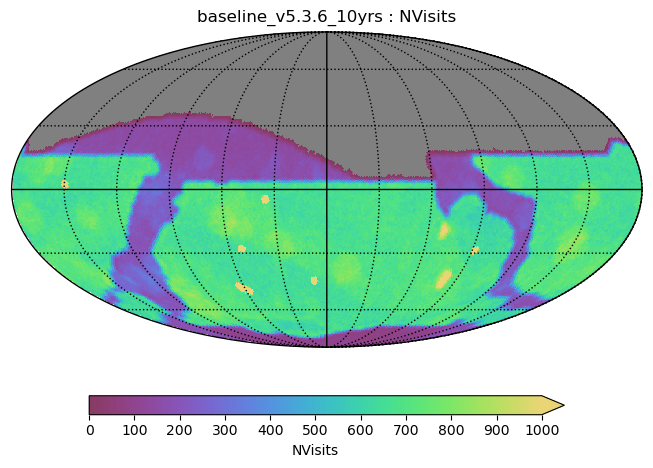

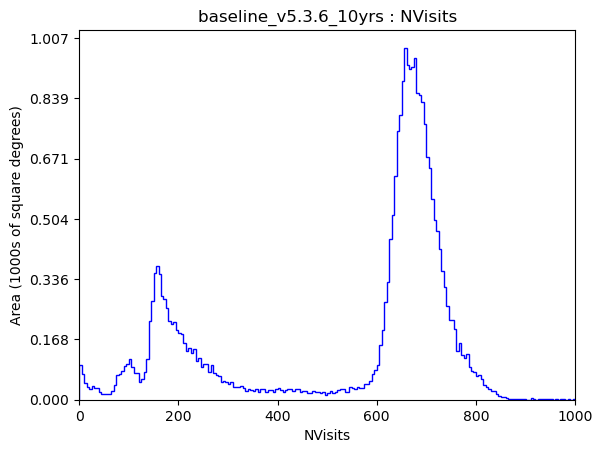

In [111]:
opsdb = 'baseline_v5.3.6_10yrs.db'
run_name = os.path.split(opsdb)[-1].replace('.db', '')

metric = maf.CountMetric('observationStartMJD', metric_name='NVisits')
slicer = maf.HealpixSlicer(nside=64)
constraint = None
plot_dict = {'color_min': 0, 'color_max': 1000, 'extend': 'max', 'x_min': 0, 'x_max': 1000}
plot_funcs = [maf.HealpixSkyMap(), maf.HealpixHistogram()]
bundle = maf.MetricBundle(metric, slicer, constraint, run_name=run_name, 
                          plot_dict=plot_dict, plot_funcs=plot_funcs)

metric = maf.CountMetric('observationStartMJD', metric_name='NVisits')
slicer = maf.HealpixSlicer(nside=64)
constraint = "night < 366"
plot_dict = {'color_min': 0, 'color_max': 100, 'extend': 'max', 'x_min': 0, 'x_max': 100}
plot_funcs = [maf.HealpixSkyMap(),]
bundle2 = maf.MetricBundle(metric, slicer, constraint, run_name=run_name, 
                          plot_dict=plot_dict, plot_funcs=plot_funcs)

try_read = True
if try_read:
    bundle.read(bundle.file_root + '.npz')
    bundle.set_plot_dict(plot_dict = {'color_min': 0, 'color_max': 1000, 'extend': 'max', 'x_min': 0, 'x_max': 1000})
    #bundle.set_plot_funcs(plot_funcs = [maf.HealpixSkyMap(),])
    bundle2.read(bundle2.file_root + '.npz')
    bundle2.set_plot_dict(plot_dict = {'color_min': 0, 'color_max': 100, 'extend': 'max', 'x_min': 0, 'x_max': 100, 'bins': 100})
    #bundle2.set_plot_funcs(plot_funcs = [maf.HealpixSkyMap(),])
else:
    g = maf.MetricBundleGroup({'nvisits': bundle, "year1": bundle2}, opsdb, verbose=True)
    g.run_all()

bundle.plot()

/Users/lynnej/lsst_repos/rubin_sim/rubin_sim/maf/utils/maf_utils.py:153: UserWarning: Optimal bin calculation tried to make 1759 bins, returning 200
  warnings.warn(


{'SkyMap': <Figure size 640x480 with 2 Axes>,
 'Histogram': <Figure size 640x480 with 1 Axes>}

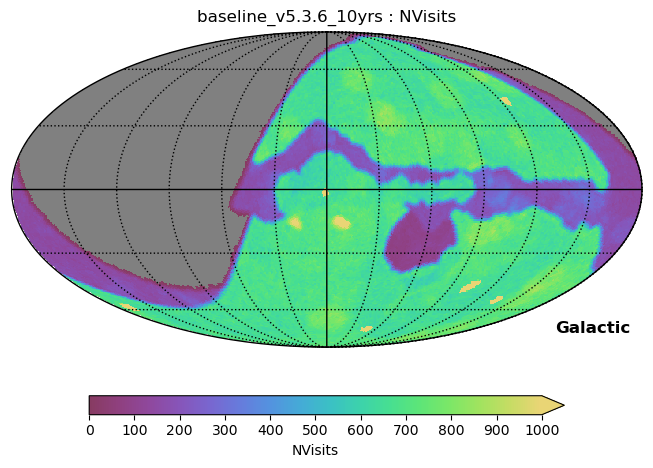

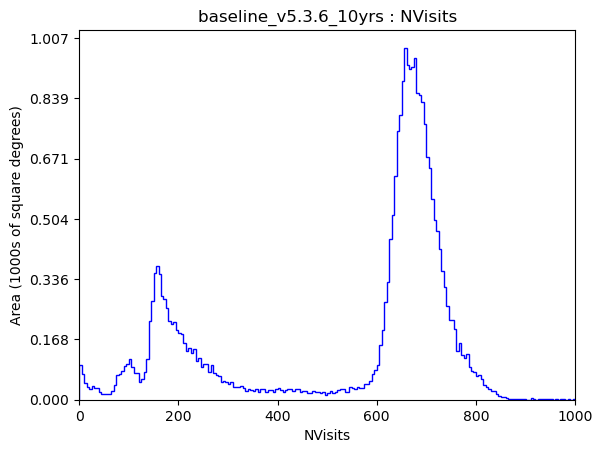

In [112]:
bundle.set_plot_dict(plot_dict = {'color_min': 0, 'color_max': 1000, 'extend': 'max', 'x_min': 0, 'x_max': 1000, 'coord': ['C', 'G']})
bundle.plot()

{'SkyMap': <Figure size 640x480 with 2 Axes>,
 'Histogram': <Figure size 640x480 with 1 Axes>}

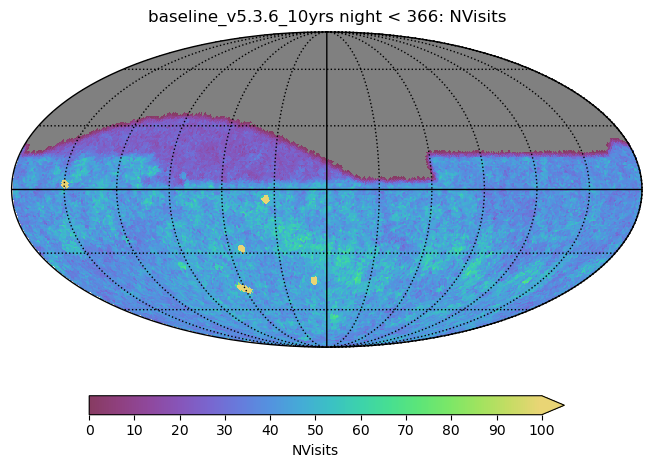

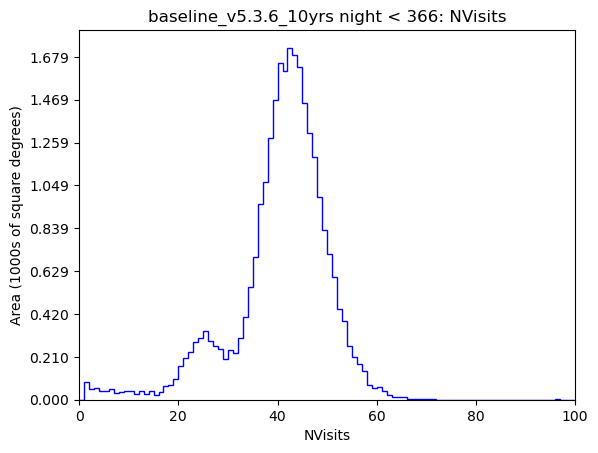

In [113]:
bundle2.plot()

Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Querying table None with no constraint for columns ['rotSkyPos', 'fieldRA', 'fieldDec', np.str_('observationStartMJD')].
Found 1817179 visits
Running:  ['nvisits']
Processing slices: 100%|███████████████| 49152/49152 [00:09<00:00, 5419.55it/s]
Completed metric generation.
Running reduce methods.
Running summary statistics.
Completed.
Querying table None with constraint night < 366 for columns ['rotSkyPos', 'fieldRA', 'fieldDec', np.str_('observationStartMJD')]
Found 139317 visits
Running:  ['year1']
Processing slices: 100%|██████████████| 49152/49152 [00:02<00:00, 18712.94it/s]
Completed metric generation.
Running reduce methods.
Running summary statistics.
Completed.


/Users/lynnej/lsst_repos/rubin_sim/rubin_sim/maf/utils/maf_utils.py:153: UserWarning: Optimal bin calculation tried to make 1400 bins, returning 200
  warnings.warn(


{'SkyMap': <Figure size 640x480 with 2 Axes>,
 'Histogram': <Figure size 640x480 with 1 Axes>}

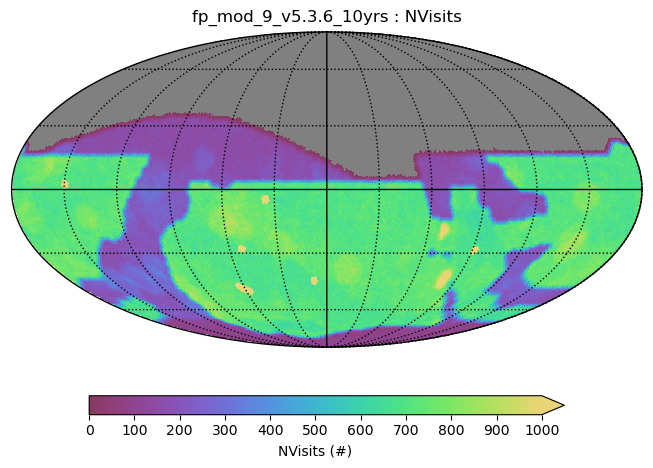

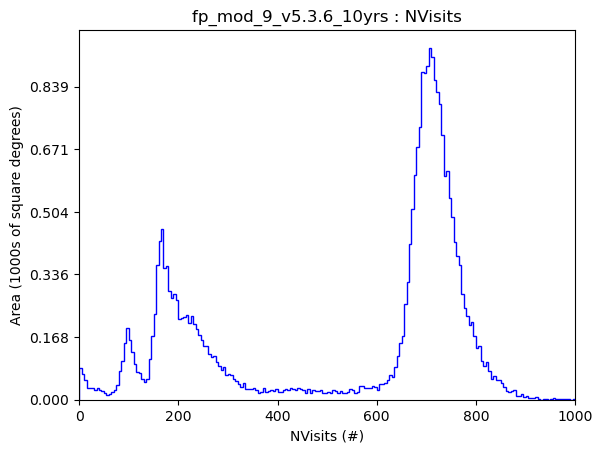

In [114]:
opsdb = 'fp_mod_9_v5.3.6_10yrs.db'
run_name = os.path.split(opsdb)[-1].replace('.db', '')

metric = maf.CountMetric('observationStartMJD', metric_name='NVisits')
slicer = maf.HealpixSlicer(nside=64)
constraint = None
plot_dict = {'color_min': 0, 'color_max': 1000, 'extend': 'max', 'x_min': 0, 'x_max': 1000}
plot_funcs = [maf.HealpixSkyMap(), maf.HealpixHistogram()]
fpbundle = maf.MetricBundle(metric, slicer, constraint, run_name=run_name, 
                          plot_dict=plot_dict, plot_funcs=plot_funcs)

metric = maf.CountMetric('observationStartMJD', metric_name='NVisits')
slicer = maf.HealpixSlicer(nside=64)
constraint = "night < 366"
plot_dict = {'color_min': 0, 'color_max': 100, 'extend': 'max', 'x_min': 0, 'x_max': 100}
plot_funcs = [maf.HealpixSkyMap(),]
fpbundle2 = maf.MetricBundle(metric, slicer, constraint, run_name=run_name, 
                          plot_dict=plot_dict, plot_funcs=plot_funcs)

try_read = False
if try_read:
    fpbundle.read(bundle.file_root + '.npz')
    fpbundle.set_plot_dict(plot_dict = {'color_min': 0, 'color_max': 1000, 'extend': 'max', 'x_min': 0, 'x_max': 1000})
    #fpbundle.set_plot_funcs(plot_funcs = [maf.HealpixSkyMap(),])
    fpbundle2.read(bundle2.file_root + '.npz')
    fpbundle2.set_plot_dict(plot_dict = {'color_min': 0, 'color_max': 100, 'extend': 'max', 'x_min': 0, 'x_max': 100, 'bins': 100})
    #fpbundle2.set_plot_funcs(plot_funcs = [maf.HealpixSkyMap(),])
else:
    g = maf.MetricBundleGroup({'nvisits': fpbundle, "year1": fpbundle2}, opsdb, verbose=True)
    g.run_all()

fpbundle.plot()

{'SkyMap': <Figure size 640x480 with 2 Axes>}

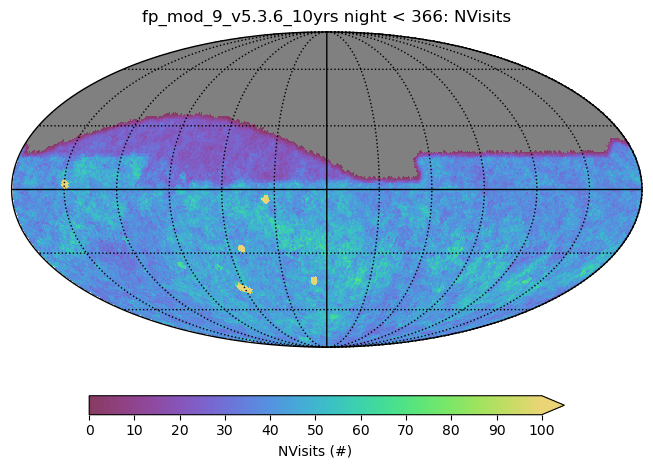

In [115]:
fpbundle2.plot()

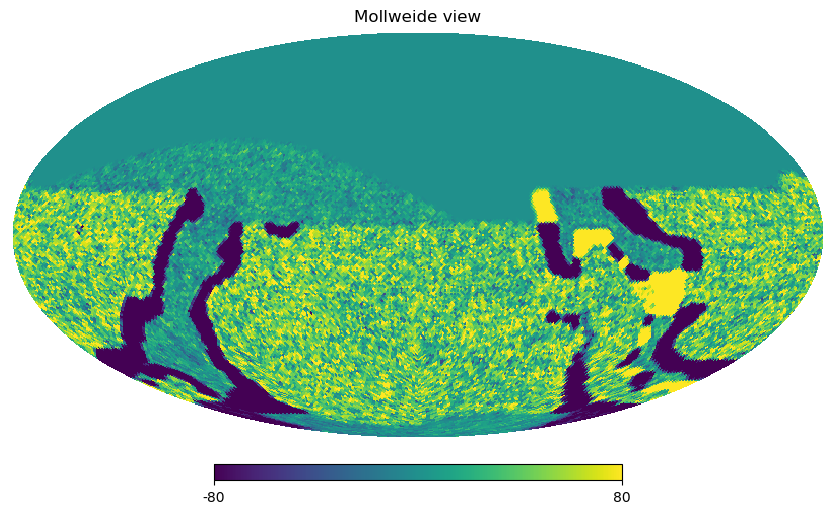

In [116]:
# What is the difference in the *first year* coverage between these two runs?
# -- note that the dusty plane coverage changes (the WFD is not cutting off an area of dusty plane in the new run)
mval = fpbundle.metric_values.filled(0) - bundle.metric_values.filled(0)
hp.mollview(mval, min=-80, max=80)

/Users/lynnej/lsst_repos/rubin_sim/rubin_sim/maf/utils/maf_utils.py:153: UserWarning: Optimal bin calculation tried to make 1400 bins, returning 200
  warnings.warn(


{'SkyMap': <Figure size 640x480 with 2 Axes>,
 'Histogram': <Figure size 640x480 with 1 Axes>}

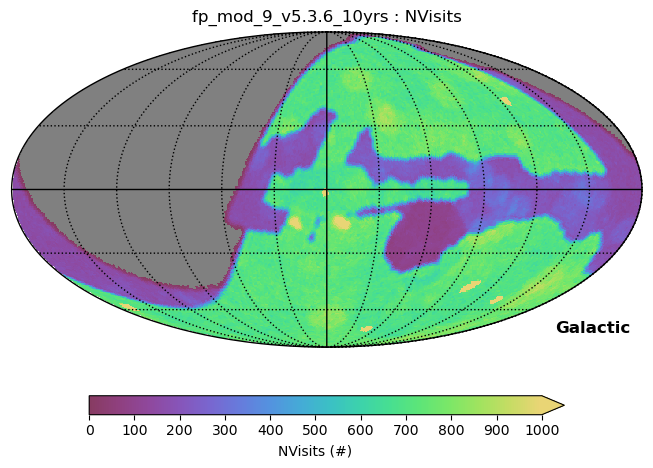

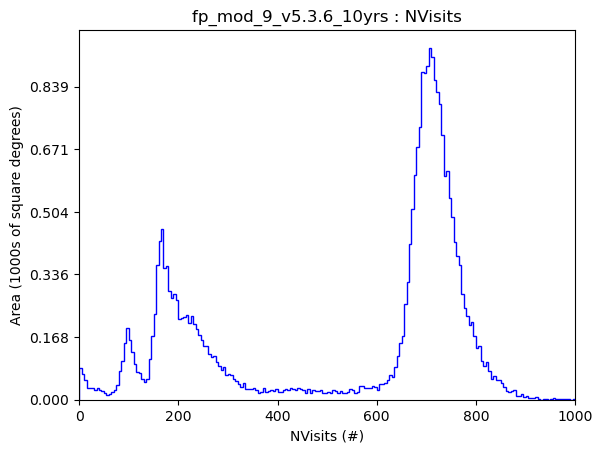

In [117]:
fpbundle.set_plot_dict(plot_dict = {'color_min': 0, 'color_max': 1000, 'extend': 'max', 'x_min': 0, 'x_max': 1000, 'coord': ['C', 'G']})
fpbundle.plot()

Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Querying table None with no constraint for columns ['rotSkyPos', 'fieldRA', 'fieldDec', np.str_('observationStartMJD')].
Found 1819587 visits
Running:  ['nvisits']
Processing slices: 100%|███████████████| 49152/49152 [00:09<00:00, 5439.43it/s]
Completed metric generation.
Running reduce methods.
Running summary statistics.
Completed.
Querying table None with constraint night < 366 for columns ['rotSkyPos', 'fieldRA', 'fieldDec', np.str_('observationStartMJD')]
Found 139161 visits
Running:  ['year1']
Processing slices: 100%|██████████████| 49152/49152 [00:02<00:00, 18871.13it/s]
Completed metric generation.
Running reduce methods.
Running summary statistics.
Completed.


/Users/lynnej/lsst_repos/rubin_sim/rubin_sim/maf/utils/maf_utils.py:153: UserWarning: Optimal bin calculation tried to make 1309 bins, returning 200
  warnings.warn(


{'SkyMap': <Figure size 640x480 with 2 Axes>,
 'Histogram': <Figure size 640x480 with 1 Axes>}

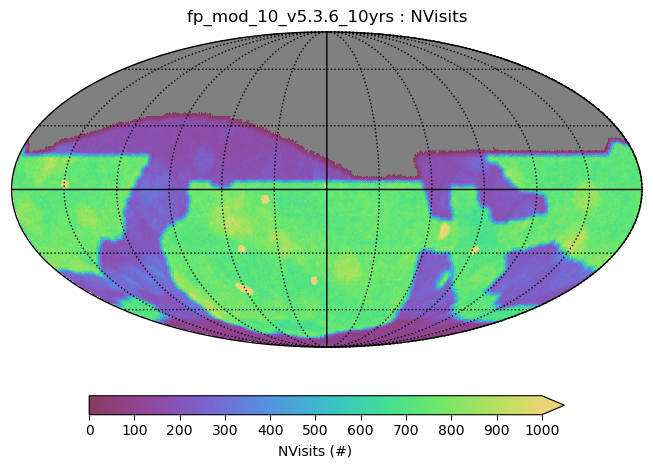

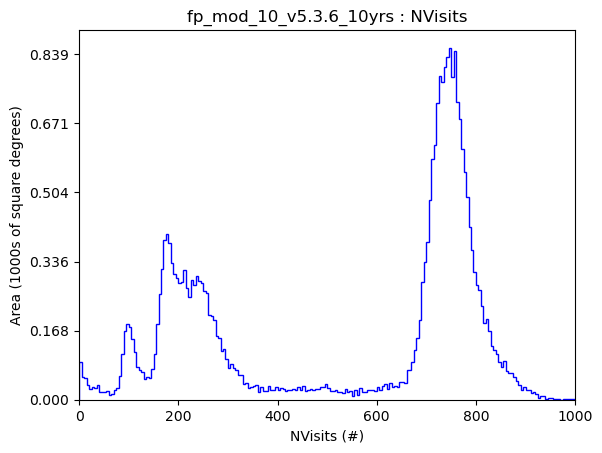

In [109]:
opsdb = 'fp_mod_10_v5.3.6_10yrs.db'
run_name = os.path.split(opsdb)[-1].replace('.db', '')

metric = maf.CountMetric('observationStartMJD', metric_name='NVisits')
slicer = maf.HealpixSlicer(nside=64)
constraint = None
plot_dict = {'color_min': 0, 'color_max': 1000, 'extend': 'max', 'x_min': 0, 'x_max': 1000}
plot_funcs = [maf.HealpixSkyMap(), maf.HealpixHistogram()]
fpbundle = maf.MetricBundle(metric, slicer, constraint, run_name=run_name, 
                          plot_dict=plot_dict, plot_funcs=plot_funcs)

metric = maf.CountMetric('observationStartMJD', metric_name='NVisits')
slicer = maf.HealpixSlicer(nside=64)
constraint = "night < 366"
plot_dict = {'color_min': 0, 'color_max': 100, 'extend': 'max', 'x_min': 0, 'x_max': 100}
plot_funcs = [maf.HealpixSkyMap(),]
fpbundle2 = maf.MetricBundle(metric, slicer, constraint, run_name=run_name, 
                          plot_dict=plot_dict, plot_funcs=plot_funcs)

try_read = False
if try_read:
    fpbundle.read(bundle.file_root + '.npz')
    fpbundle.set_plot_dict(plot_dict = {'color_min': 0, 'color_max': 1000, 'extend': 'max', 'x_min': 0, 'x_max': 1000})
    #fpbundle.set_plot_funcs(plot_funcs = [maf.HealpixSkyMap(),])
    fpbundle2.read(bundle2.file_root + '.npz')
    fpbundle2.set_plot_dict(plot_dict = {'color_min': 0, 'color_max': 100, 'extend': 'max', 'x_min': 0, 'x_max': 100, 'bins': 100})
    #fpbundle2.set_plot_funcs(plot_funcs = [maf.HealpixSkyMap(),])
else:
    g = maf.MetricBundleGroup({'nvisits': fpbundle, "year1": fpbundle2}, opsdb, verbose=True)
    g.run_all()

fpbundle.plot()

/Users/lynnej/lsst_repos/rubin_sim/rubin_sim/maf/utils/maf_utils.py:153: UserWarning: Optimal bin calculation tried to make 1309 bins, returning 200
  warnings.warn(


{'SkyMap': <Figure size 640x480 with 2 Axes>,
 'Histogram': <Figure size 640x480 with 1 Axes>}

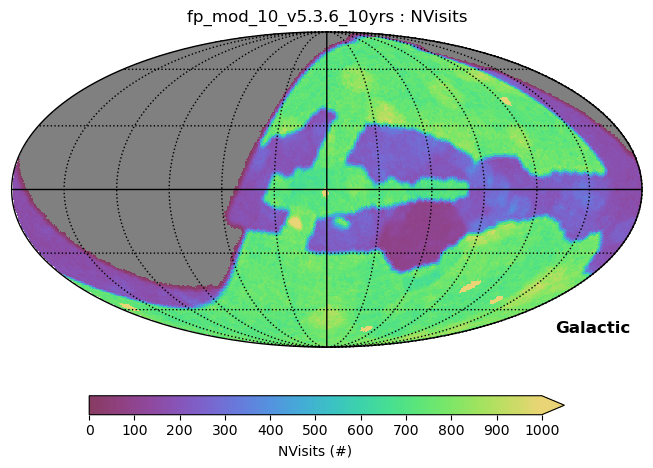

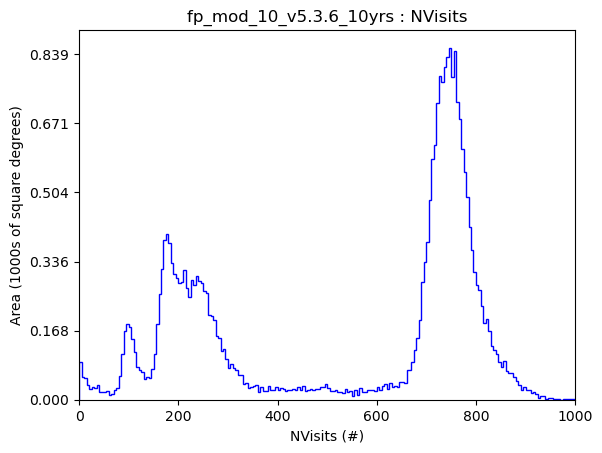

In [110]:
fpbundle.set_plot_dict(plot_dict = {'color_min': 0, 'color_max': 1000, 'extend': 'max', 'x_min': 0, 'x_max': 1000, 'coord': ['C', 'G']})
fpbundle.plot()

Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Querying table None with no constraint for columns ['rotSkyPos', 'fieldRA', 'fieldDec', np.str_('observationStartMJD')].
Found 1818612 visits
Running:  ['nvisits']
Processing slices: 100%|███████████████| 49152/49152 [00:09<00:00, 5334.67it/s]
Completed metric generation.
Running reduce methods.
Running summary statistics.
Completed.
Querying table None with constraint night < 366 for columns ['rotSkyPos', 'fieldRA', 'fieldDec', np.str_('observationStartMJD')]
Found 139388 visits
Running:  ['year1']
Processing slices: 100%|██████████████| 49152/49152 [00:02<00:00, 18918.15it/s]
Completed metric generation.
Running reduce methods.
Running summary statistics.
Completed.


/Users/lynnej/lsst_repos/rubin_sim/rubin_sim/maf/utils/maf_utils.py:153: UserWarning: Optimal bin calculation tried to make 1314 bins, returning 200
  warnings.warn(


{'SkyMap': <Figure size 640x480 with 2 Axes>,
 'Histogram': <Figure size 640x480 with 1 Axes>}

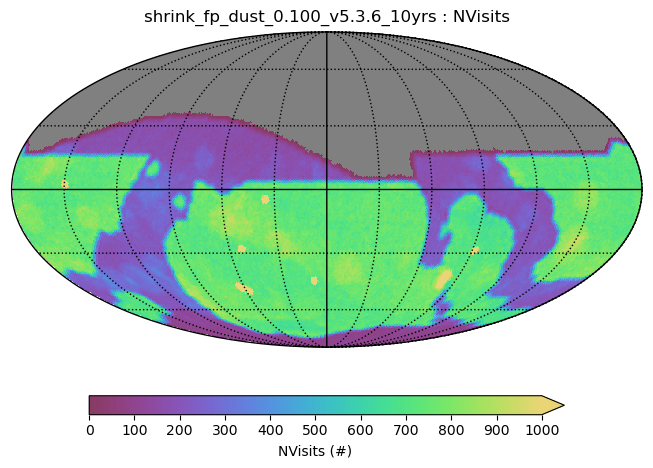

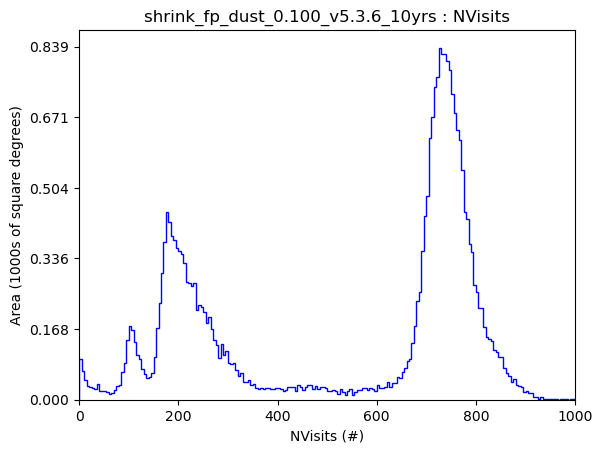

In [32]:
opsdb = 'shrink_fp_dust_0.100_v5.3.6_10yrs.db'
run_name = os.path.split(opsdb)[-1].replace('.db', '')

metric = maf.CountMetric('observationStartMJD', metric_name='NVisits')
slicer = maf.HealpixSlicer(nside=64)
constraint = None
plot_dict = {'color_min': 0, 'color_max': 1000, 'extend': 'max', 'x_min': 0, 'x_max': 1000}
plot_funcs = [maf.HealpixSkyMap(), maf.HealpixHistogram()]
fpbundle = maf.MetricBundle(metric, slicer, constraint, run_name=run_name, 
                          plot_dict=plot_dict, plot_funcs=plot_funcs)

metric = maf.CountMetric('observationStartMJD', metric_name='NVisits')
slicer = maf.HealpixSlicer(nside=64)
constraint = "night < 366"
plot_dict = {'color_min': 0, 'color_max': 100, 'extend': 'max', 'x_min': 0, 'x_max': 100}
plot_funcs = [maf.HealpixSkyMap(),]
fpbundle2 = maf.MetricBundle(metric, slicer, constraint, run_name=run_name, 
                          plot_dict=plot_dict, plot_funcs=plot_funcs)

try_read = False
if try_read:
    fpbundle.read(bundle.file_root + '.npz')
    fpbundle.set_plot_dict(plot_dict = {'color_min': 0, 'color_max': 1000, 'extend': 'max', 'x_min': 0, 'x_max': 1000})
    #fpbundle.set_plot_funcs(plot_funcs = [maf.HealpixSkyMap(),])
    fpbundle2.read(bundle2.file_root + '.npz')
    fpbundle2.set_plot_dict(plot_dict = {'color_min': 0, 'color_max': 100, 'extend': 'max', 'x_min': 0, 'x_max': 100, 'bins': 100})
    #fpbundle2.set_plot_funcs(plot_funcs = [maf.HealpixSkyMap(),])
else:
    g = maf.MetricBundleGroup({'nvisits': fpbundle, "year1": fpbundle2}, opsdb, verbose=True)
    g.run_all()

fpbundle.plot()

/Users/lynnej/lsst_repos/rubin_sim/rubin_sim/maf/utils/maf_utils.py:153: UserWarning: Optimal bin calculation tried to make 1314 bins, returning 200
  warnings.warn(


{'SkyMap': <Figure size 640x480 with 2 Axes>,
 'Histogram': <Figure size 640x480 with 1 Axes>}

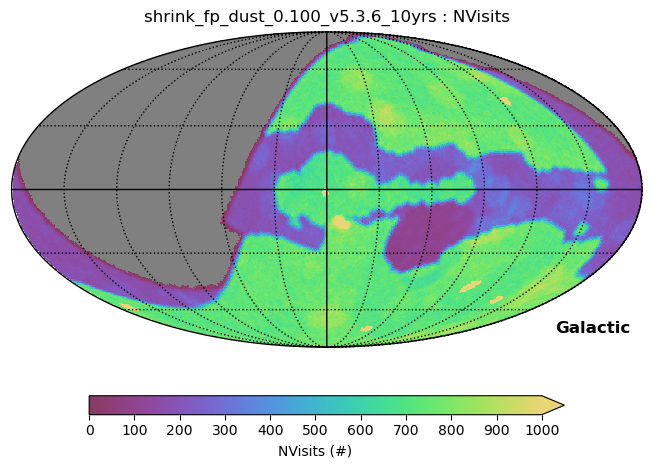

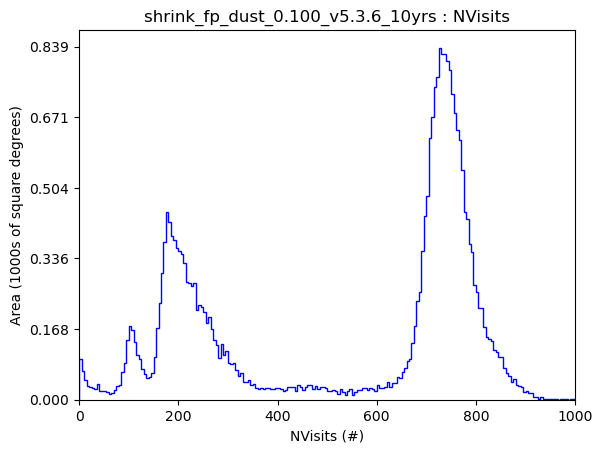

In [33]:
fpbundle.set_plot_dict(plot_dict = {'color_min': 0, 'color_max': 1000, 'extend': 'max', 'x_min': 0, 'x_max': 1000, 'coord': ['C', 'G']})
fpbundle.plot()

In [123]:
fO = {}
for run_name in runs:
    db = run_name + '.db'
    fO[run_name] = maf.fOBatch(run_name=run_name)
    g = maf.MetricBundleGroup(fO[run_name], db)
    g.run_all()

Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes


shrink_fp_dust_0.080_v5.3.6_10yrs 9737.777777777777 15474
shrink_fp_dust_0.100_v5.3.6_10yrs 4882.222222222222 15722
shrink_fp_dust_0.120_v5.3.6_10yrs 2893.333333333333 14605
baseline_v5.3.6_10yrs 1388.8888888888887 7237
fp_mod_6_v5.3.6_10yrs 2732.2222222222217 14196
fp_mod_9_v5.3.6_10yrs 2794.4444444444443 14273
fp_mod_10_v5.3.6_10yrs 5667.777777777778 16000


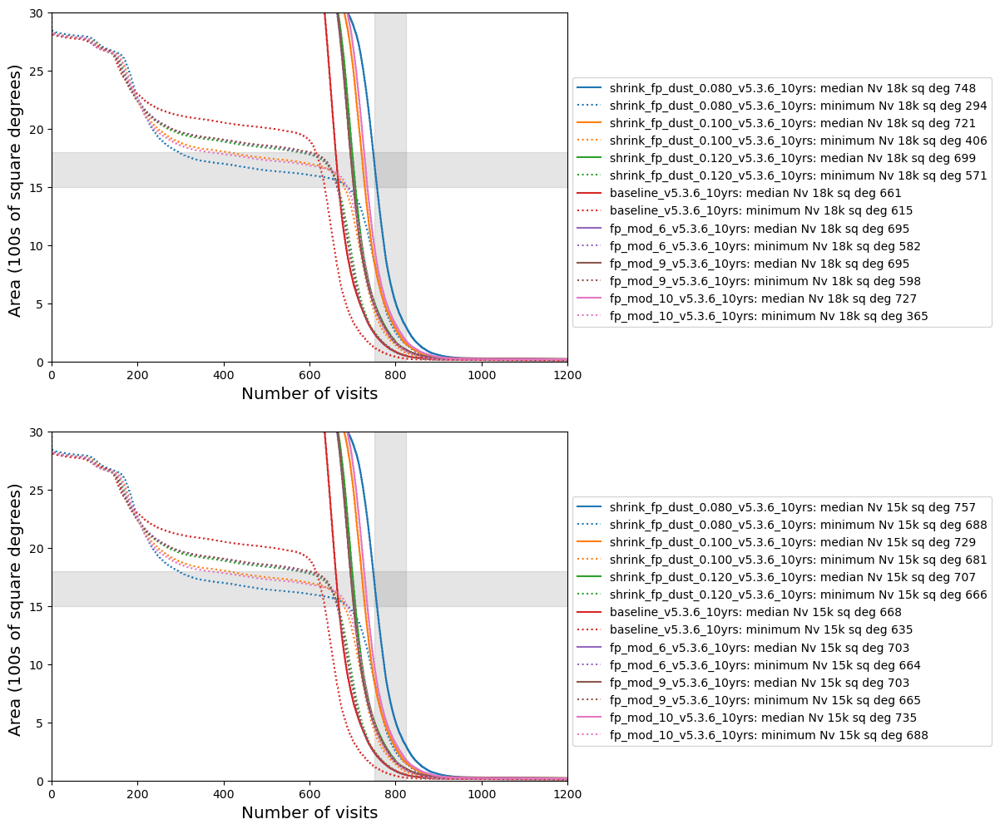

In [124]:
# 18k sq deg version
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(8, 12))
colors = colorcet.glasbey_category10

# scale = area (1k sq deg) / npix
name = runs[0]
bb = fO[name][f"{name.replace('.', '_')}_fO_All_visits_HEAL"]
scale = hp.nside2pixarea(bb.slicer.nside, degrees=True) / 1000.0
for count, name in enumerate(runs):
    bundle = fO[name][f"{name.replace('.', '_')}_fO_All_visits_HEAL"]
    nvis_sorted = np.sort(bundle.metric_values.filled(0))
    area = np.arange(30000, 0, -1)
    medianval = np.zeros(len(area))
    minval = np.zeros(len(area))
    for i, asky in enumerate(area):
        npix__asky = int(np.ceil(asky / hp.nside2pixarea(bundle.slicer.nside, degrees=True)))
        # Find the Asky's worth of healpixels with the largest # of visits.
        nvis__asky = nvis_sorted[-npix__asky :]
        #print(asky, npix__asky, nvis__asky[0], nvis__asky[-1], np.min(nvis__asky), np.max(nvis__asky), np.median(nvis__asky))
        medianval[i] = np.median(nvis__asky)
        minval[i] = np.min(nvis__asky)
    idx_15k = np.where(abs(area - 15000) < 0.001)[0]
    idx_18k = np.where(abs(area - 18000) < 0.001)[0]
    idx_750 = np.where(minval >= 750)[0][0]
    idx_670 = np.where(minval >= 670)[0][0]
    print(name, area[idx_750] * 0.9 / 0.81, area[idx_670])
    axes[0].plot(medianval, area/1000, color=colors[count], linestyle='-', label=f"{name}: median Nv 18k sq deg {medianval[idx_18k].item():.0f}")
    axes[0].plot(minval, area/1000, linestyle=':', color=colors[count], label=f"{name}: minimum Nv 18k sq deg {minval[idx_18k].item():.0f}")
    axes[1].plot(medianval, area/1000, color=colors[count], linestyle='-', label=f"{name}: median Nv 15k sq deg {medianval[idx_15k].item():.0f}")
    axes[1].plot(minval, area/1000, linestyle=':', color=colors[count], label=f"{name}: minimum Nv 15k sq deg {minval[idx_15k].item():.0f}")

for ax in axes:
    ax.legend(loc=(1.01, 0.1))
    ax.fill_between([750, 825], y1=[0], y2=[30], color='gray', alpha=0.2)
    ax.fill_betweenx([15, 18], x1=[0], x2=[1200], color='gray', alpha=0.2)
    ax.set_xlim(0, 1200)
    ax.set_ylim(0, 30)
    ax.set_xlabel("Number of visits", fontsize='x-large')
    ax.set_ylabel("Area (100s of square degrees) ", fontsize='x-large')
#plt.savefig("area_nvis.png", bbox_inches='tight')

In [40]:
## PSTN-057 version
# runs = list(rdict.keys())
# runs = ['baseline_v3.0_10yrs', 'baseline_v3.6_10yrs', 'baseline_v4.0_10yrs', 
#         'baseline_v5.0.1_10yrs', 'baseline_v5.1.2_10yrs', 
#         'comp_survey_v5.3.0_10yrs', 'baseline_v5.3.1_10yrs', 'faster_templates_v5.3.0_10yrs', 'baseline_v5.3.0_11yrs']
# msub = metrics.loc['SCOC']
# baseline = 'baseline_v5.3.1_10yrs'


# fig, ax = maf.plot_run_metric_mesh(summaries.loc[runs, msub['metric']], 
#                      baseline_run=baseline,
#                      metric_subset=msub,
#                         metric_label_map=msub['short_name'],
#                         run_label_map=rdict,
#                         color_range=0.4,
#                       )
# fig.set_figwidth(8)
# fig.set_figheight(8)
# fig.savefig(os.path.join(outdir, 'scoc_grid'+ '.png'), format='png', bbox_inches='tight')

In [41]:
summaries.loc[runs, [c for c in summaries.columns if "Median Median" in c and "Healpix" in c and 'all bands' in c]].round(3)

metric,Median Median HA All sky all bands HealpixSlicer,Median Median HA WFD all bands HealpixSubsetSlicer,Median Median Inter-Night Gap All sky all bands HealpixSlicer,Median Median Inter-Night Gap WFD all bands HealpixSubsetSlicer,Median Median Season Length All sky all bands HealpixSlicer,Median Median Season Length WFD all bands HealpixSubsetSlicer,Median Median airmass All sky all bands HealpixSlicer,Median Median airmass WFD all bands HealpixSubsetSlicer,Median Median airmass Yr 1 all bands HealpixSlicer,Median Median fiveSigmaDepth All sky all bands HealpixSlicer,...,Median Median saturation_mag WFD all bands HealpixSubsetSlicer,Median Median seeingEff All sky all bands HealpixSlicer,Median Median seeingEff WFD all bands HealpixSubsetSlicer,Median Median seeingEff Yr 1 all bands HealpixSlicer,Median Median seeingGeom Yr 1 all bands HealpixSlicer,Median Median skyBrightness All sky all bands HealpixSlicer,Median Median skyBrightness WFD all bands HealpixSubsetSlicer,Median Median skyBrightness Yr 1 all bands HealpixSlicer,Median Median solarElong All sky all bands HealpixSlicer,Median Median solarElong WFD all bands HealpixSubsetSlicer
run,,,,,,,,,,,,,,,,,,,,,
shrink_fp_dust_0.080_v5.3.6_10yrs,0.092,0.040,3.951,3.006,162.684,177.686,1.168,1.140,1.129,23.411,...,14.947,1.055,1.037,0.978,0.856,19.861,19.786,20.058,126.821,126.369
shrink_fp_dust_0.100_v5.3.6_10yrs,0.102,0.054,3.897,3.014,163.685,175.172,1.160,1.132,1.130,23.408,...,14.953,1.051,1.032,0.977,0.855,19.861,19.797,20.076,127.566,126.802
shrink_fp_dust_0.120_v5.3.6_10yrs,0.113,0.060,3.882,3.032,163.736,175.729,1.157,1.127,1.128,23.406,...,14.947,1.047,1.028,0.972,0.851,19.856,19.792,20.102,127.230,126.586
shrink_fp_dust_0.199_v5.3.6_10yrs,0.152,0.098,3.916,3.123,166.268,176.804,1.151,1.121,1.127,23.405,...,14.944,1.046,1.026,0.973,0.852,19.846,19.779,20.112,127.324,126.745
baseline_v5.3.6_10yrs,0.129,0.090,3.897,3.081,165.722,176.699,1.151,1.120,1.127,23.404,...,14.940,1.041,1.024,0.974,0.853,19.848,19.779,20.064,127.541,126.829
fp_mod_8_v5.3.6_10yrs,0.055,-0.012,3.886,3.026,163.704,175.666,1.158,1.130,1.129,23.411,...,14.939,1.046,1.029,0.974,0.853,19.847,19.777,20.078,127.238,126.368
fp_mod_9_v5.3.6_10yrs,0.103,0.032,3.885,3.031,163.004,176.209,1.157,1.125,1.128,23.412,...,14.944,1.047,1.028,0.976,0.855,19.852,19.791,20.103,127.366,126.572


metric,Median CoaddM5 WFD u band HealpixSubsetSlicer,Median CoaddM5 WFD g band HealpixSubsetSlicer,Median CoaddM5 WFD r band HealpixSubsetSlicer,Median CoaddM5 WFD i band HealpixSubsetSlicer,Median CoaddM5 WFD z band HealpixSubsetSlicer,Median CoaddM5 WFD y band HealpixSubsetSlicer,Mean Median fiveSigmaDepth WFD u band HealpixSubsetSlicer,Mean Median fiveSigmaDepth WFD g band HealpixSubsetSlicer,Mean Median fiveSigmaDepth WFD r band HealpixSubsetSlicer,Mean Median fiveSigmaDepth WFD i band HealpixSubsetSlicer,Mean Median fiveSigmaDepth WFD z band HealpixSubsetSlicer,Mean Median fiveSigmaDepth WFD y band HealpixSubsetSlicer,Median NVisits WFD u band HealpixSubsetSlicer,Median NVisits WFD g band HealpixSubsetSlicer,Median NVisits WFD r band HealpixSubsetSlicer,Median NVisits WFD i band HealpixSubsetSlicer,Median NVisits WFD z band HealpixSubsetSlicer,Median NVisits WFD y band HealpixSubsetSlicer
run,,,,,,,,,,,,,,,,,,
shrink_fp_dust_0.080_v5.3.6_10yrs,25.55,26.97,26.92,26.42,25.74,24.75,23.43,24.60,24.06,23.53,22.96,22.05,50.0,66.0,169.0,172.0,151.0,146.0
shrink_fp_dust_0.100_v5.3.6_10yrs,25.55,26.98,26.92,26.42,25.74,24.74,23.43,24.62,24.07,23.55,22.97,22.04,48.0,64.0,164.0,167.0,146.0,141.0
shrink_fp_dust_0.120_v5.3.6_10yrs,25.56,26.96,26.92,26.42,25.74,24.76,23.44,24.61,24.08,23.56,22.98,22.05,47.0,63.0,160.0,162.0,142.0,138.0
shrink_fp_dust_0.199_v5.3.6_10yrs,25.55,26.95,26.92,26.41,25.73,24.75,23.44,24.61,24.09,23.58,22.99,22.05,45.0,60.0,153.0,155.0,134.0,131.0
baseline_v5.3.6_10yrs,25.55,26.95,26.92,26.41,25.73,24.76,23.44,24.62,24.09,23.58,22.99,22.06,45.0,60.0,153.0,155.0,134.0,131.0
fp_mod_8_v5.3.6_10yrs,25.56,26.95,26.92,26.43,25.74,24.76,23.43,24.60,24.07,23.57,22.98,22.05,47.0,63.0,160.0,162.0,142.0,138.0
fp_mod_9_v5.3.6_10yrs,25.56,26.96,26.92,26.42,25.74,24.75,23.44,24.61,24.08,23.56,22.98,22.05,47.0,62.0,159.0,161.0,141.0,137.0


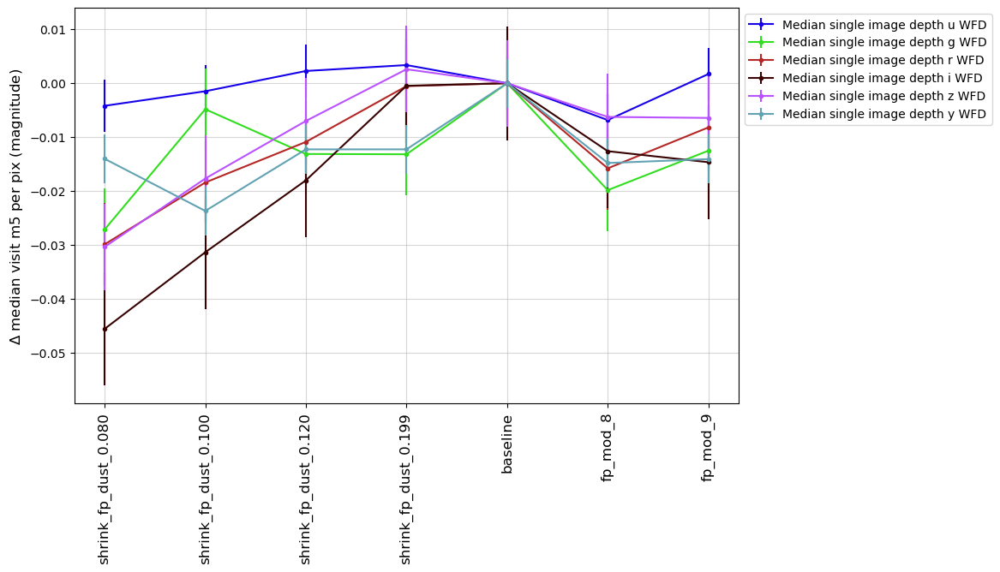

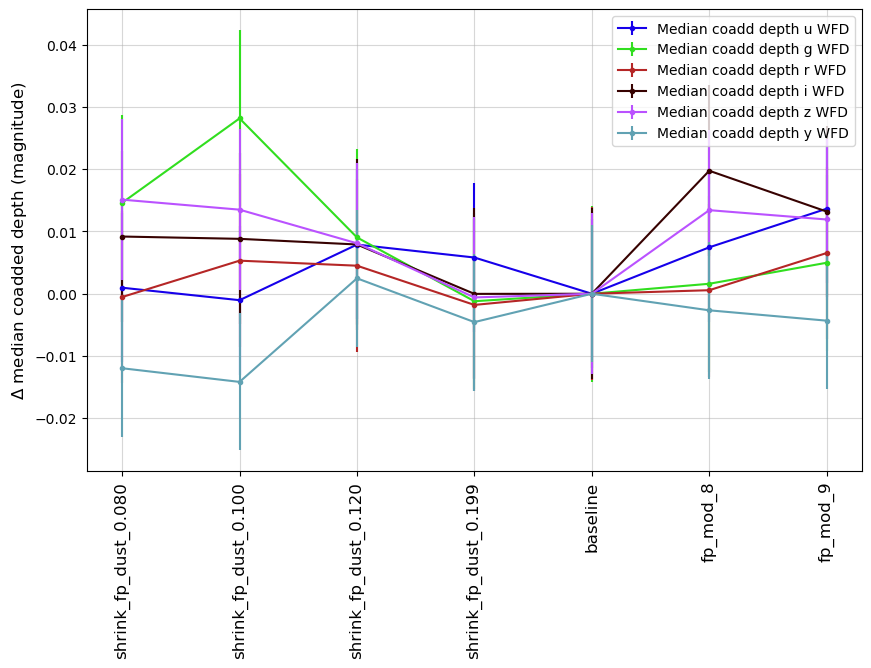

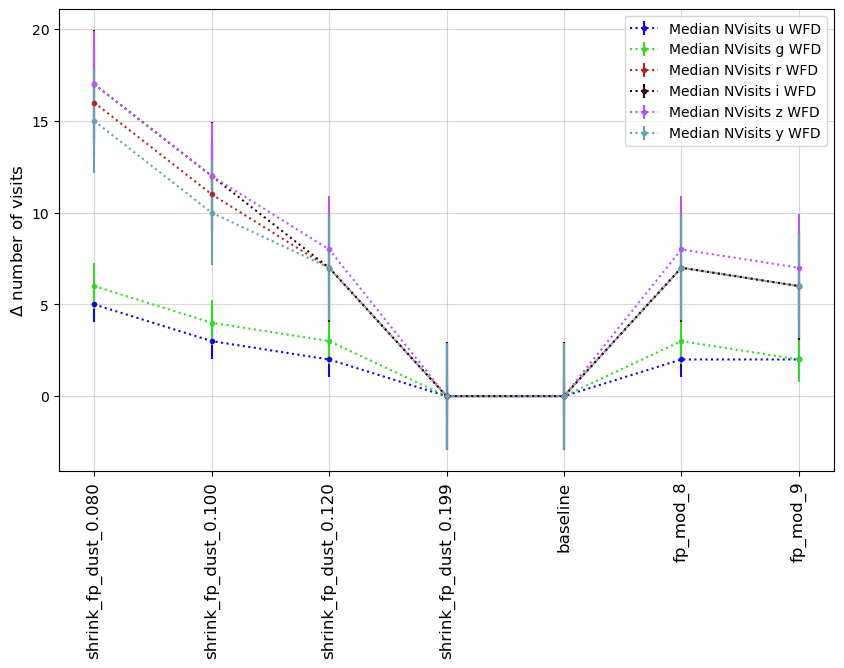

In [44]:
# Check in on the depths and number of visits in each bandpass
k = 'WFD Depths'

msub = metrics.loc[k].query('metric.str.contains("Mean Median")')
fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']] - summaries.loc[baseline, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub,
                                 cmap=filter_color_map,
                                 sep_plots=False)
ax.set_ylabel(r"$\Delta$ median visit m5 per pix (magnitude)", fontsize='large')
y1, y2 = plt.ylim()
fig.savefig(os.path.join(outdir, 'visit_m5_per_pix' + '.png'), format='png')


msub = metrics.loc[k].query('metric.str.contains("Coadd")')
fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']] - summaries.loc[baseline, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub,
                                 cmap=filter_color_map,
                                 sep_plots=False)
ax.set_ylabel(r"$\Delta$ median coadded depth (magnitude)", fontsize='large')
y1, y2 = plt.ylim()
fig.savefig(os.path.join(outdir, 'coadd_m5_per_pix' + '.png'), format='png')

msub = metrics.loc[k].query('metric.str.contains("NVisits")')
fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']] - summaries.loc[baseline, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub,
                                 cmap=filter_color_map,
                                 sep_plots=False)
ax.set_ylabel(r"$\Delta$ number of visits", fontsize='large')
y1, y2 = plt.ylim()
fig.savefig(os.path.join(outdir, 'nvisit_per_pix'+ '.png'), format='png')

summaries.loc[runs, metrics.loc[k]['metric']].round(2)

In [46]:
cols = [m for m in summaries if "Teff All sky all bands" in m and "UniSlicer" in m and "Normalized" not in m]
cols

d = summaries.loc[runs, cols]/summaries.loc[baseline, cols]
d = d.rename(columns={'Identity Total Teff All sky all bands UniSlicer': "Teff Total"})
d.round(2)

metric,Teff Total
run,
shrink_fp_dust_0.080_v5.3.6_10yrs,0.96
shrink_fp_dust_0.100_v5.3.6_10yrs,0.98
shrink_fp_dust_0.120_v5.3.6_10yrs,0.98
shrink_fp_dust_0.199_v5.3.6_10yrs,1.00
baseline_v5.3.6_10yrs,1.00
fp_mod_8_v5.3.6_10yrs,0.99
fp_mod_9_v5.3.6_10yrs,0.99


And finally, let's have a look at those depths compared to SRD design and minimum goals, to evaluate how these changes are redistributing depth (or, in a sense, time) among bandpasses.

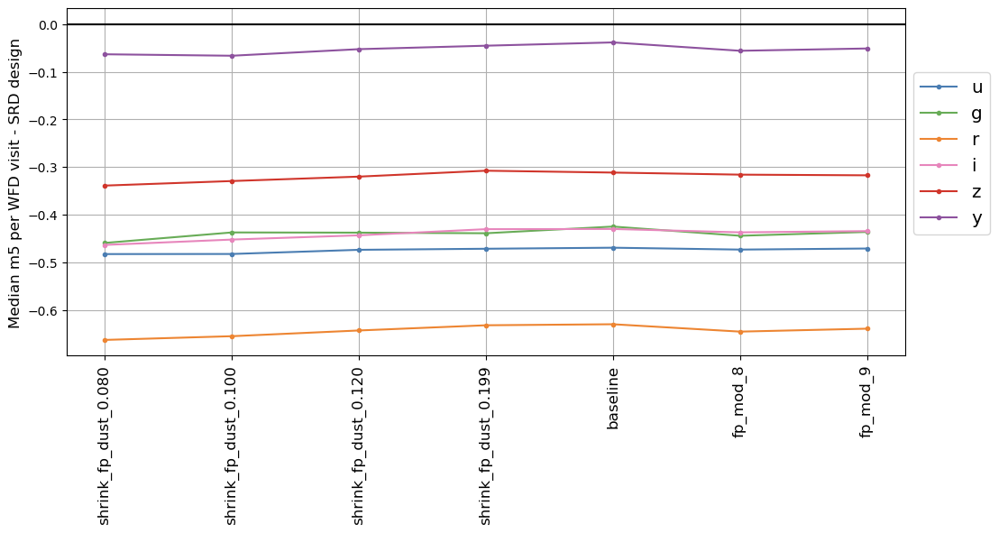

In [48]:
cols = [f'Identity Median fiveSigmaDepth WFD {f} band UniSlicer' for f in 'ugrizy']
newcols = [f'Median m5 WFD {f} band per image' for f in 'ugrizy']
visitdepth_cols = cols

mset = maf.create_metric_subset('VisitDepths', metrics=cols, short_name=newcols, invert=False, mag=True) 

fig, ax = plt.subplots(figsize=(12, 5)) 

for f, col in zip(['u', 'g', 'r', 'i', 'z', 'y'], cols):
    ax.plot(list(rdict.values()), summaries.loc[rdict.keys(), col] - m5_SRD_design[f], 
                color=filter_rgb_map[f], marker='.', linestyle='-', label=f)
    #ax.axhline(m5_SRD_design[f], color=filter_colors[f], linestyle=':', linewidth=3)

ax.axhline(0, color='k', linestyle='-')
ax.set_ylabel(f"Median m5 per WFD visit - SRD design", fontsize='large')
plt.legend(loc=(1.01, 0.35), fontsize='x-large')
ax.tick_params(axis='x', labelrotation = 90, labelsize='large')
ax.grid()
fig.savefig(os.path.join(outdir, 'm5_per_visit'+ '.png'), format='png')

In [125]:
## WFD coadd vs. exgal coadd depths 

k = 'WFD Depths'

msub = metrics.loc[k].query('metric.str.contains("Coadd")')
q1 = summaries.loc[runs, msub['metric']]
names = {}
for m in msub['metric']:
    names[m] = m.split(" band")[0][-1:]
q1 = q1.rename(columns=names)

mm = [f"Median Exgal_CoaddM5 WFD {f} band HealpixSubsetSlicer" for f in 'ugrizy']
q2 = summaries.loc[runs, mm]
names = {}
for m in metrics:
    names[m] = m.split(" band")[0][-1:]
q2= q2.rename(columns=names)


summaries.loc[runs, mm].round(2)

metric,Median Exgal_CoaddM5 WFD u band HealpixSubsetSlicer,Median Exgal_CoaddM5 WFD g band HealpixSubsetSlicer,Median Exgal_CoaddM5 WFD r band HealpixSubsetSlicer,Median Exgal_CoaddM5 WFD i band HealpixSubsetSlicer,Median Exgal_CoaddM5 WFD z band HealpixSubsetSlicer,Median Exgal_CoaddM5 WFD y band HealpixSubsetSlicer
run,,,,,,
shrink_fp_dust_0.080_v5.3.6_10yrs,25.33,26.73,26.74,26.30,25.63,24.69
shrink_fp_dust_0.100_v5.3.6_10yrs,25.31,26.73,26.75,26.30,25.63,24.68
shrink_fp_dust_0.120_v5.3.6_10yrs,25.30,26.71,26.75,26.29,25.62,24.69
baseline_v5.3.6_10yrs,25.27,26.70,26.72,26.27,25.60,24.68
fp_mod_6_v5.3.6_10yrs,25.30,26.71,26.74,26.29,25.63,24.68
fp_mod_9_v5.3.6_10yrs,25.30,26.71,26.75,26.29,25.63,24.69
fp_mod_10_v5.3.6_10yrs,25.32,26.73,26.74,26.30,25.63,24.69


## Evaluate metrics

Let's evaluate some metric results across these baseline surveys, starting with a very high level overview. 

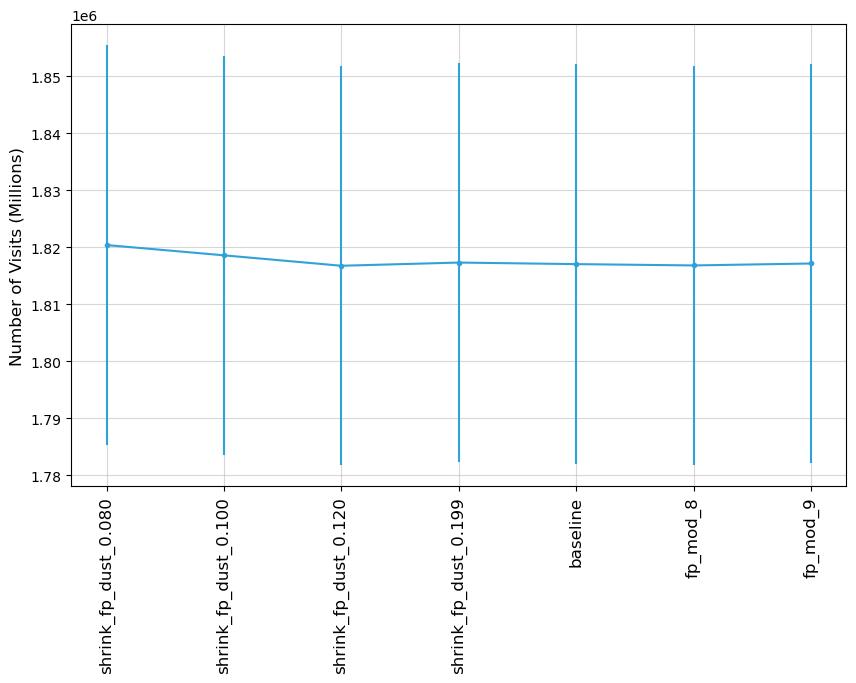

In [61]:
# How did the overall number of visits change for each simulation baseline?  Note some simulations include more shorter visits, and this will be reflected in these numbers.

cols = [m for m in summaries if "Nvisits" in m and "UniSlicer" in m and 'All' in m]
cols

#cols = ['Sum young_stars HealpixSlicer']

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, cols],
                                 dev[cols],
                                 run_label_map=rdict)
ax.set_ylabel(f"Number of Visits (Millions)", fontsize='large')
leg = ax.get_legend()
leg.remove()
#fig.savefig(os.path.join(outdir, 'total_nvisits'+ '.png'), format='png')

#summaries.loc[runs, cols] / summaries.loc['comp_survey_v5.3.0_10yrs', cols]

### SCOC subsets
<a id='SCOC'></a>
A high level overview in a mesh grid, to compare many metrics quickly but without details. 

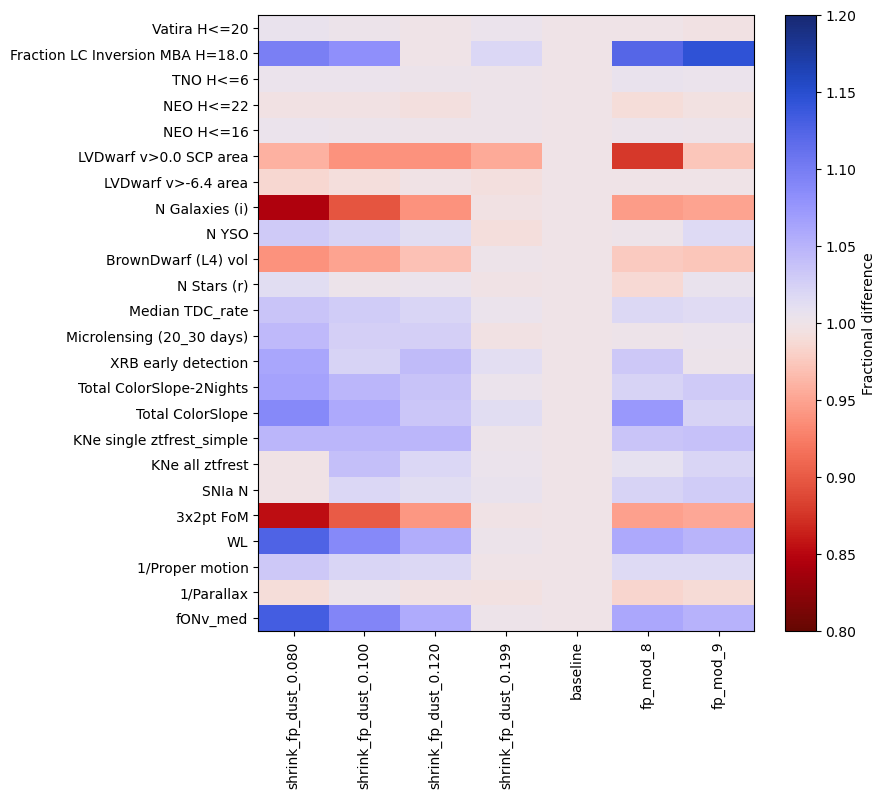

In [62]:
# What about the SCOC high-level overview? 

msub = metrics.loc['SCOC']

fig, ax = maf.plot_run_metric_mesh(summaries.loc[runs, msub['metric']], 
                     baseline_run=baseline,
                     metric_subset=msub,
                        metric_label_map=msub['short_name'],
                        run_label_map=rdict,
                        color_range=0.4,
                      )
fig.set_figwidth(8)
fig.set_figheight(8)
fig.savefig(os.path.join(outdir, 'scoc_grid'+ '.png'), format='png')

['shrink_fp_dust_0.080_v5.3.6_10yrs', 'shrink_fp_dust_0.100_v5.3.6_10yrs', 'shrink_fp_dust_0.120_v5.3.6_10yrs', 'shrink_fp_dust_0.199_v5.3.6_10yrs', 'baseline_v5.3.6_10yrs', 'fp_mod_8_v5.3.6_10yrs', 'fp_mod_9_v5.3.6_10yrs']


metric,SNIa N,KNe all ztfrest,KNe single ztfrest_simple,Total ColorSlope,Total ColorSlope-2Nights,XRB early detection,Microlensing (20_30 days),Median TDC_rate,NEO H<=16,NEO H<=22,TNO H<=6,Fraction LC Inversion MBA H=18.0,Vatira H<=20
run,,,,,,,,,,,,,
shrink_fp_dust_0.080_v5.3.6_10yrs,0.998025,0.997998,1.047276,1.088151,1.065141,1.061579,1.044387,1.035373,1.003363,0.996830,1.004340,1.097192,1.005535
shrink_fp_dust_0.100_v5.3.6_10yrs,1.019336,1.040320,1.047276,1.058276,1.047987,1.023158,1.026346,1.029036,1.002522,0.995579,1.003329,1.082073,1.002664
shrink_fp_dust_0.120_v5.3.6_10yrs,1.013225,1.019731,1.047051,1.034292,1.036804,1.043158,1.025200,1.021772,1.001051,0.992815,1.001946,1.000000,0.999105
shrink_fp_dust_0.199_v5.3.6_10yrs,1.005443,1.004003,1.001576,1.013502,1.004674,1.011579,0.996277,1.003368,1.000420,1.000396,1.001335,1.019438,1.003940
baseline_v5.3.6_10yrs,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
fp_mod_8_v5.3.6_10yrs,1.022544,1.008293,1.034669,1.073443,1.023114,1.032105,1.000573,1.018260,1.001681,0.989369,1.005523,1.123110,0.999577
fp_mod_9_v5.3.6_10yrs,1.029551,1.021447,1.037596,1.022981,1.031001,1.002632,1.003723,1.014174,1.000420,0.995267,1.004685,1.144708,0.996517


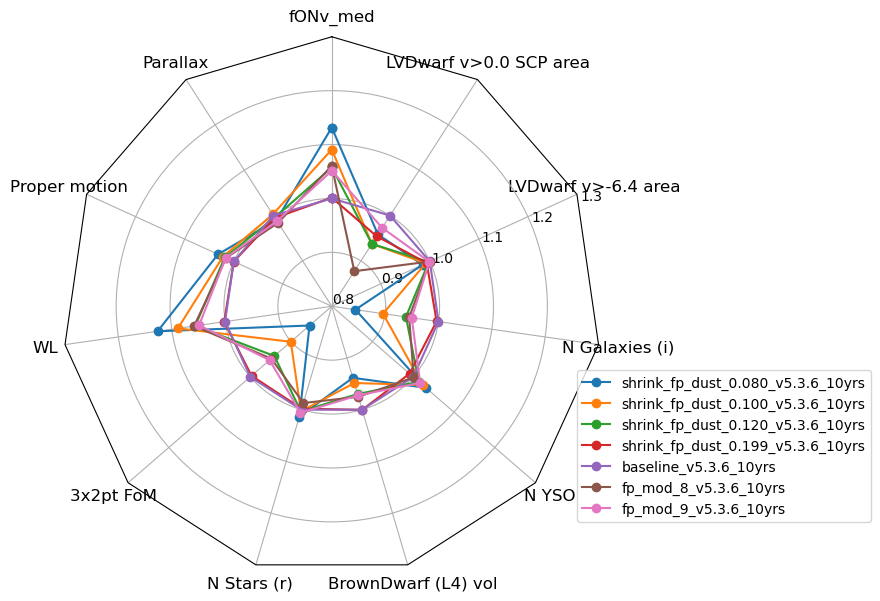

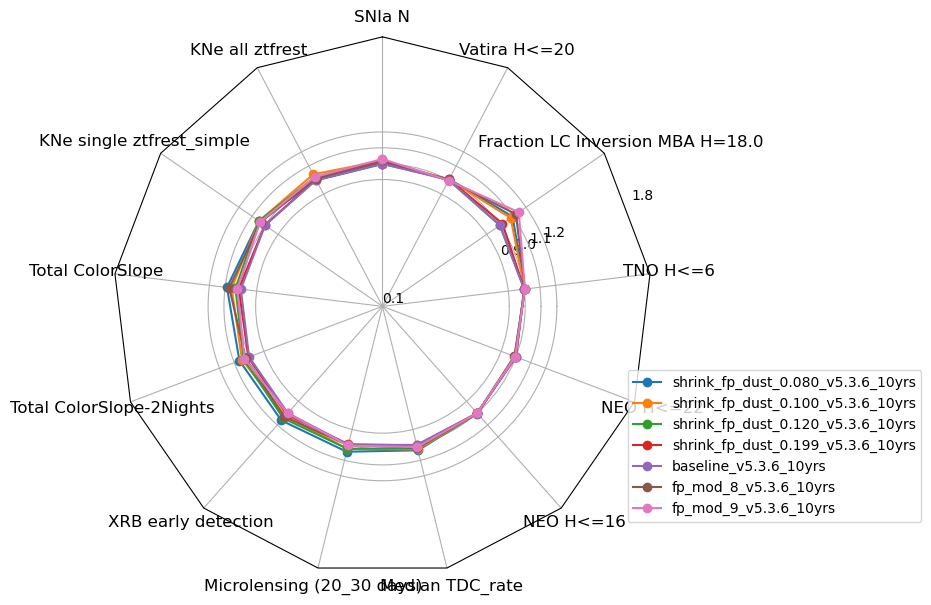

In [63]:
# And some classic 'radar' plots, but only use a subset of the baseline runs
rr = runs
rbaseline = baseline
print(rr)

mset = msub

statics = np.array([0, 1, 2, 3, 4, 13, 14, 15, 16, 17, 18])
variable = [i for i in np.arange(0, len(mset)) if i not in statics]

mset_stat = mset.iloc[statics]
mset_var = mset.iloc[variable]

normed = maf.normalize_metric_summaries(rbaseline,
                                        summaries.loc[rr, mset_stat['metric']],
                                        mset)
normed.columns = normed.columns.map(mset['short_name'])
normed

fig, ax = maf.radar(normed, rgrids=[0.80, 0.9, 1.0, 1.1, 1.2, 1.3], figsize=(8, 8), bbox_to_anchor=[1.5, 0.1])
ax.tick_params(axis='x', labelsize='large')
ax.tick_params(axis='y', labelsize='medium')
fig.set_figwidth(8)
fig.set_figheight(7)


normed = maf.normalize_metric_summaries(rbaseline,
                                        summaries.loc[rr, mset_var['metric']],
                                        mset)
normed.columns = normed.columns.map(mset['short_name'])
normed

fig, ax = maf.radar(normed, rgrids=[0.10, 0.9, 1.0, 1.1, 1.2, 1.8], figsize=(8, 8), bbox_to_anchor=[1.5, 0.1])
ax.tick_params(axis='x', labelsize='large')
ax.tick_params(axis='y', labelsize='medium')
fig.set_figwidth(8)
fig.set_figheight(7)
normed.loc[rr]

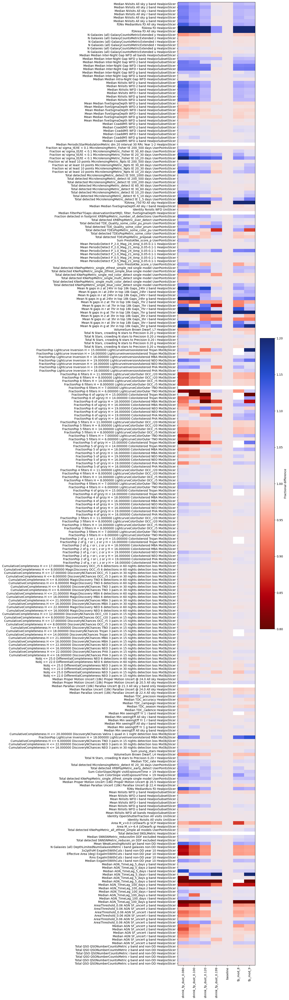

In [66]:
# Plot all the metrics, resulting in a very big and messy plot. Look at overall trends, or for things to investigate further.
non_dd = [m for m in msets if ('DD' not in m)]
msub = metrics.loc[non_dd].reset_index(drop=True).drop('style', axis=1).drop('short_name', axis=1)
msub = msub.drop_duplicates().set_index('metric', drop=False)

fig, ax = maf.plot_run_metric_mesh(summaries.loc[runs, msub['metric']], 
                     baseline_run=baseline,
                     metric_subset=msub,
                        #metric_label_map=msub['short_name'],
                        run_label_map=rdict,
                                  color_range=0.4)
#fig.set_figwidth(24)
fig.set_figheight(60)
fig.savefig(os.path.join(outdir, 'all_grid'+ '.png'), format='png')

Now we look at the metrics results for subsets of metrics, looking in more depth (which allows us to include error bars which come from the standard deviation of the metric results in the weather runs.

### SRD
<a id="SRD"></a>
Metrics coming from the Science Requirements Document, the [SRD](ls.st/srd). 

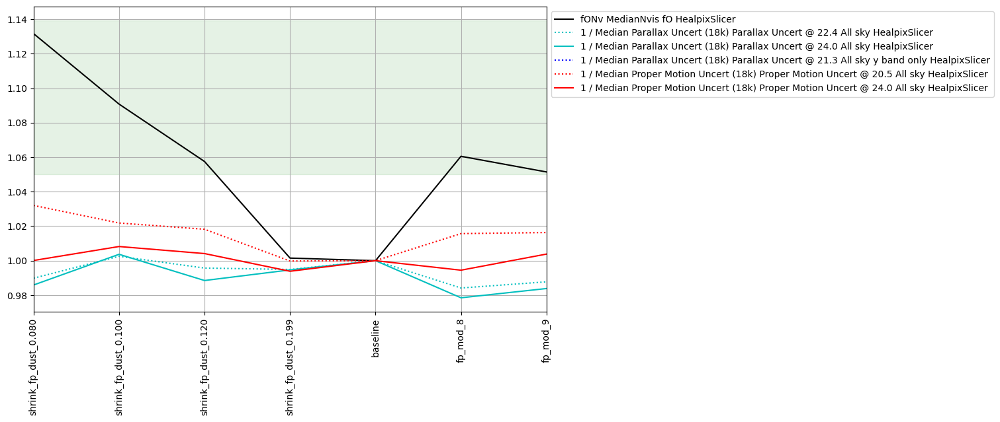

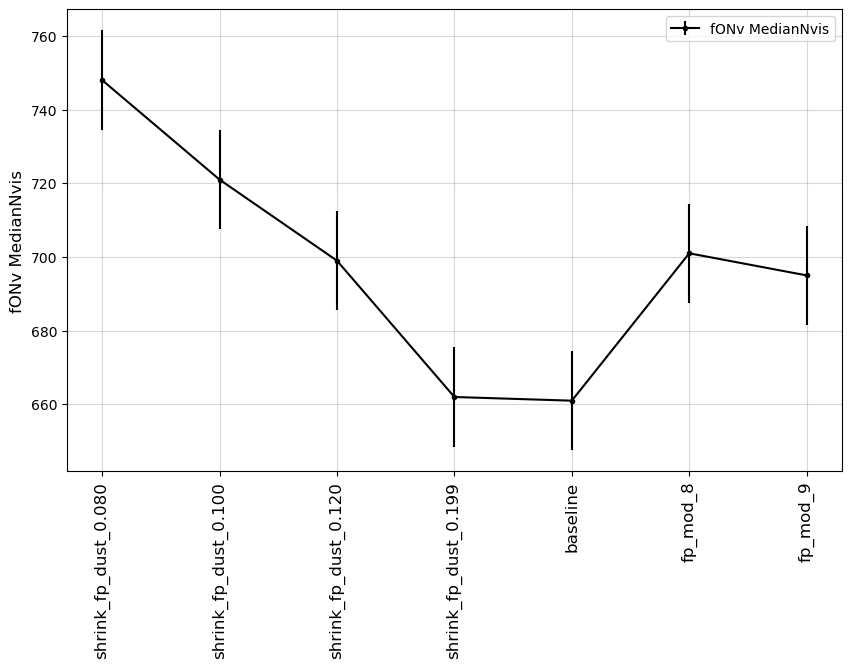

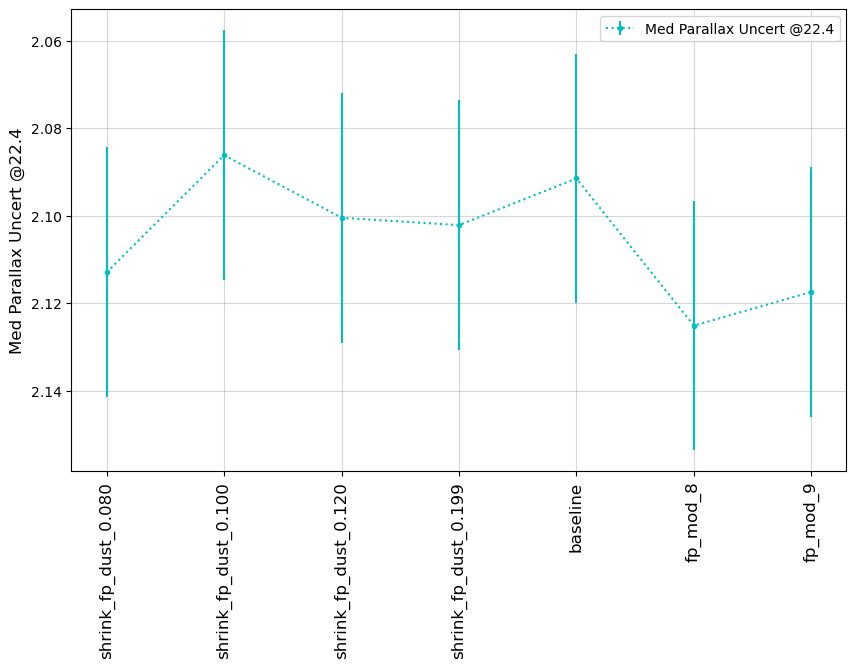

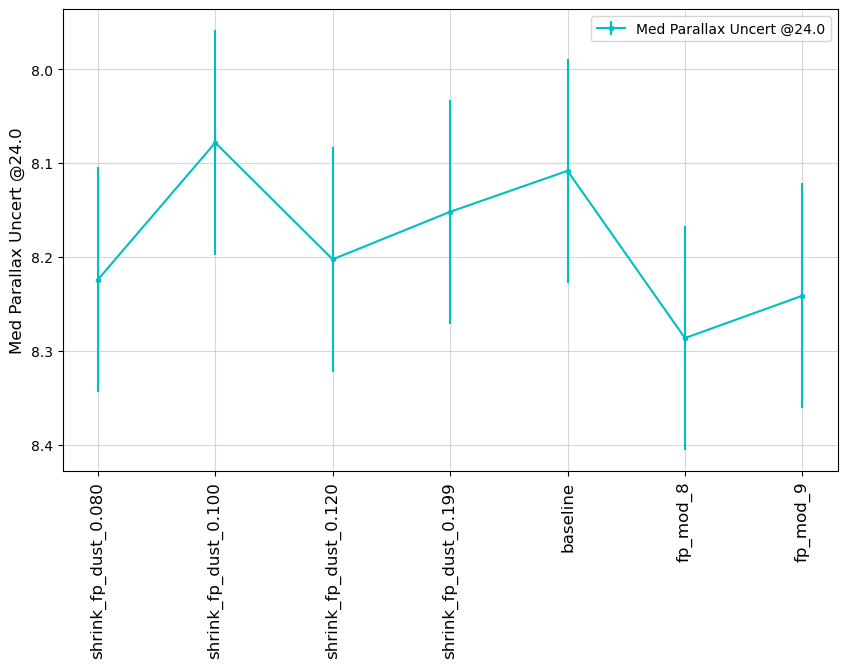

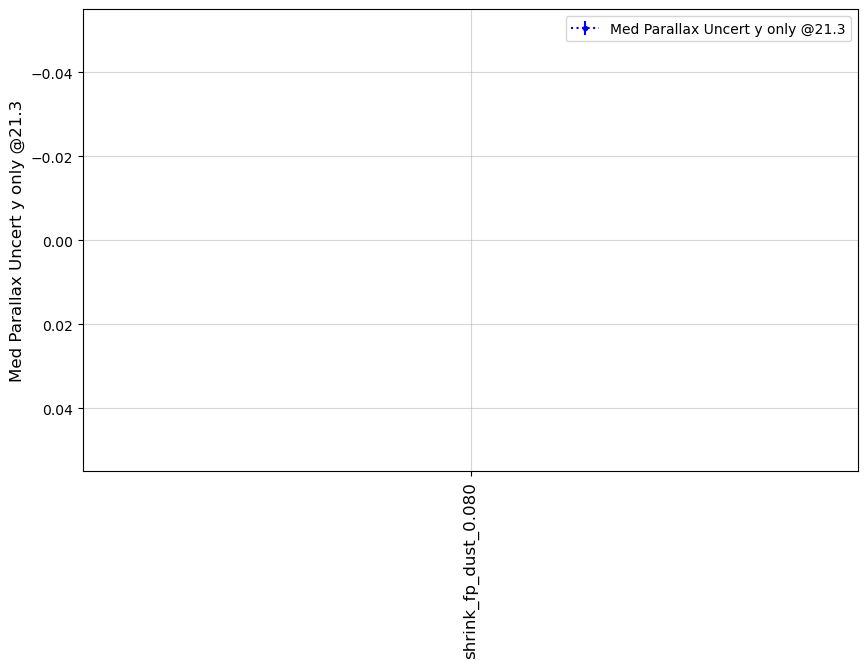

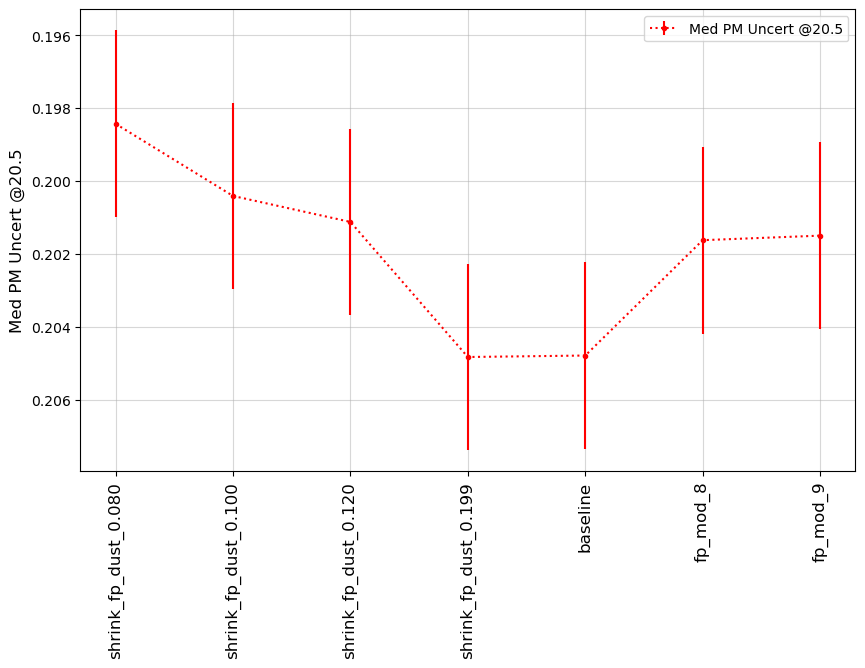

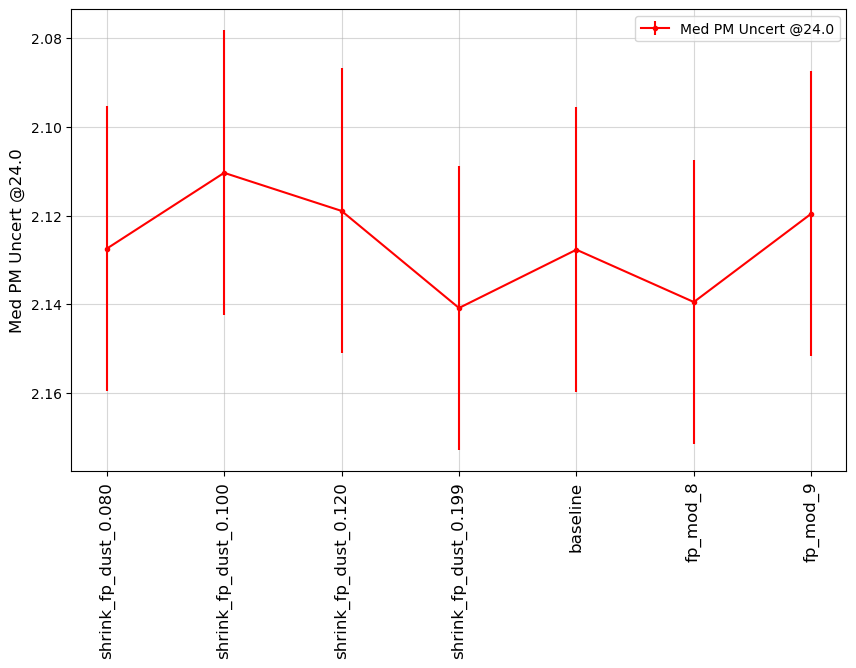

In [67]:
msub = metrics.loc['SRD']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub,)

### DESC WFD
<a id="DESC WFD"></a>
Metrics related to DESC WFD goals. These include both static science and transient science.

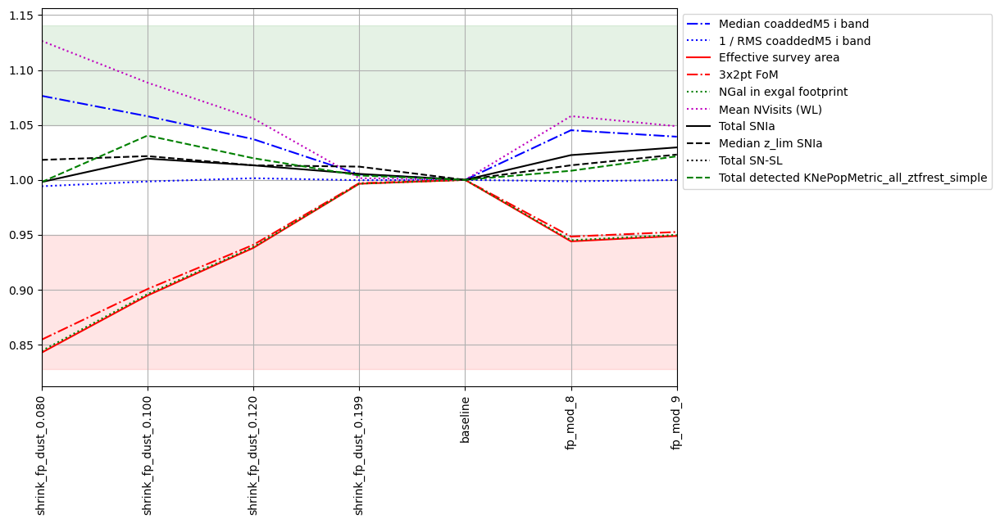

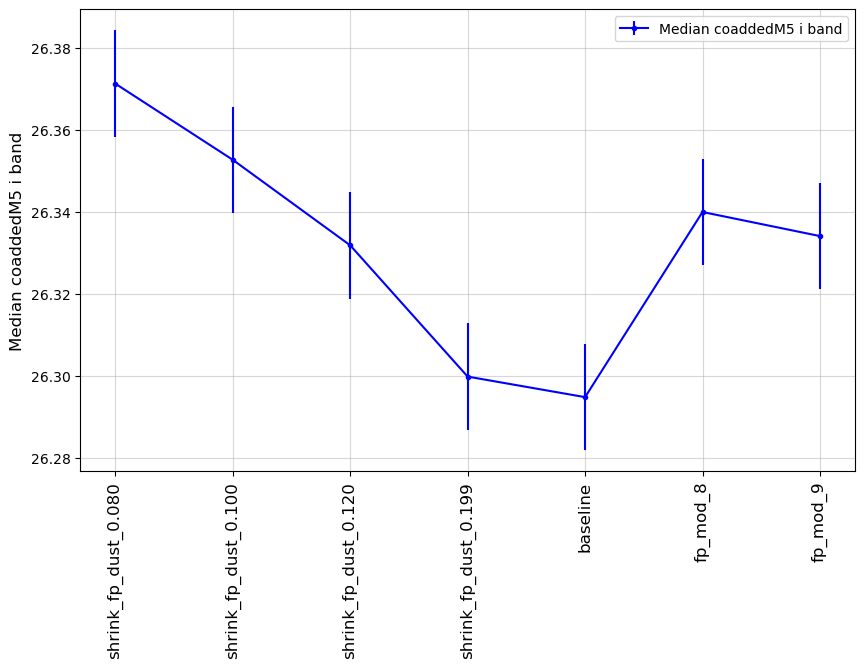

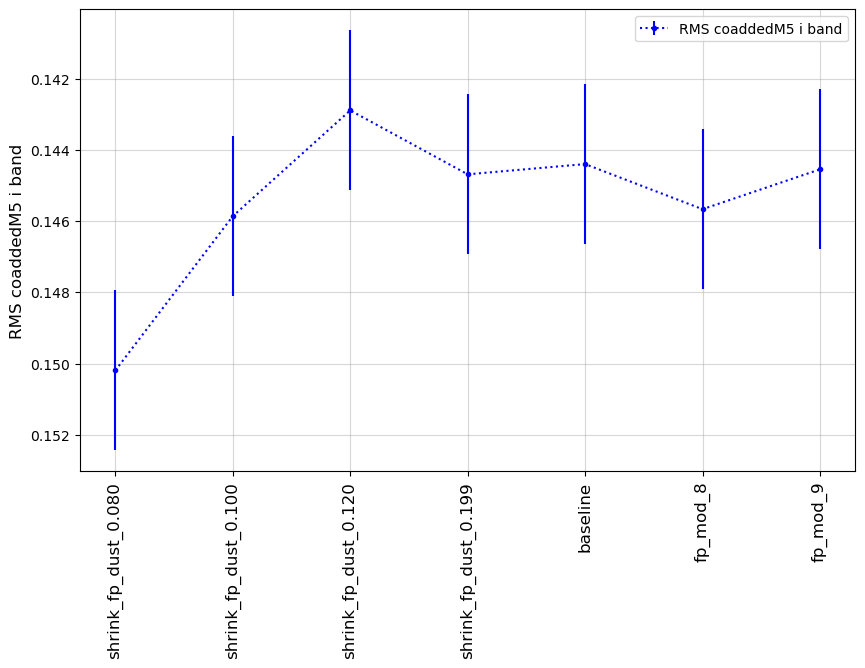

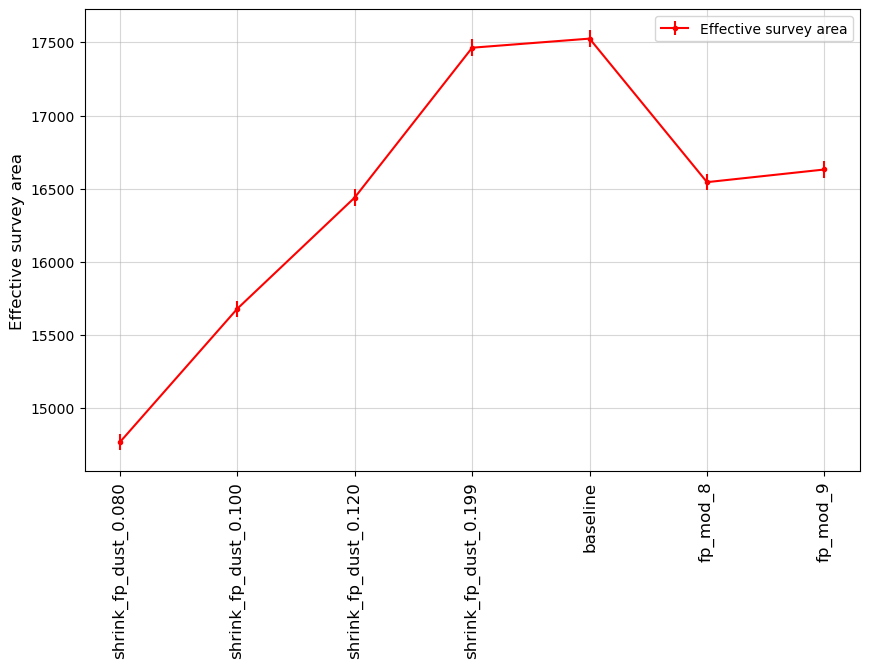

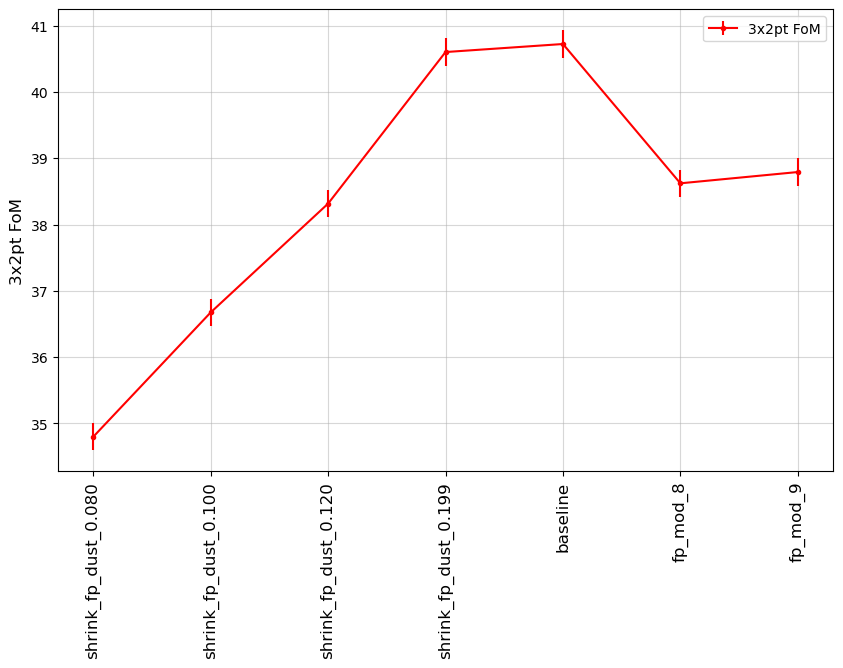

...

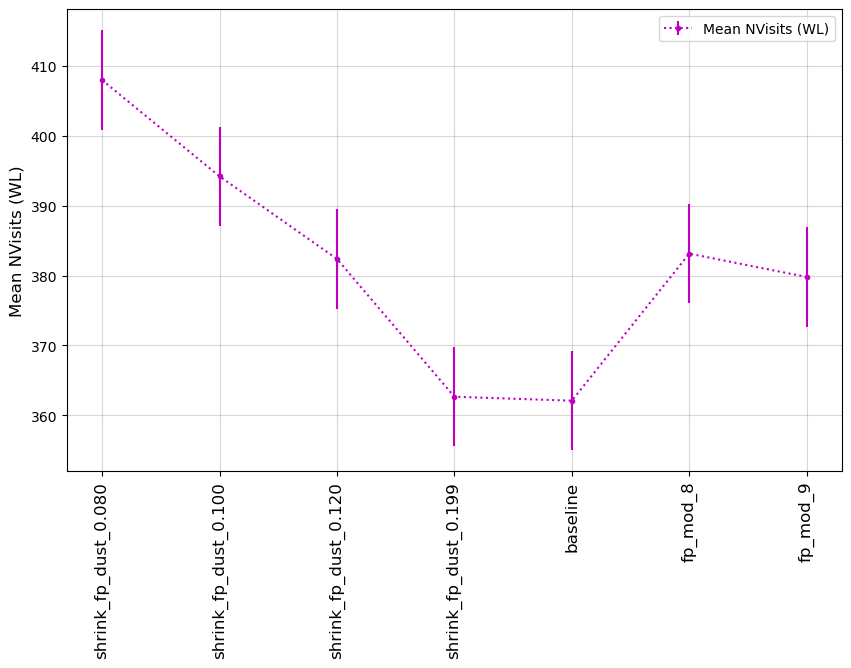

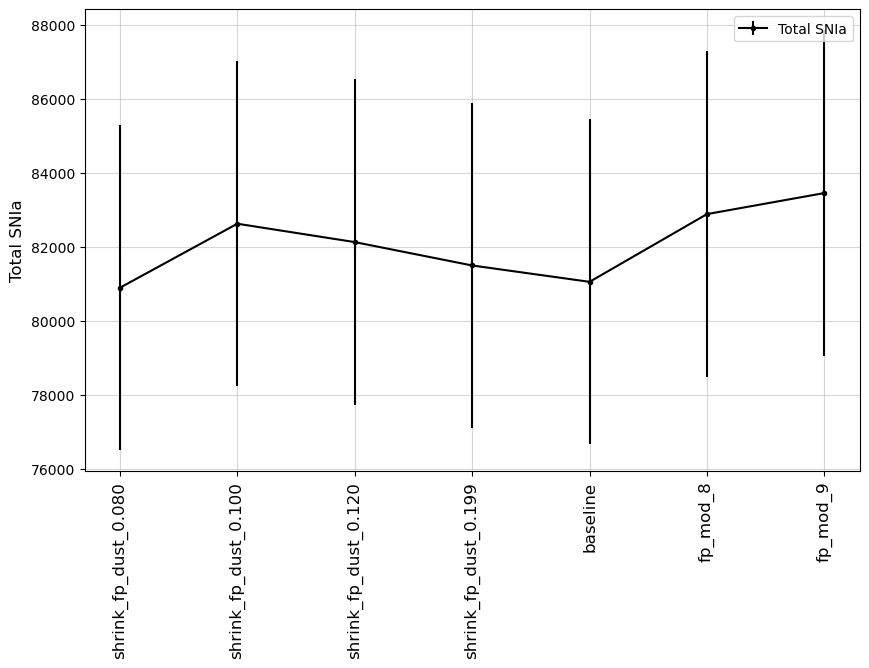

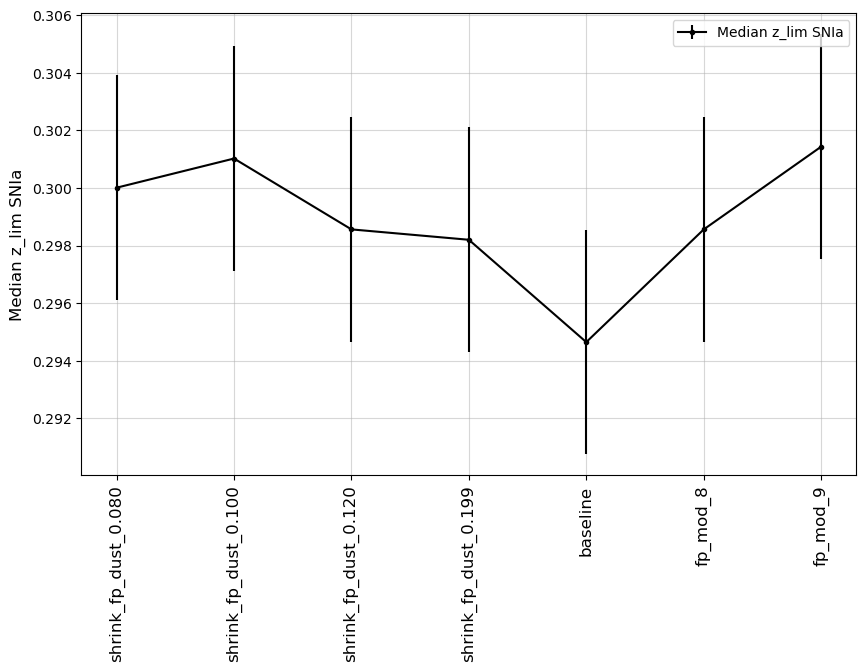

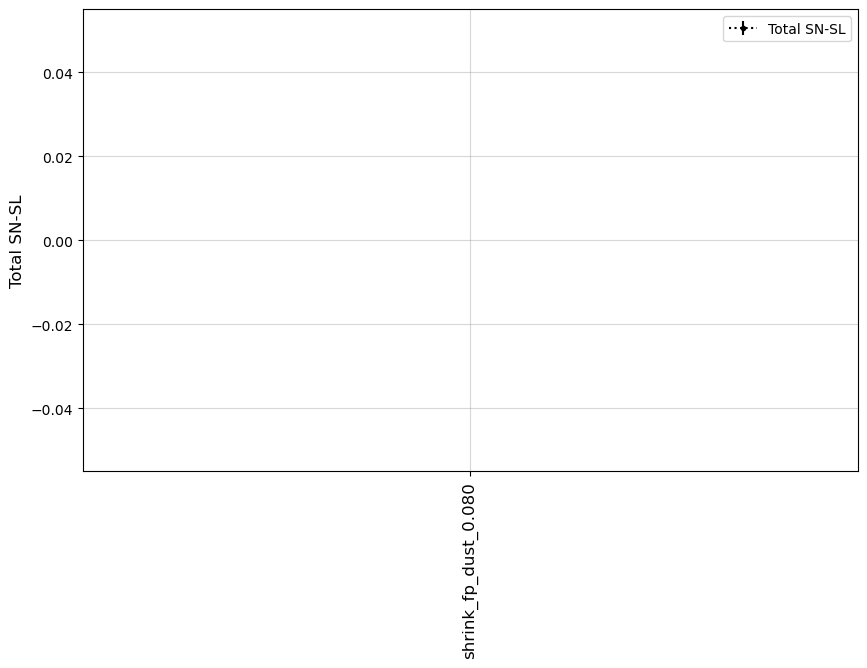

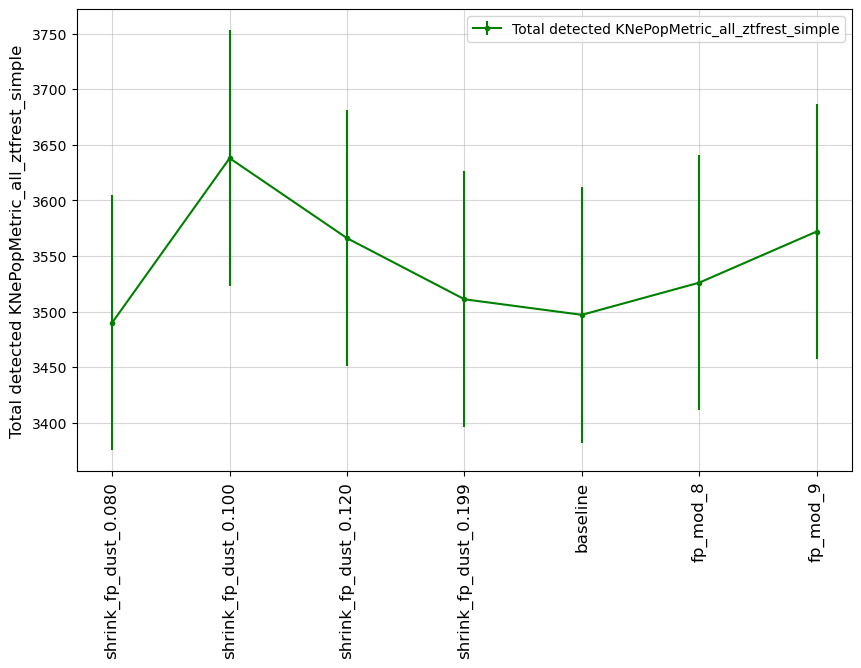

In [68]:
msub = metrics.loc['DESC WFD']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub)

In [70]:
summaries

metric,10th%ile CoaddM5 HealpixSlicer,10th%ile CoaddM5 g HealpixSlicer,10th%ile CoaddM5 i HealpixSlicer,10th%ile CoaddM5 r HealpixSlicer,10th%ile CoaddM5 u HealpixSlicer,10th%ile CoaddM5 y HealpixSlicer,10th%ile CoaddM5 z HealpixSlicer,10th%ile Count observationStartMJD HealpixSlicer,10th%ile Count observationStartMJD g HealpixSlicer,10th%ile Count observationStartMJD i HealpixSlicer,...,top18k Count observationStartMJD z HealpixSlicer,top18k N ToO g and scheduler_note like ToO% HealpixSlicer,top18k N ToO i and scheduler_note like ToO% HealpixSlicer,top18k N ToO r and scheduler_note like ToO% HealpixSlicer,top18k N ToO u and scheduler_note like ToO% HealpixSlicer,top18k N ToO y and scheduler_note like ToO% HealpixSlicer,top18k N ToO z and scheduler_note like ToO% HealpixSlicer,top18k Year1.0Count night < 365.25 HealpixSlicer,top18k Year2.5Count night > 913.125000 and night < 1278.375000 HealpixSlicer,top18k Year3.5Count night > 1278.375000 and night < 1643.625000 HealpixSlicer
run,,,,,,,,,,,,,,,,,,,,,
baseline_v2.0_10yrs,26.552398,26.195829,25.340360,25.927351,25.093302,23.700955,24.578618,231.0,42.0,54.0,...,150.0,NaN,NaN,NaN,NaN,NaN,NaN,67.0,30.0,29.0
baseline_v2.1_10yrs,26.503344,26.133542,25.314089,25.895823,25.100219,23.711028,24.539900,230.0,43.0,53.0,...,149.0,NaN,NaN,NaN,NaN,NaN,NaN,67.0,30.0,29.0
baseline_v2.2_10yrs,26.528637,26.131082,25.376580,25.950094,25.062897,23.782261,24.635641,231.0,42.0,54.0,...,150.0,NaN,NaN,NaN,NaN,NaN,NaN,67.0,32.0,30.0
baseline_v3.0_10yrs,26.401028,25.980170,25.256960,25.861146,24.954392,24.009574,24.490718,190.0,25.0,56.0,...,142.0,NaN,NaN,NaN,NaN,NaN,NaN,69.0,36.0,42.0
baseline_v3.2_10yrs,26.374343,25.923050,25.300074,25.841672,24.630521,24.001145,24.530703,185.0,23.0,55.0,...,150.0,NaN,NaN,NaN,NaN,NaN,NaN,72.0,38.0,31.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
weather_cloudso35v5.3.0_10yrs,26.510928,26.145000,25.348338,25.916219,24.895576,23.756657,24.641876,163.0,32.0,42.0,...,126.0,1.0,1.0,1.0,1.0,1.0,1.0,51.0,24.0,49.0
weather_cloudso36v5.3.0_10yrs,26.517015,26.156472,25.324692,25.917564,24.918002,23.740908,24.629334,166.0,33.0,43.0,...,125.0,1.0,1.0,1.0,1.0,1.0,1.0,51.0,24.0,42.0
weather_cloudso4v5.3.0_10yrs,26.510263,26.152718,25.312904,25.917933,24.883975,23.700386,24.600953,159.0,31.0,41.0,...,121.0,1.0,1.0,1.0,1.0,1.0,1.0,41.0,27.0,39.0


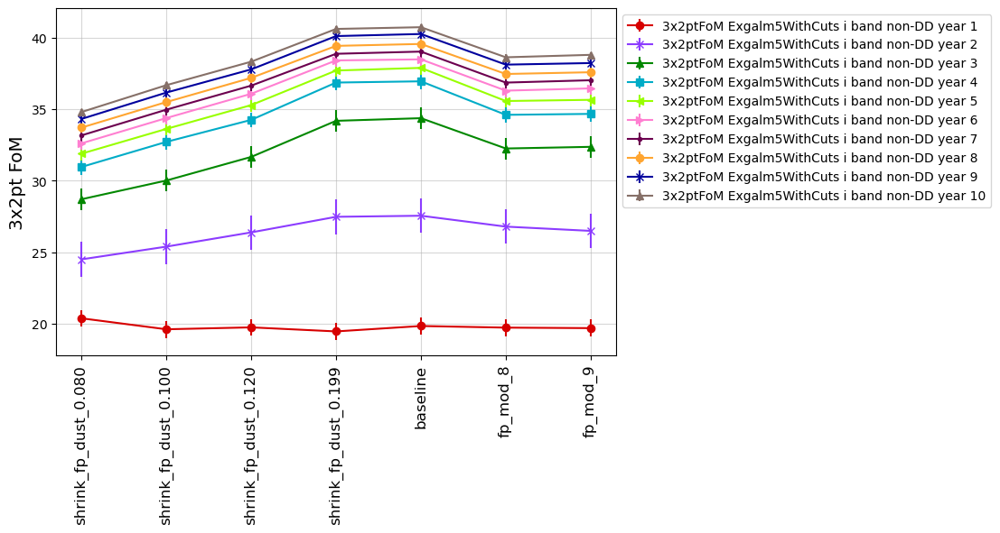

In [71]:
# Compare 3x2pt FOM metrics at individual years, between different simulations.
m1 = []
for yr in range(1, 11):
    m1 += [f'3x2ptFoM Exgalm5WithCuts i band non-DD year {yr} HealpixSlicer']

mset = maf.create_metric_subset('3x2pt', 
                                metrics=m1, 
                                short_name=[m.replace(' HealpixSlicer', '') for m in m1],
                               )
msub = mset.loc['3x2pt']

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 cmap=colorcet.glasbey_bw,
                                 metric_subset=msub,
                                 markers=['o', 'x', '^', 's', '<', '>', '.', ],
                                 sep_plots=False)                                 
ax.set_ylabel("3x2pt FoM", fontsize='x-large')
fig.set_figwidth(8)
fig.set_figheight(5)

### Transient and Variable Stars
<a id="TVS"></a>
Metrics related to Transient and Variable Stars collaboration goals. 

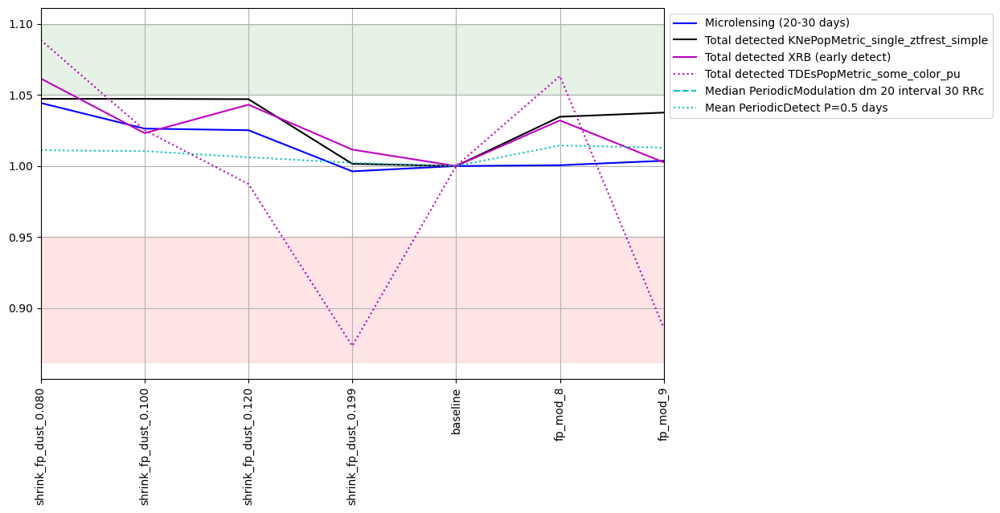

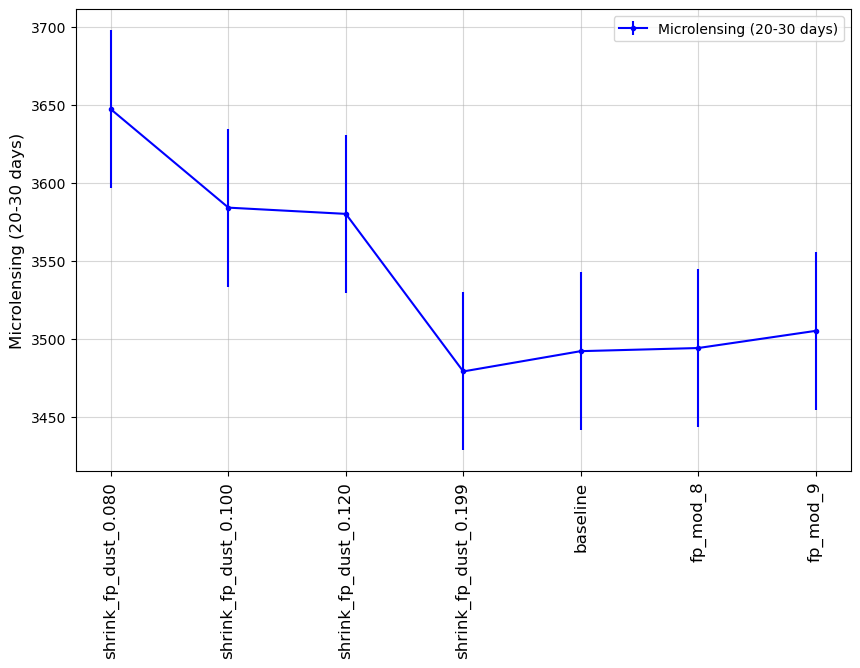

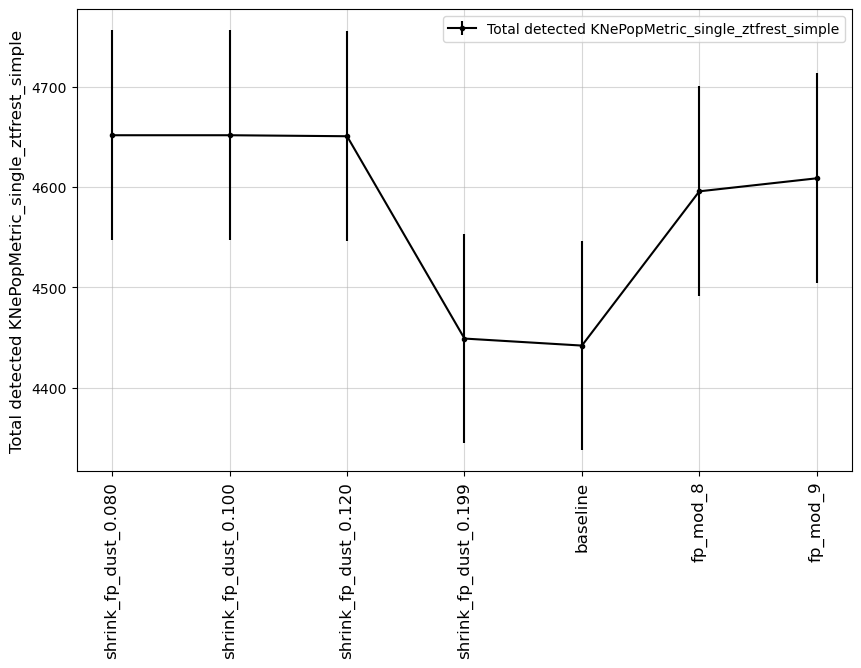

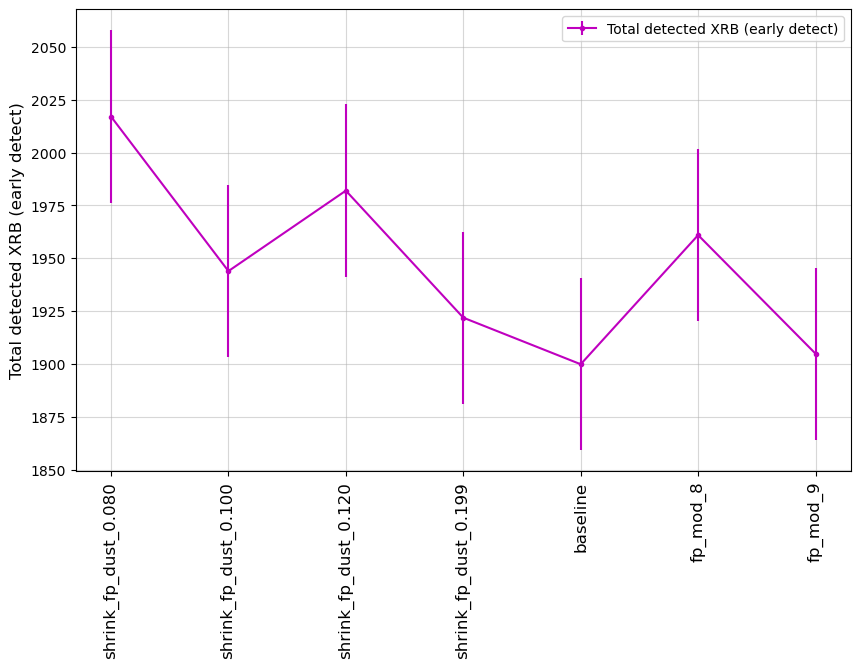

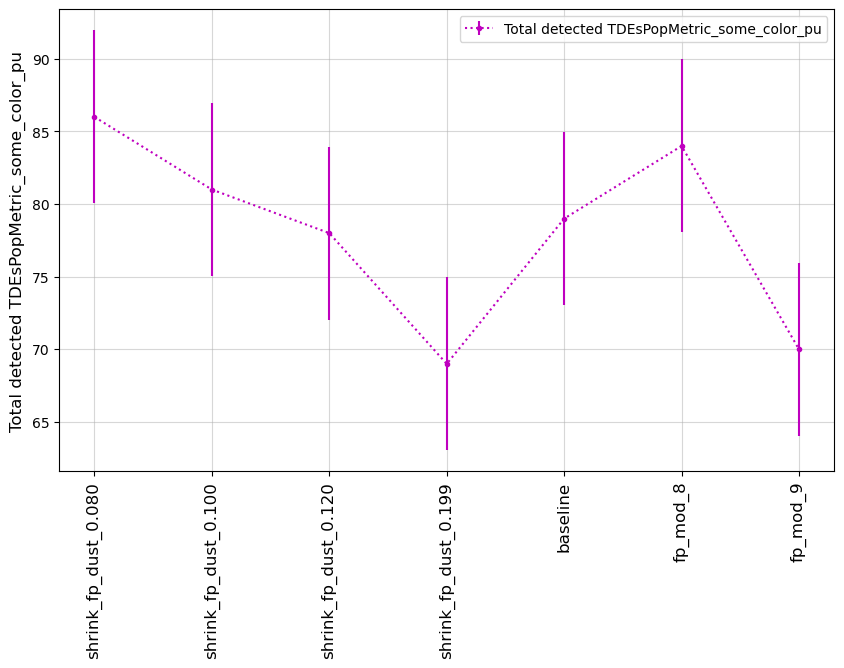

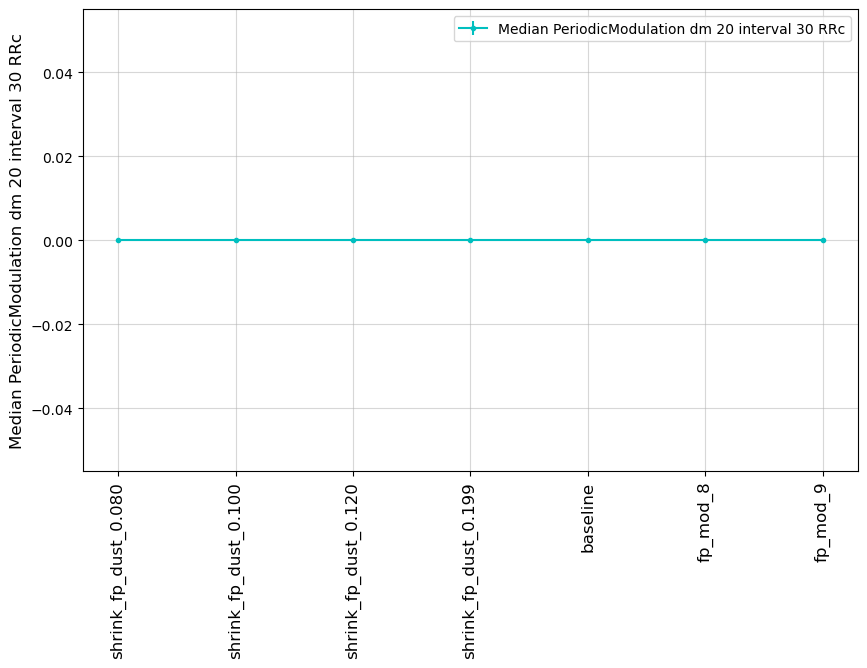

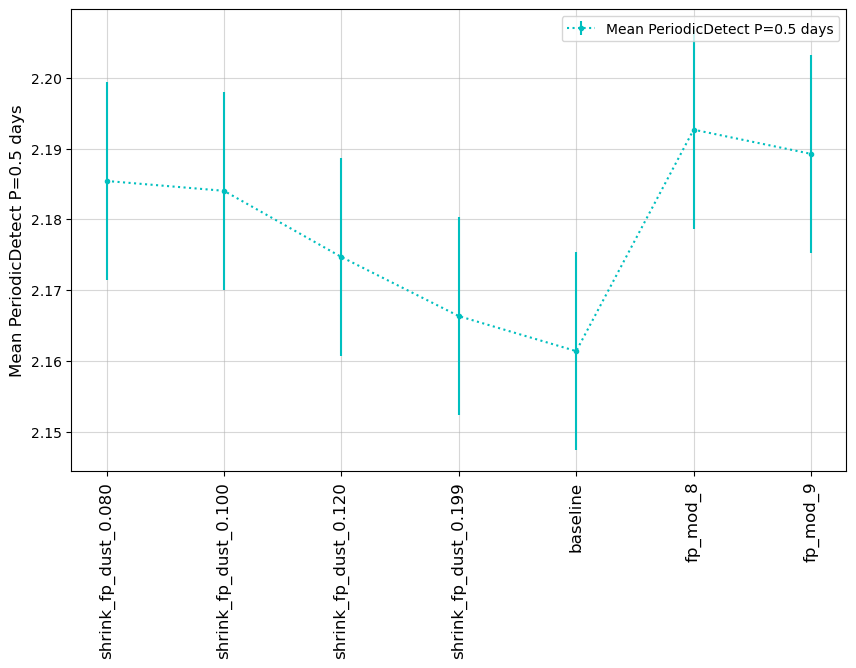

In [72]:
msub = metrics.loc['TVS short']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub)

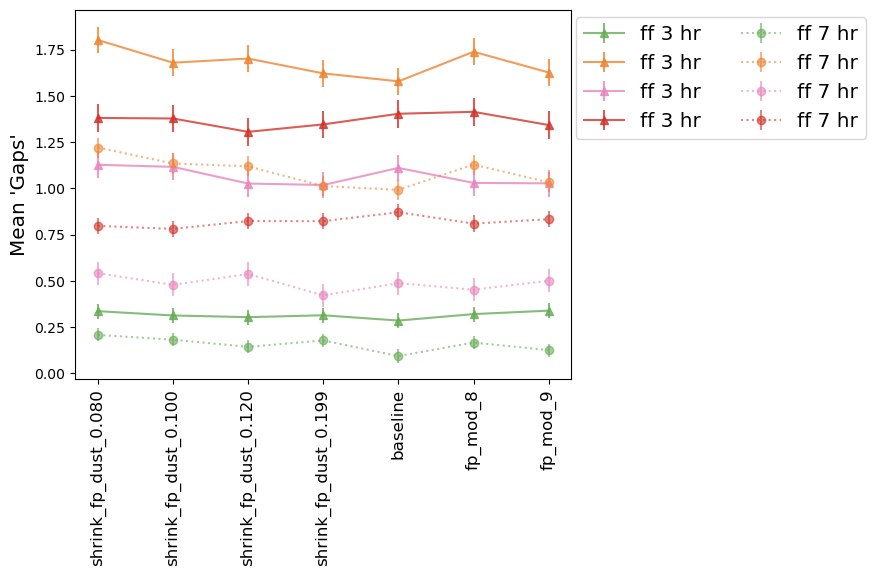

In [73]:
# Time Gaps metric 

fig, ax = plt.subplots()
mset = metrics.loc['TVS Gaps'][0:8]

run_names = [rdict[r] for r in runs]


markers = ['o', 's', '*', '<', '^', 'v', '*', '>', '.', 'X']
j = 0
for i, mm in mset.iterrows():
    m = mm['metric']
    ff = mm['short_name'].split('in ')[-1].split(' at')[0]
    #marker= markers[j]
    marker = 'o'
    if '3' in m:
        marker = '^'
        linestyle='-'
        alpha=0.8
        label=f"ff 3 hr"
    if '7' in m:
        marker = 'o'
        linestyle=':'
        alpha=0.6
        label =f"ff 7 hr"
    j += 1
    ax.errorbar(run_names, summaries.loc[runs, m], yerr=dev[m], 
                color=filter_rgb_map[ff], alpha=alpha, marker=marker, linestyle=linestyle, label=label)
plt.legend(loc=(1.01, 0.65), fontsize='x-large', ncols=2)
ax.set_ylabel("Mean 'Gaps'", fontsize='x-large')
ax.tick_params(axis='x', labelrotation = 90, labelsize='large')
fig.savefig(os.path.join(outdir, 'tgaps' + '.png'), format='png')

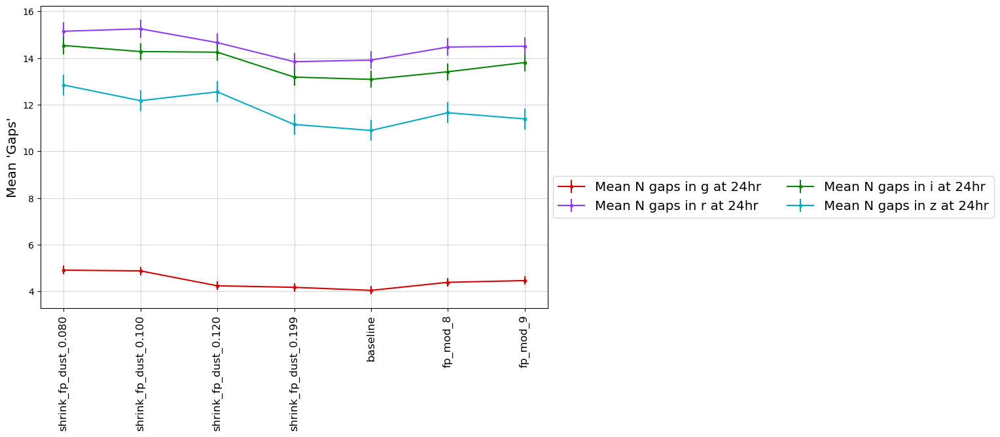

In [74]:
msub = metrics.loc['TVS Gaps'][8:12]

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 cmap=colorcet.glasbey_dark,
                                 metric_subset=msub, sep_plots=False)
plt.legend(loc=(1.01, 0.3), fontsize='x-large', ncols=2)
ax.set_ylabel("Mean 'Gaps'", fontsize='x-large')
ax.tick_params(axis='x', labelrotation = 90, labelsize='large')

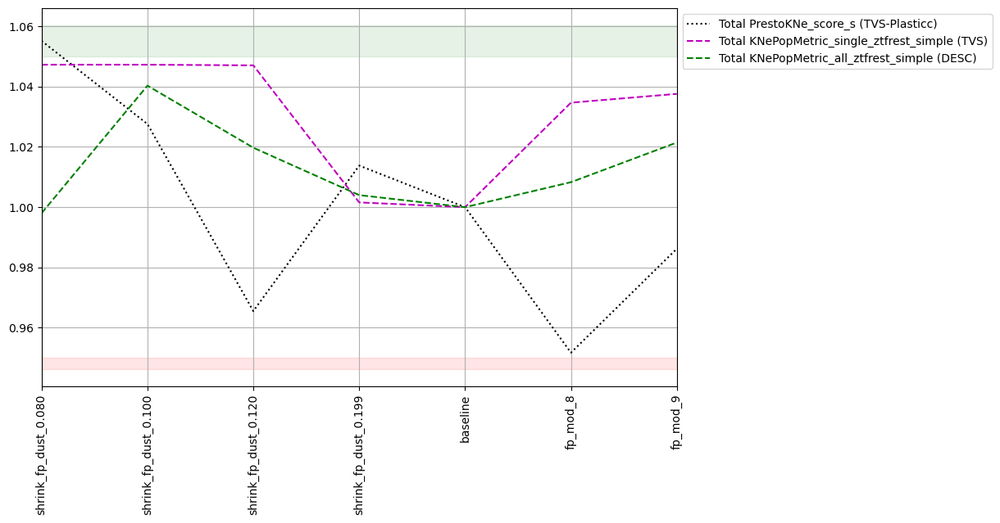

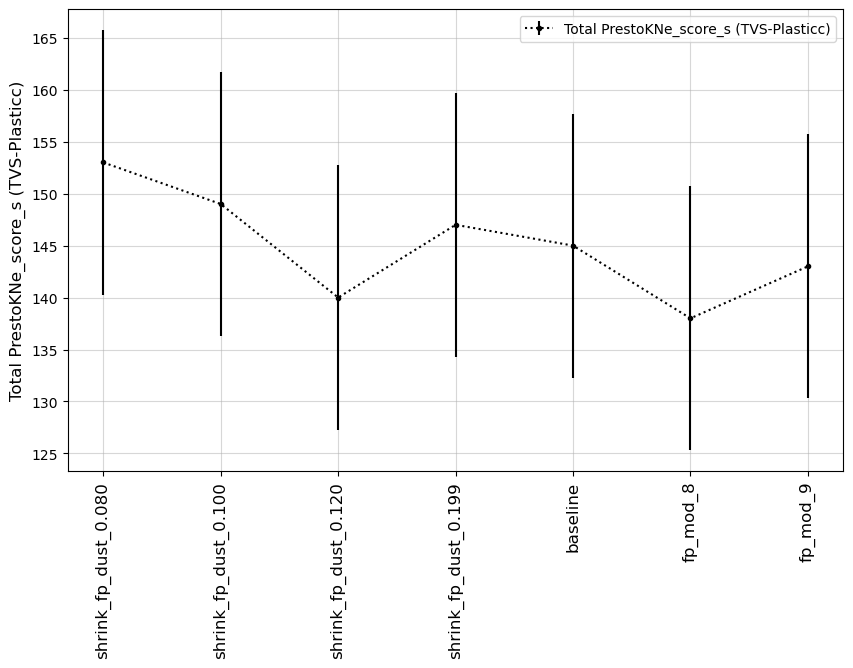

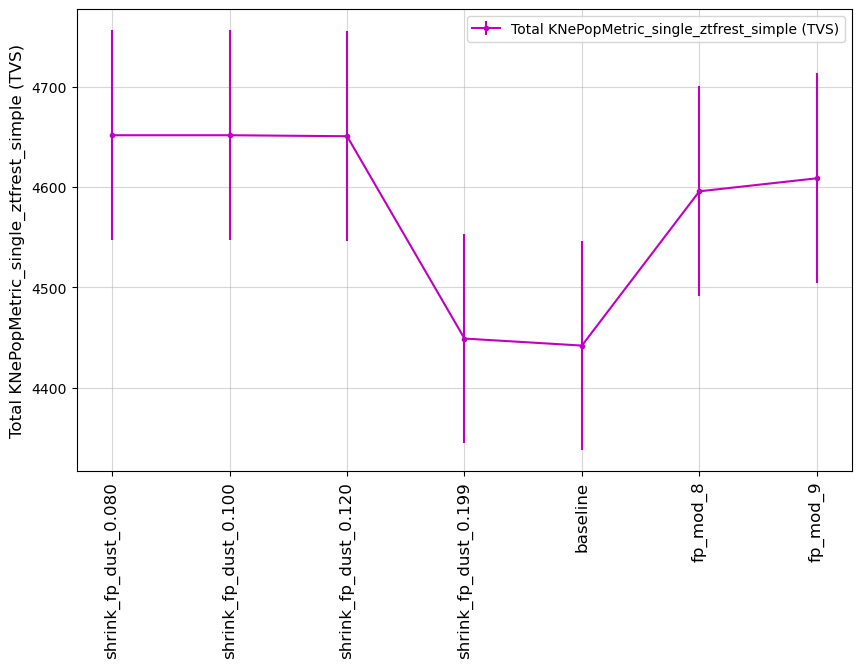

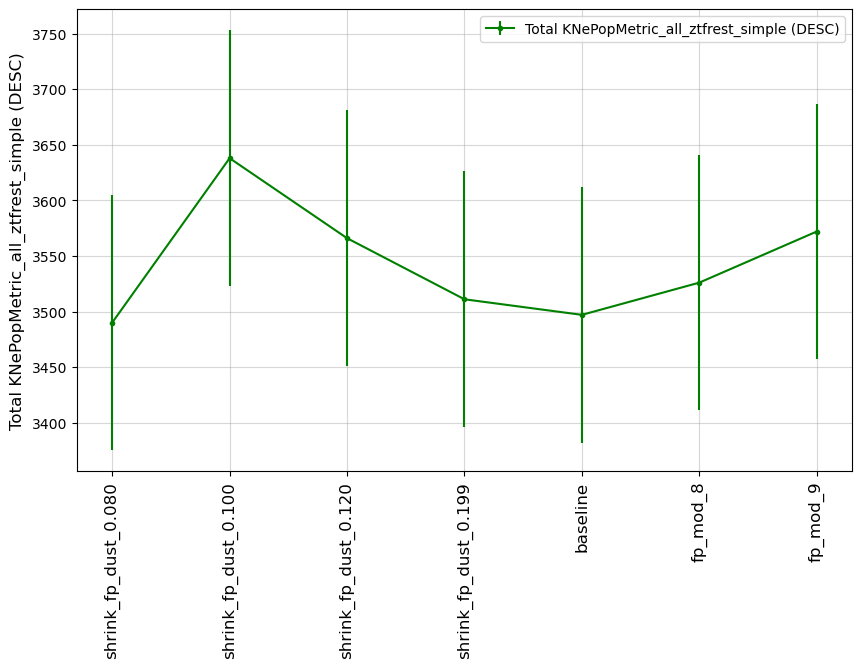

In [75]:
msub = metrics.loc['TVS KNe short']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline,
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub)

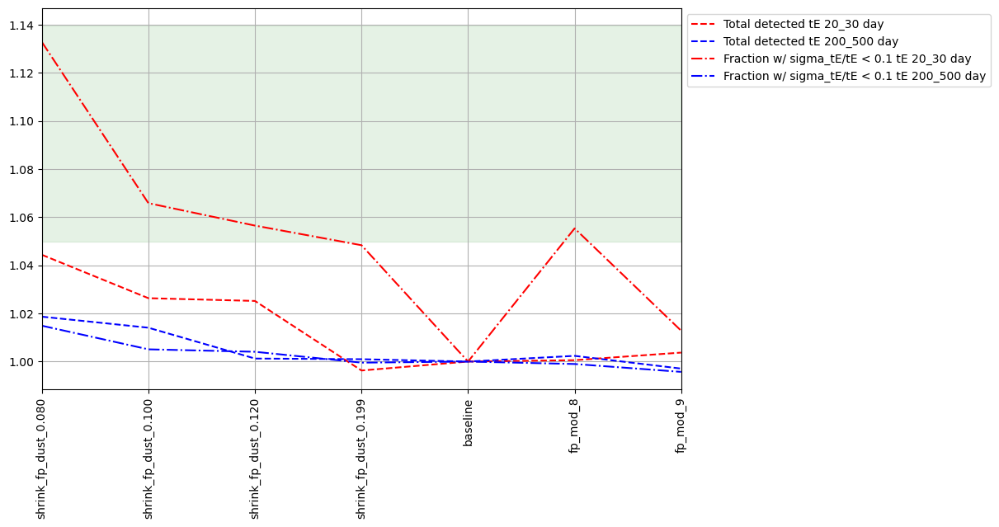

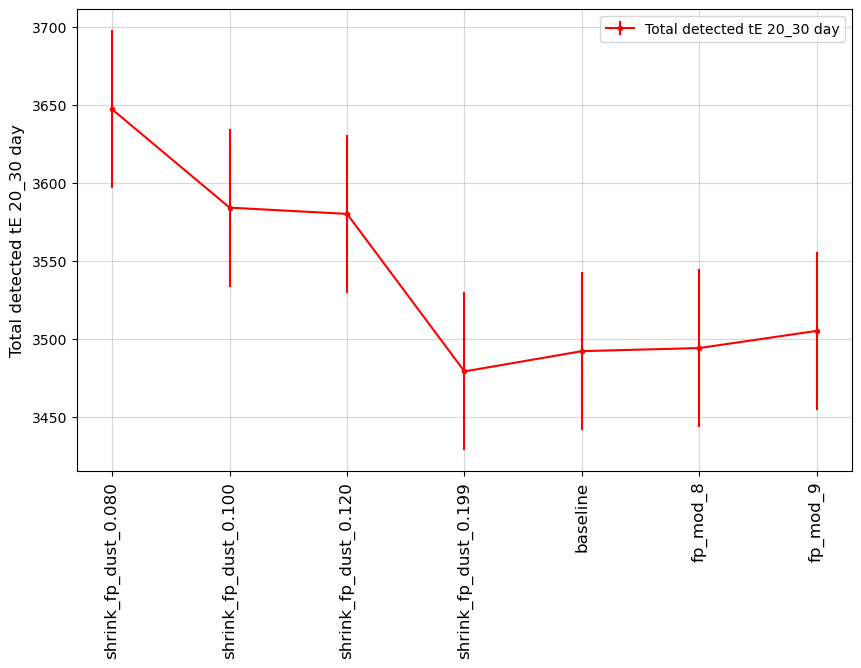

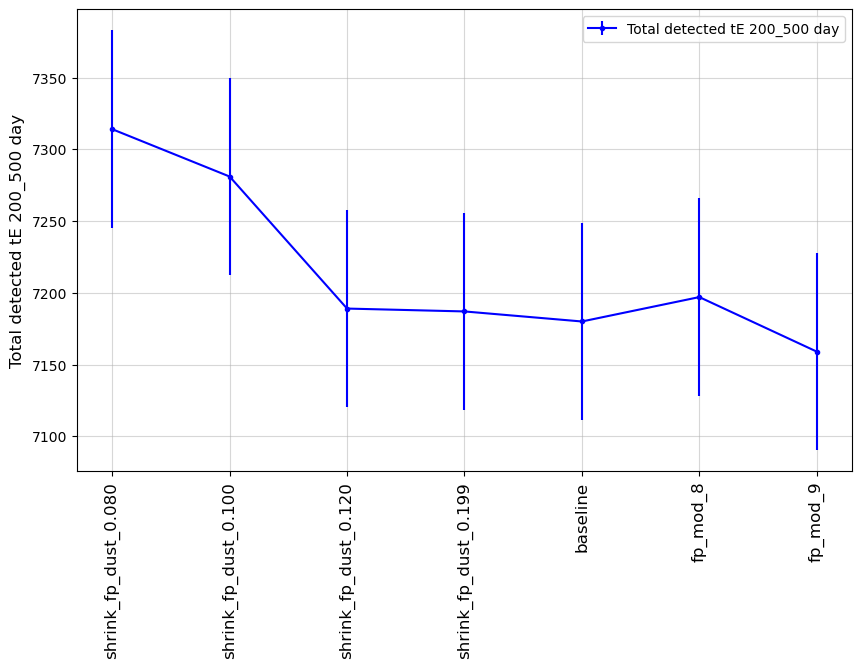

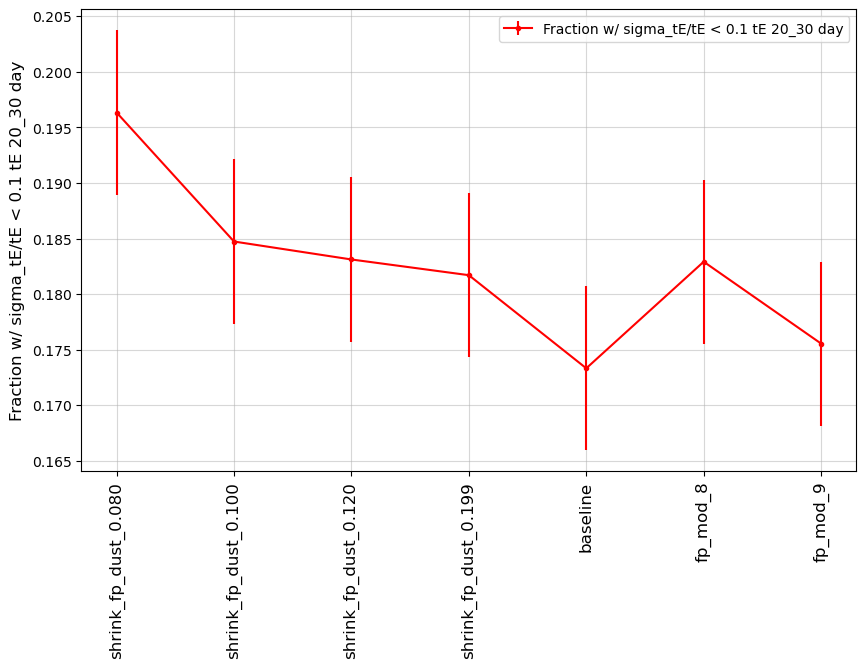

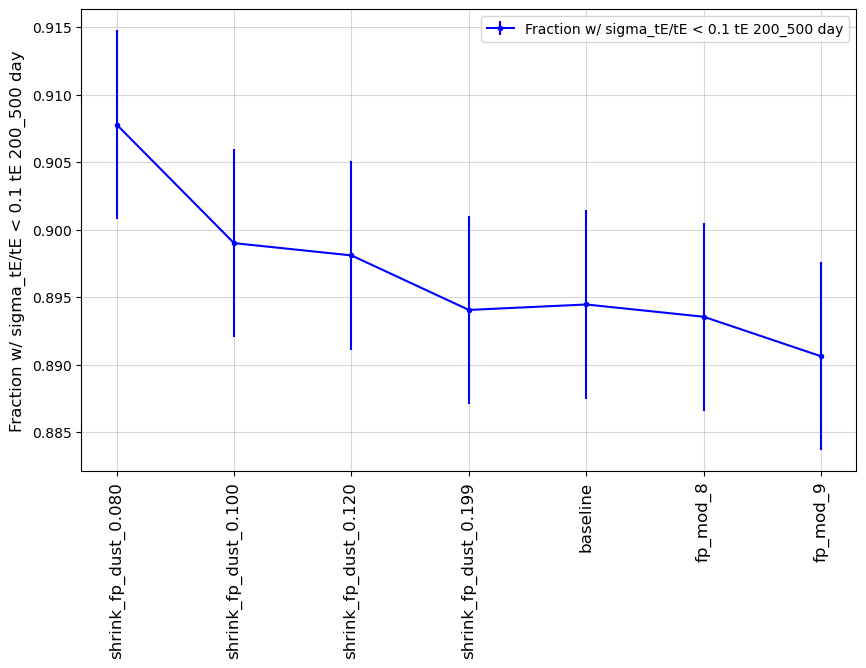

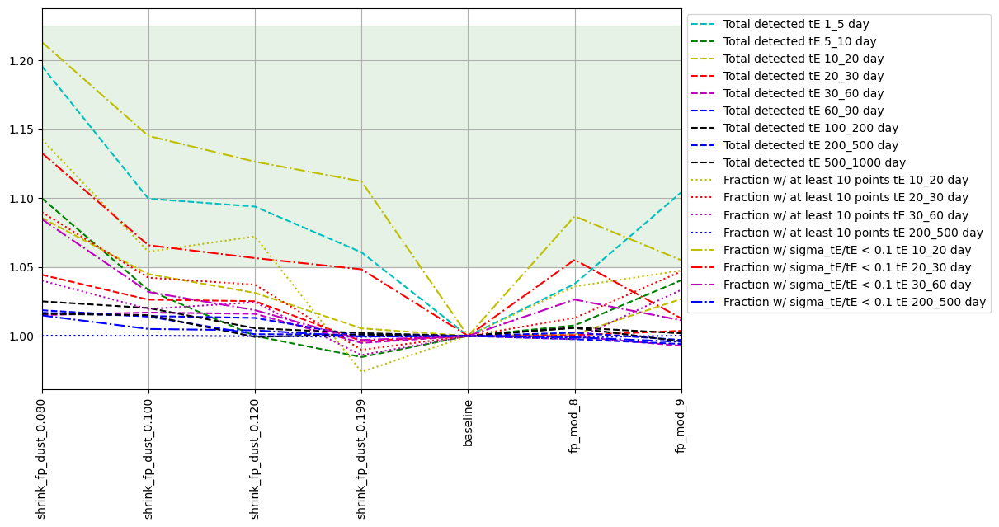

In [76]:
msub = metrics.loc['TVS microlensing short']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub, sep_plots=True)

msub = metrics.loc['TVS microlensing all']
fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

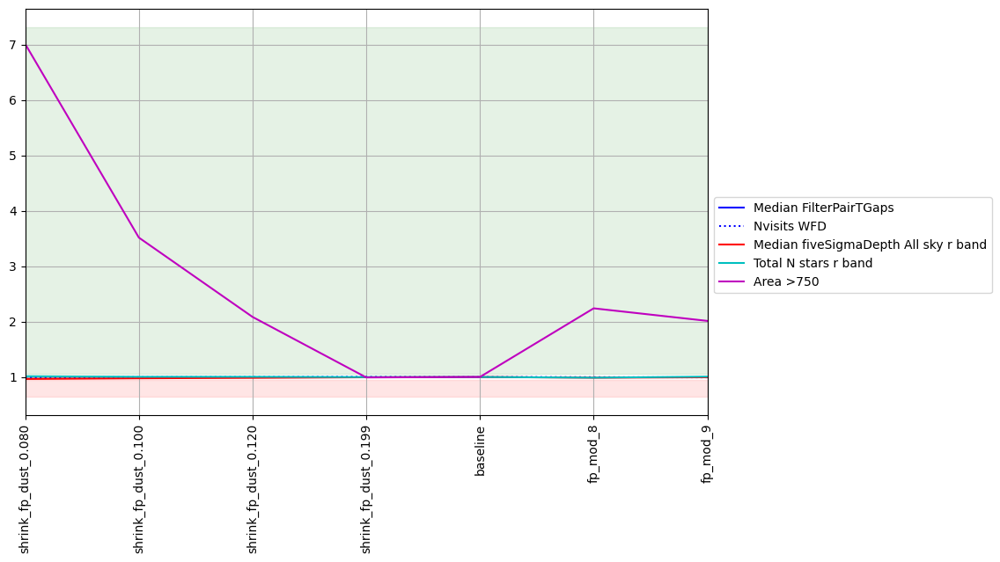

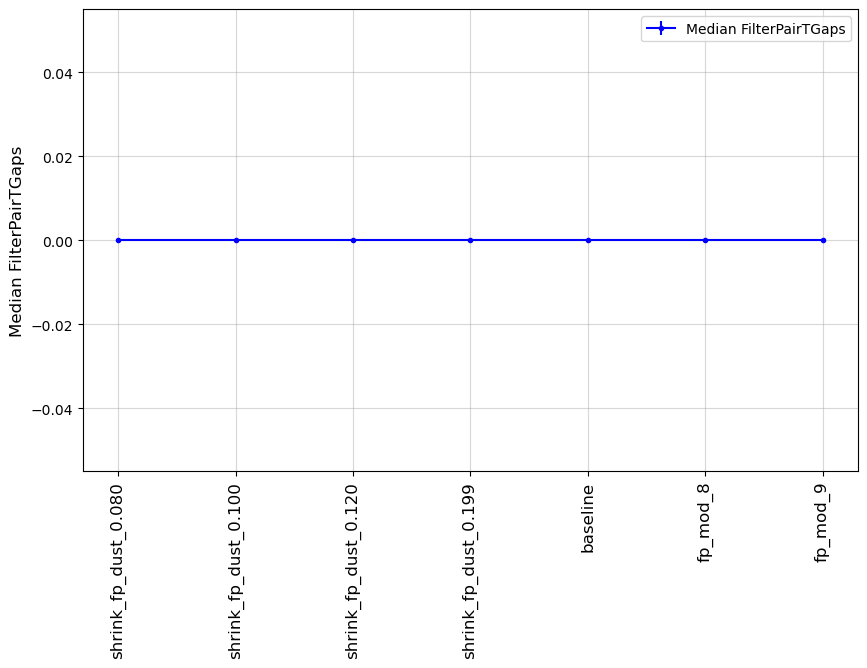

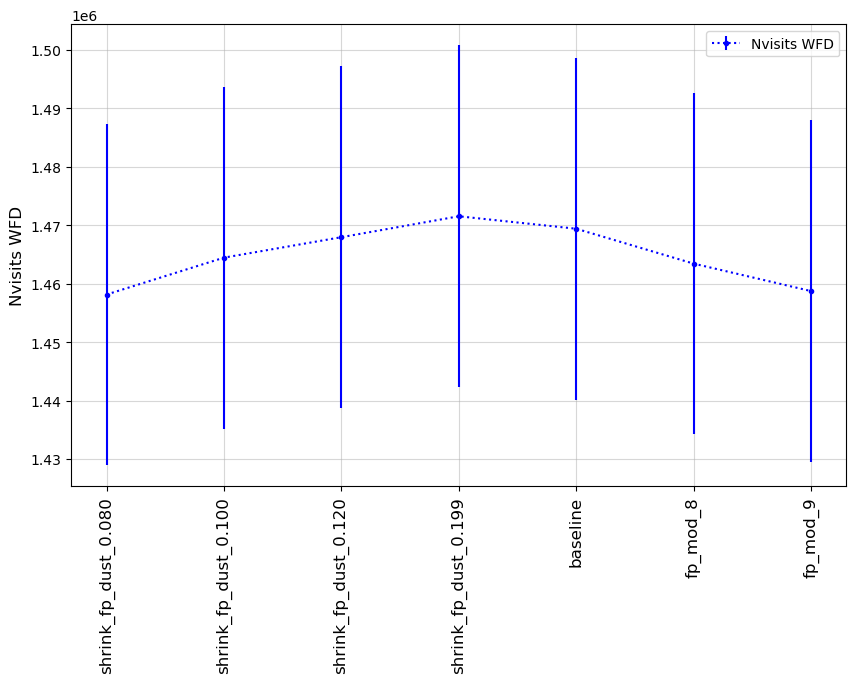

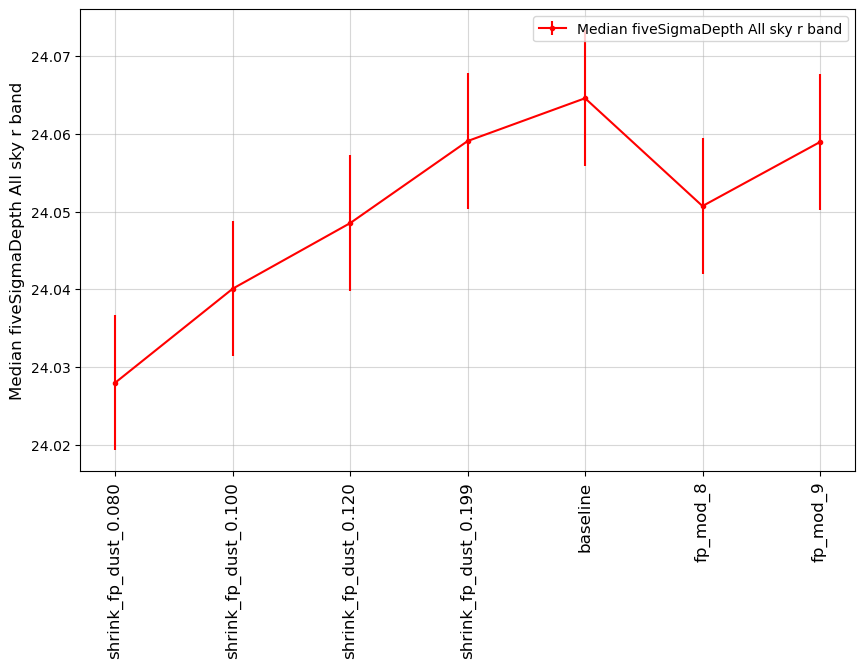

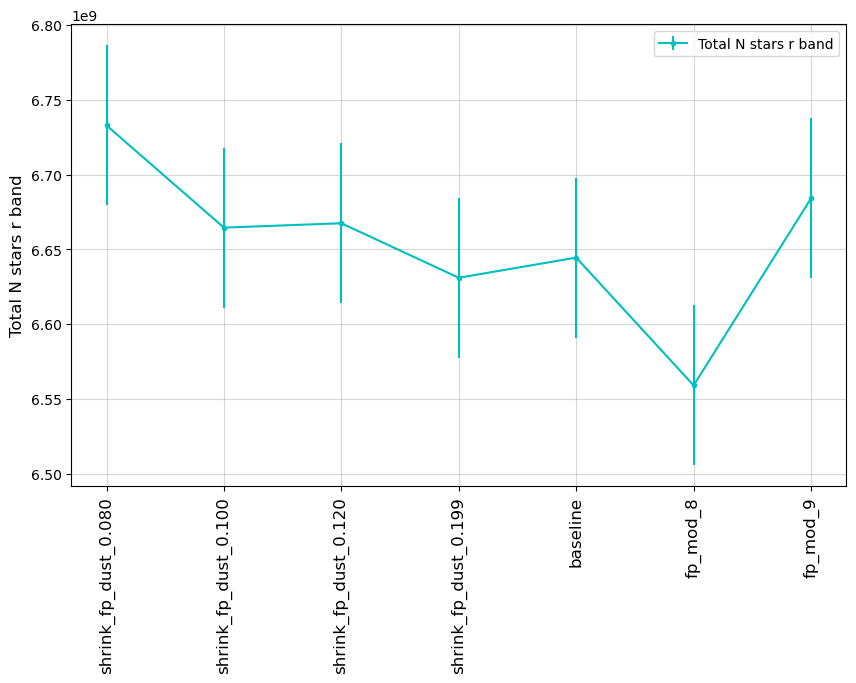

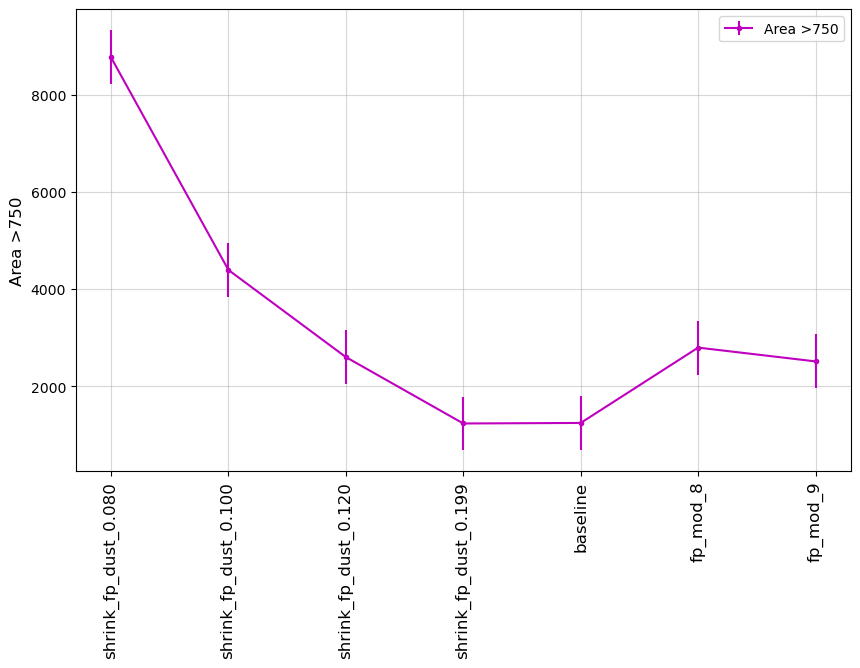

In [77]:
msub = metrics.loc['TVS anomalies']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')
ax.legend(loc=(1.01, 0.3))
              
fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub)

### Solar System Objects
<a id="SSO"></a>
Metrics related to Solar System Science Collaboration goals. 

In [78]:
class TTotalNumberSSO(maf.BaseMoMetric):
    """Calculate the total number of objects of a given population
    expected at a given H value or larger.

    Operations on differential completeness values
    (or equivalent; fractions of the population is ok if
    still a differential metric result, not cumulative).

    Parameters
    ----------
    h_mark : `float`, optional
        The H value at which to calculate the expected total number of objects.
    dndh_func : function, optional
        The dN/dH distribution used calculate the expected population size.

    Returns
    -------
    nObj : `float`
        The predicted number of objects in the population.
    """

    def __init__(self, h_mark=22, dndh_func=maf.neo_dndh_granvik, dndh_args=None, **kwargs):
        self.h_mark = h_mark
        self.dndh_func = dndh_func
        self.dndh_args = dndh_args
        metric_name = "Nobj <= %.1f" % (h_mark)
        super().__init__(metric_name=metric_name, **kwargs)

    def run(self, metric_vals, h_vals):
        totals = maf.sum_over_h(metric_vals, h_vals, self.dndh_func, **self.dndh_args)
        n_obj = np.interp(self.h_mark, h_vals, totals)
        return n_obj

In [79]:
# Plot completeness over time 
# mm = [c for c in summaries if 'Vatira' in c and 'CumulativeCompleteness' in c and 'DiscoveryTime' in c 
#            and 'quad' in c and ' detection loss' in c and "H <=20.0" in c and "SNR" not in c]
# times = [float(m.split("@ ")[1].split(" DiscoveryTime")[0]) for m in mm]
# times = np.array(times)
# mvals = np.array([summaries.loc[baseline, m] for m in mm])
# good = np.where(~np.isnan(mvals))

# plt.plot(times[good], mvals[good])

# mm = [c for c in summaries if 'Vatira' in c and 'CumulativeCompleteness' in c and 'DiscoveryTime' in c 
#            and '3 pairs in 15 nights' in c and ' detection loss' in c and "H <=20.0" in c and "SNR" not in c]
# times = [float(m.split("@ ")[1].split(" DiscoveryTime")[0]) for m in mm]
# times = np.array(times)
# mvals = np.array([summaries.loc[baseline, m] for m in mm])
# good = np.where(~np.isnan(mvals))

# plt.plot(times[good], mvals[good])

In [80]:
# # Calculate total #'s of objects 
# mm = [c for c in summaries if 'NEO' in c and 'DifferentialCompleteness' in c and 'DiscoveryNChances' in c 
#            and '3 pairs in 15 nights ' in c and ' detection loss' in c and 'SNR' not in c]
# hvals = [float(m.split("= ")[1].split(" DiscoveryNChances")[0]) for m in mm]
# hrange = np.sort(np.array(hvals))

# # NTr5 = 794 × 10^0.44(H−12)
# # NTNO = 71,400 × 10^0.63(H−9.1),
# # NNEA = 960 × 10^0.35(H−18)
# kwargs = 'no': 794, 'ho': 12, 'h_index': 0.44
# kwargs = 'no': 960, 'ho': 18, 'h_index': 0.35
# kwargs = 'no': 71400, 'ho': 9.1, 'h_index': 0.63
# total_num = TTotalNumberSSO(h_mark=26, dndh_func=maf.neo_dndh_granvik, dndh_args=kwargs)
# #total_num = TTotalNumberSSO(h_mark=22, dndh_func=maf.power_law_dndh, dndh_args=kwargs)
# for r in runs:
#     _ = plt.plot(hrange, summaries.loc[r, mm].values)
#     nobj = total_num.run(summaries.loc[r, mm].values, hrange) 
#     print(r, nobj)
# #50 percent H value
# #np.interp(0.5, 1-summaries.loc[r, mm].values, hrange)

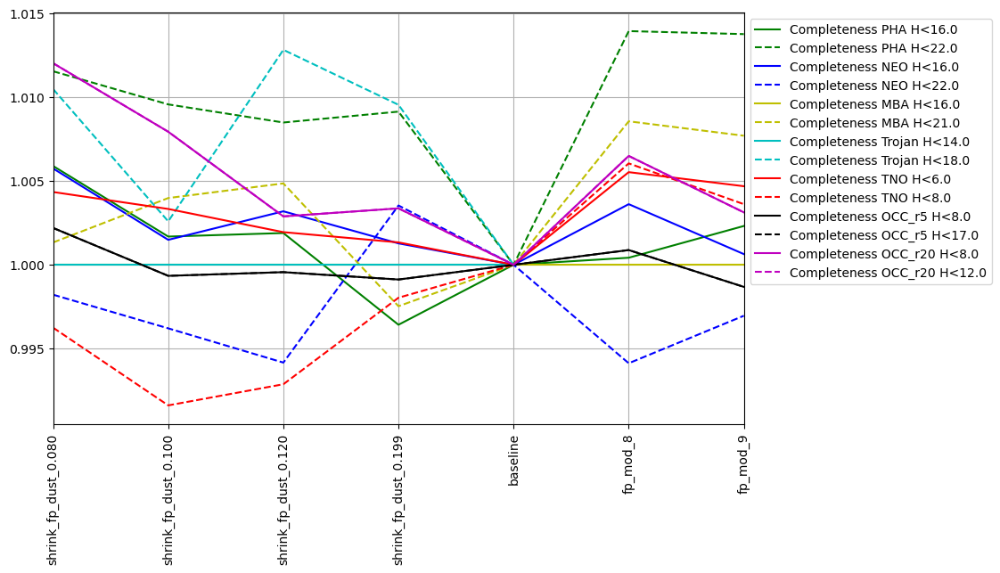

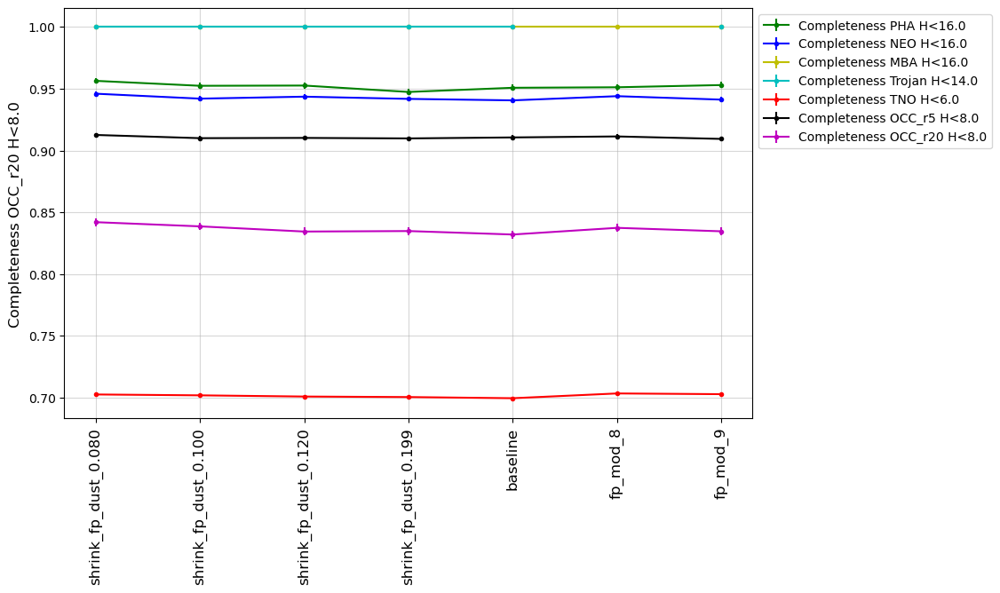

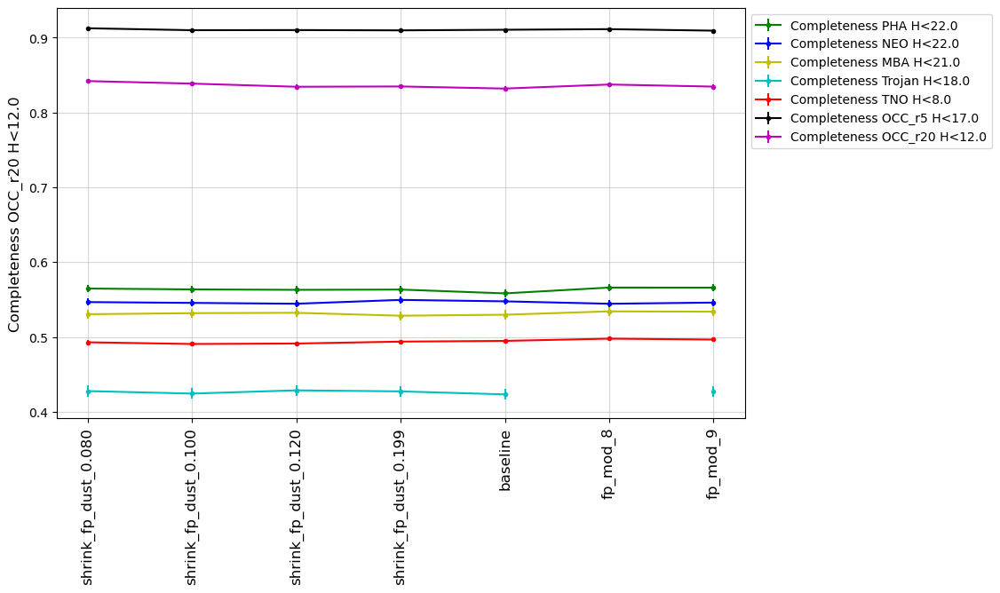

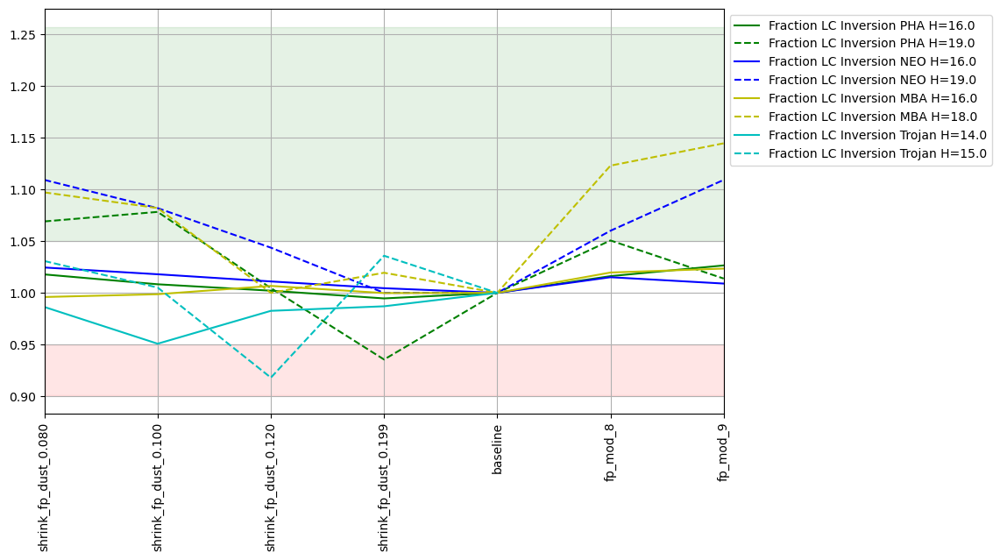

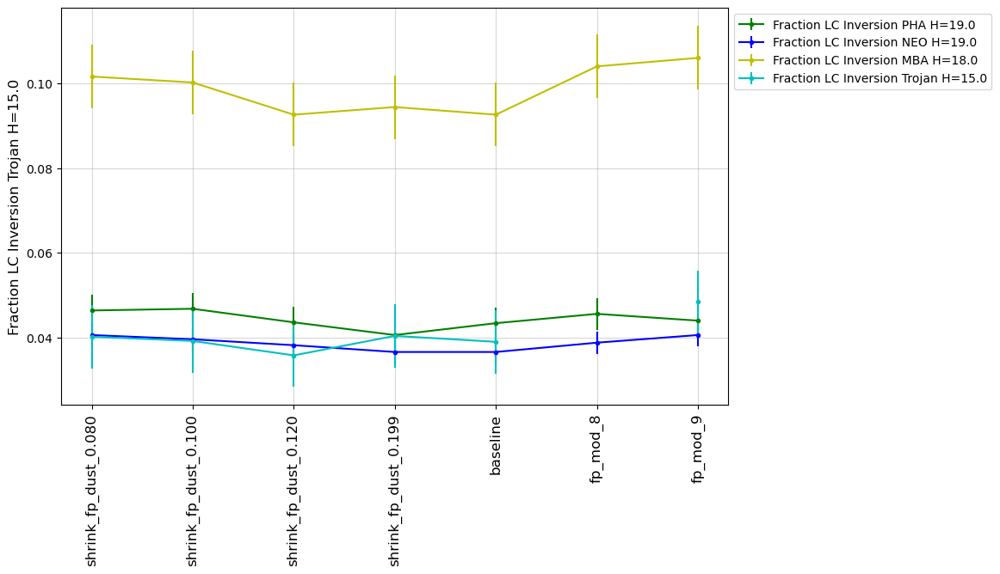

...

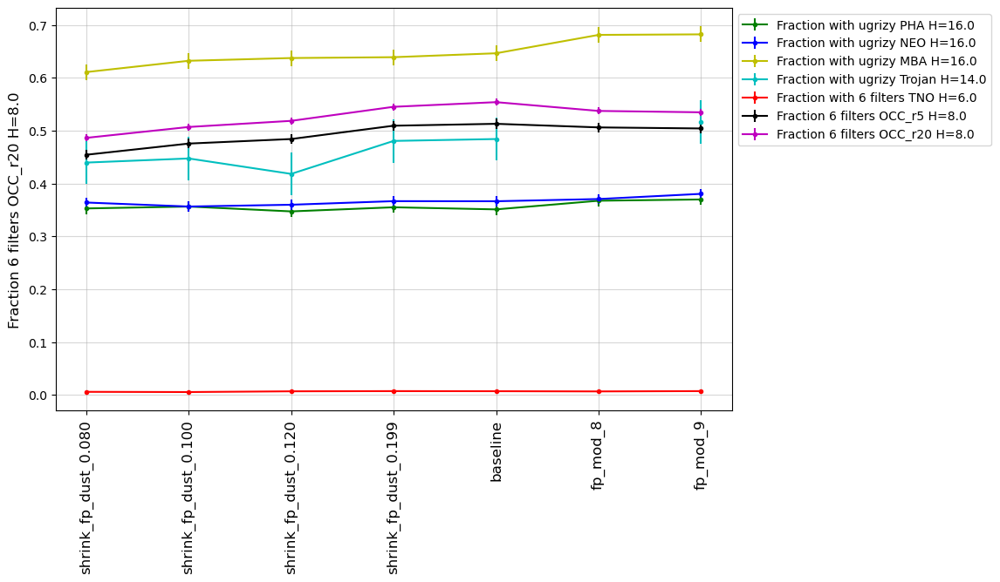

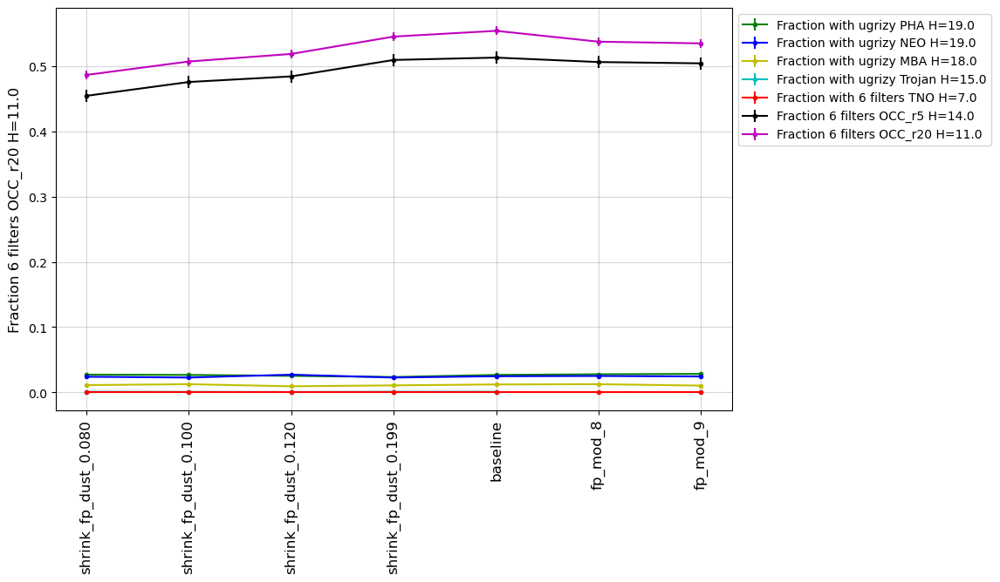

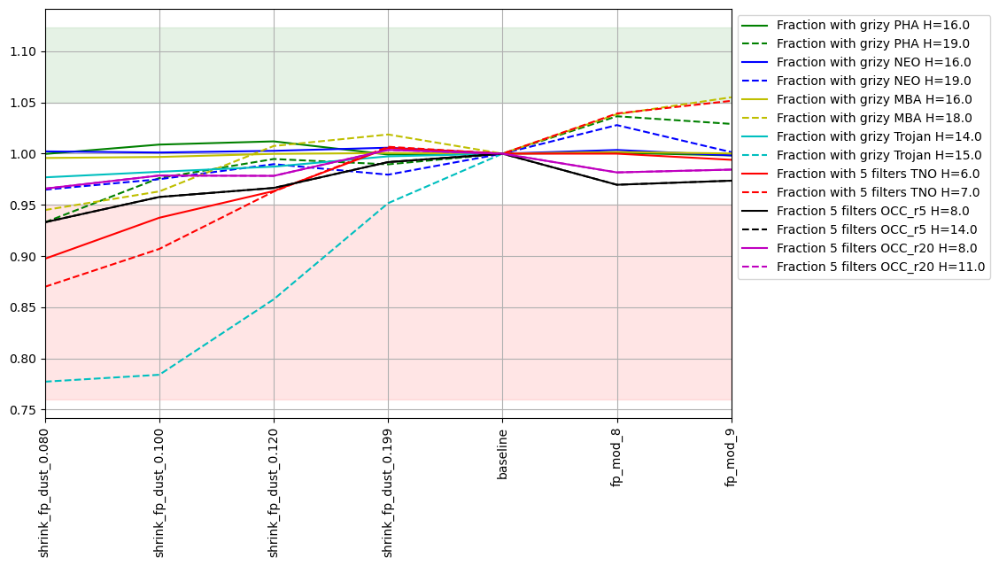

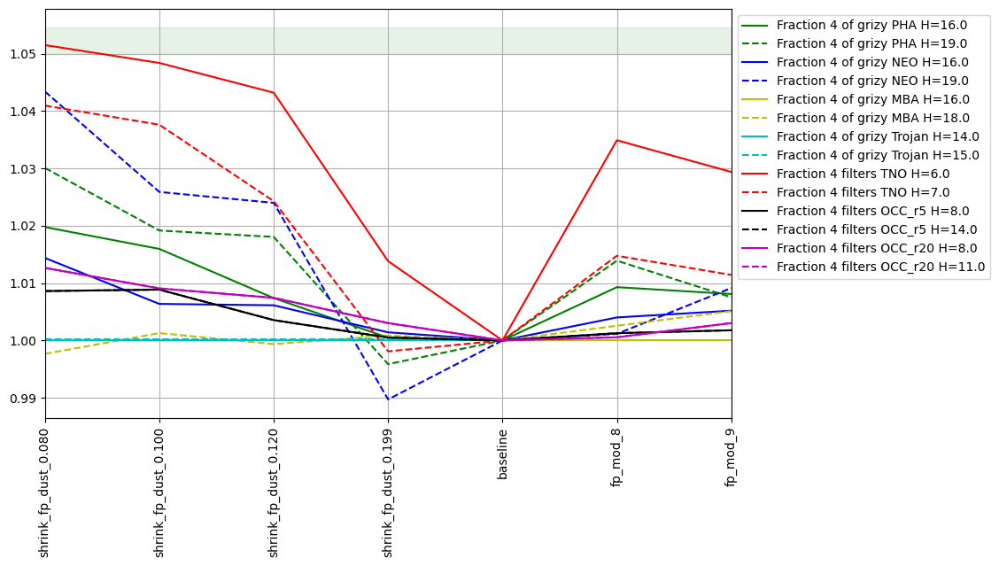

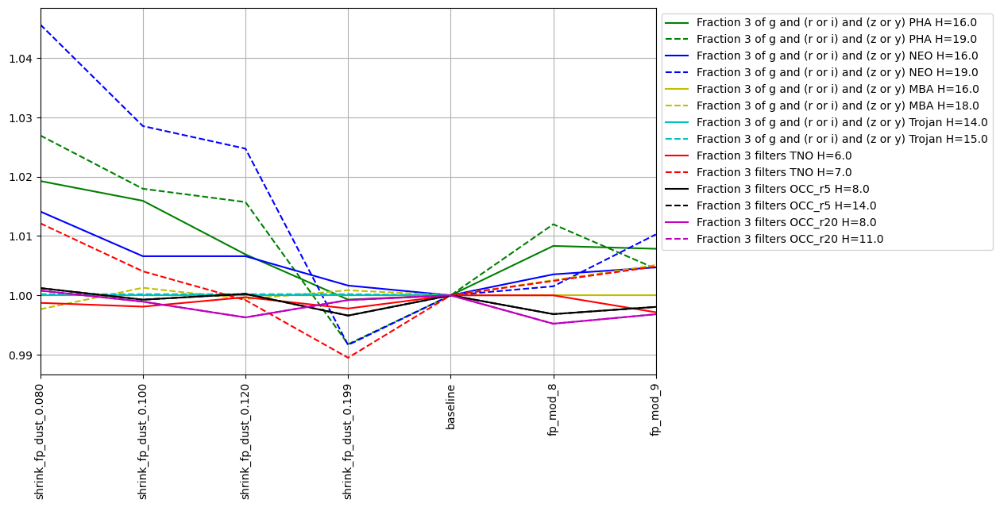

In [81]:
msub = metrics.loc['SSO discovery']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

msub = metrics.loc['SSO discovery'][::2]

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub, sep_plots=False)
fig.savefig(os.path.join(outdir, 'completeness_bright' + '.png'), format='png')

msub = metrics.loc['SSO discovery'][1::2]
fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub, sep_plots=False)
fig.savefig(os.path.join(outdir, 'completeness_faint' + '.png'), format='png')


msub = metrics.loc['SSO lightcurve inversion']
fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')


msub = metrics.loc['SSO lightcurve inversion'][1::2]
fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub, sep_plots=False)
fig.savefig(os.path.join(outdir, 'lightcurves_faint' + '.png'), format='png')


msub = metrics.loc['SSO fraction 6 bands']
fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

msub = metrics.loc['SSO fraction 6 bands'][::2]
fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub, sep_plots=False)
fig.savefig(os.path.join(outdir, 'colors6_bright' + '.png'), format='png')

msub = metrics.loc['SSO fraction 6 bands'][1::2]
fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub, sep_plots=False)
fig.savefig(os.path.join(outdir, 'colors6_faint' + '.png'), format='png')

msub = metrics.loc['SSO fraction 5 bands']
fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

msub = metrics.loc['SSO fraction 4 bands']
fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

msub = metrics.loc['SSO fraction 3 bands']
fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

### AGN
<a id="AGN"></a>
Metrics contributed by the Active Galactic Nuclei science collaboration.

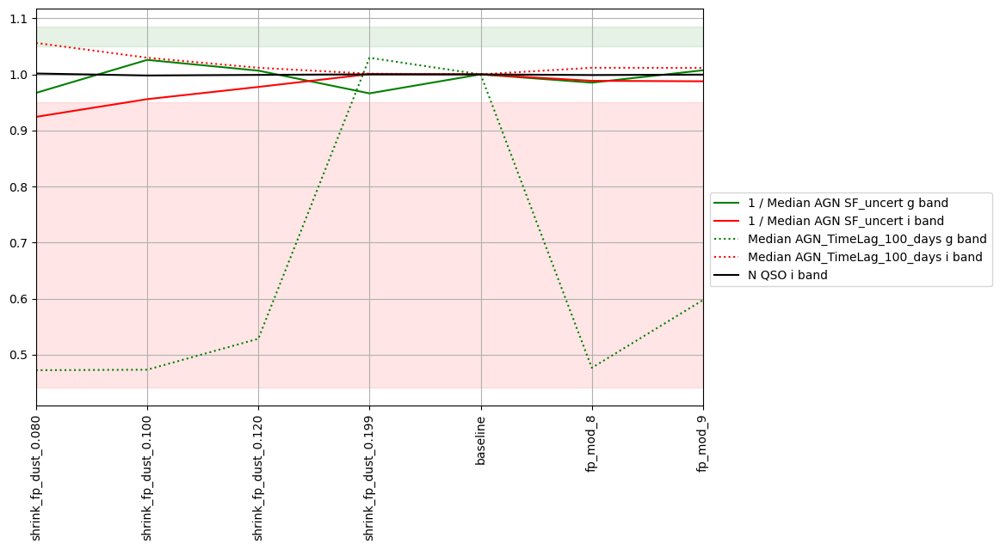

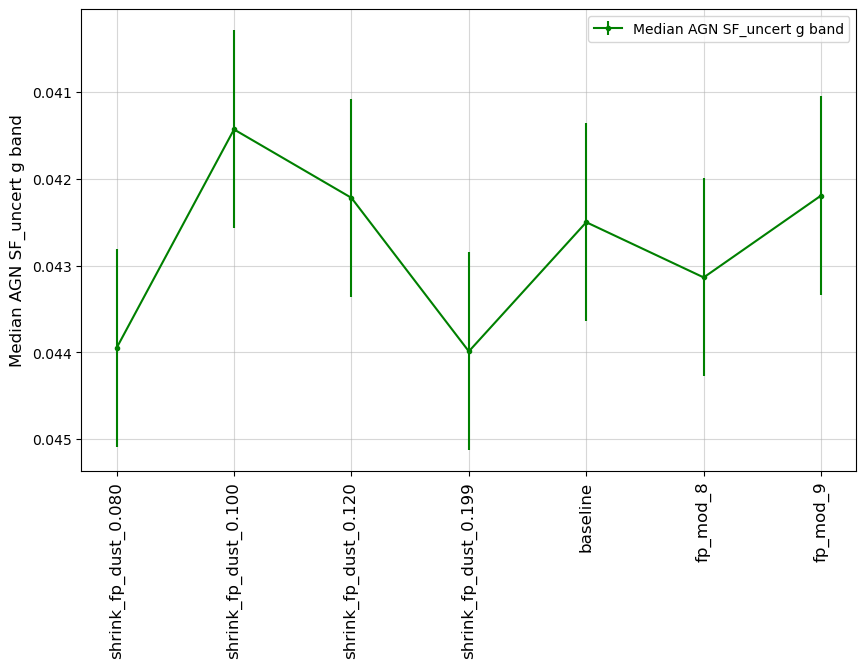

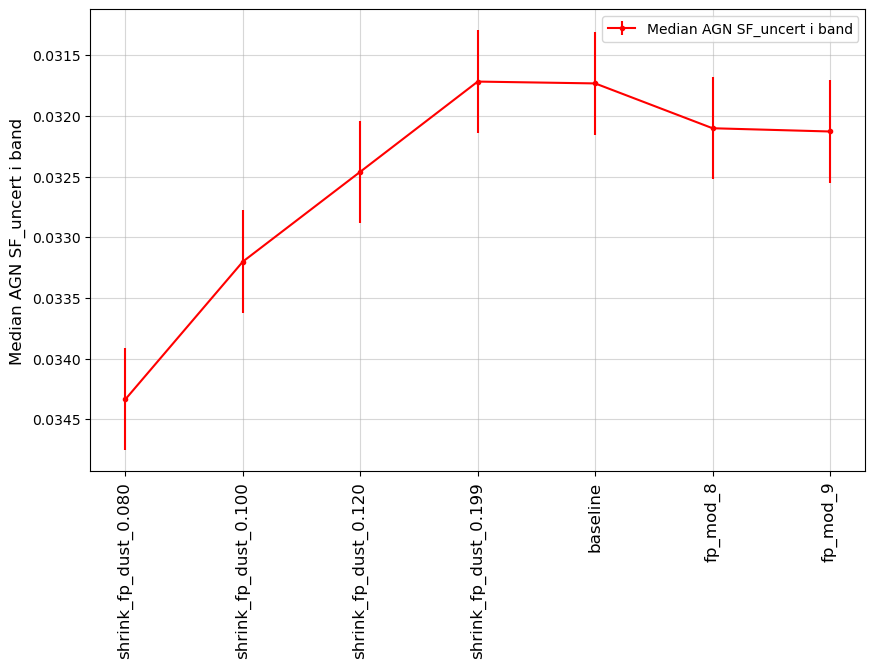

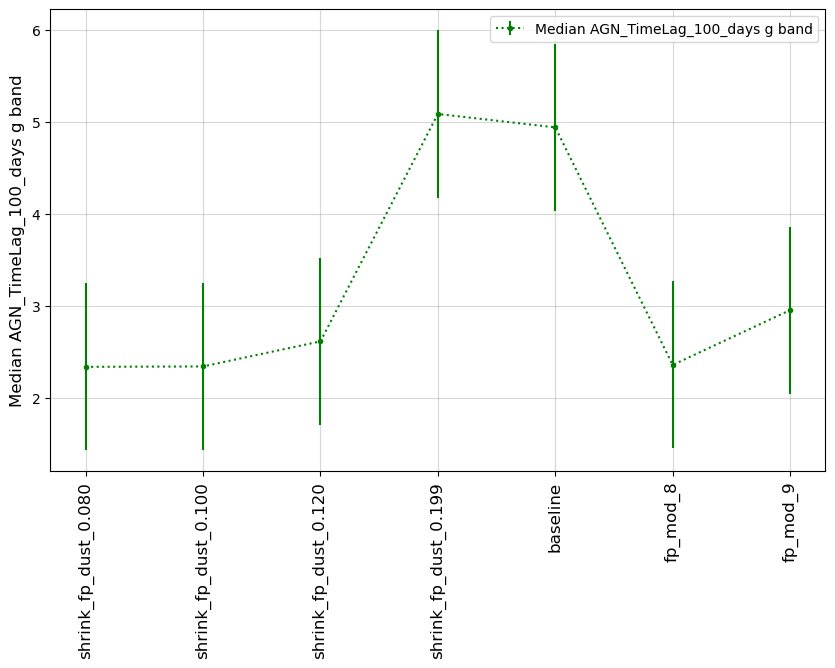

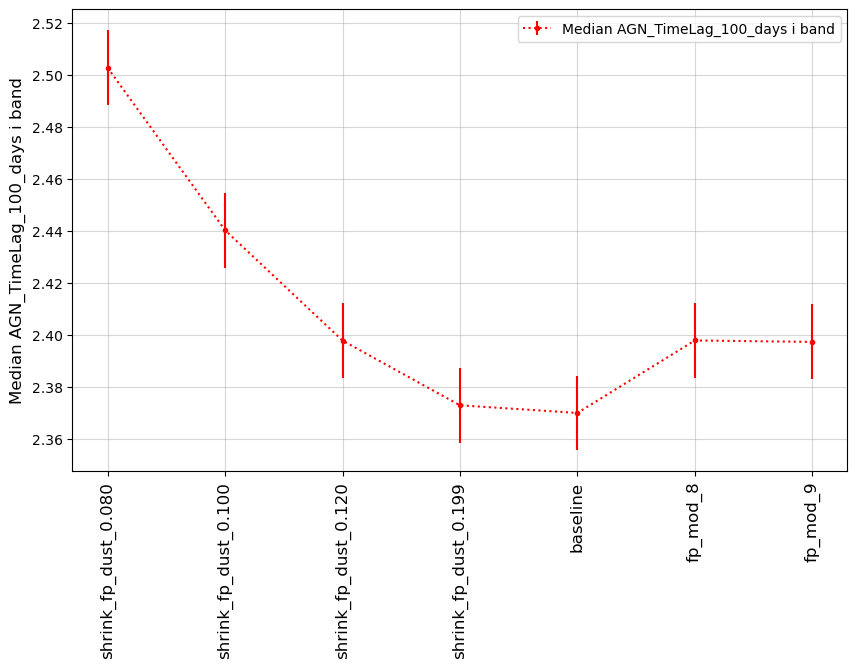

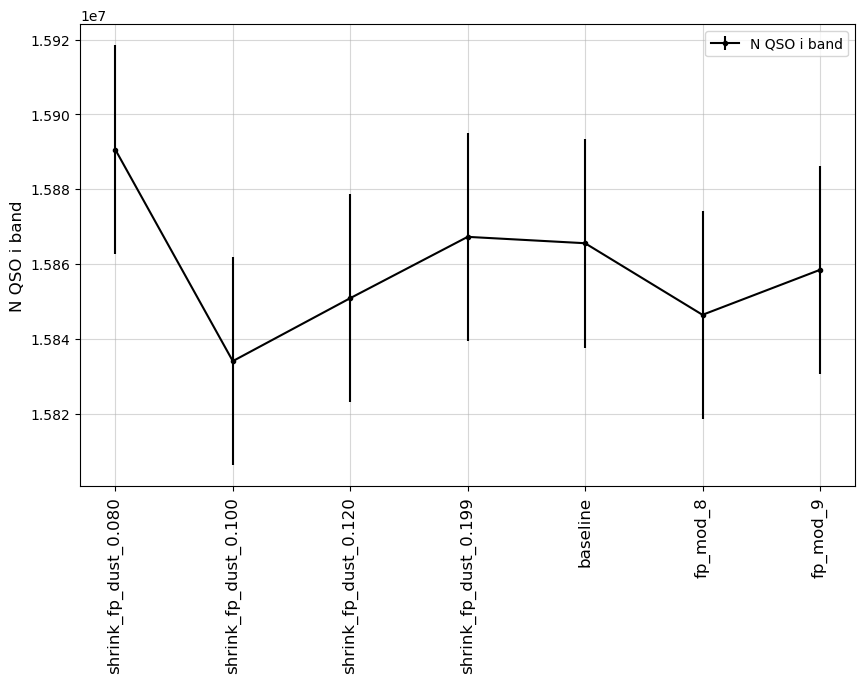

In [82]:
msub = metrics.loc['AGN short']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')
ax.legend(loc=(1.01, 0.3))
              
fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub, sep_plots=True)

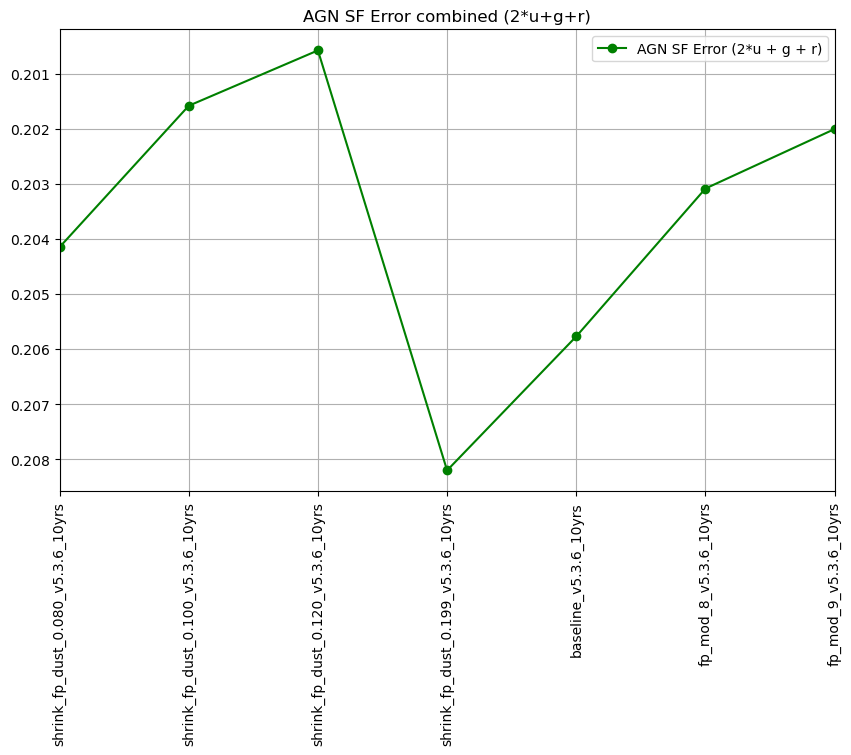

In [83]:
msub  = metrics.loc['AGN SF']
u = msub.iloc[0:1]
g = msub.iloc[1:2]
r = msub.iloc[2:3]
agn_sf = pd.DataFrame(summaries.loc[runs, u['metric']].values * 2 
                      + summaries.loc[runs, g['metric']].values * 1 
                      + summaries.loc[runs, r['metric']].values * 1,
                      columns=['AGN SF Error (2*u + g + r)'], index=runs)

fig, ax = maf.plot_run_metric(agn_sf, shade_fraction=None, linestyles='-',
                            vertical_quantity='value', horizontal_quantity='run')
ylim = ax.set_ylim()
ax.set_ylim(ylim[1], ylim[0])
_ = plt.title("AGN SF Error combined (2*u+g+r)")

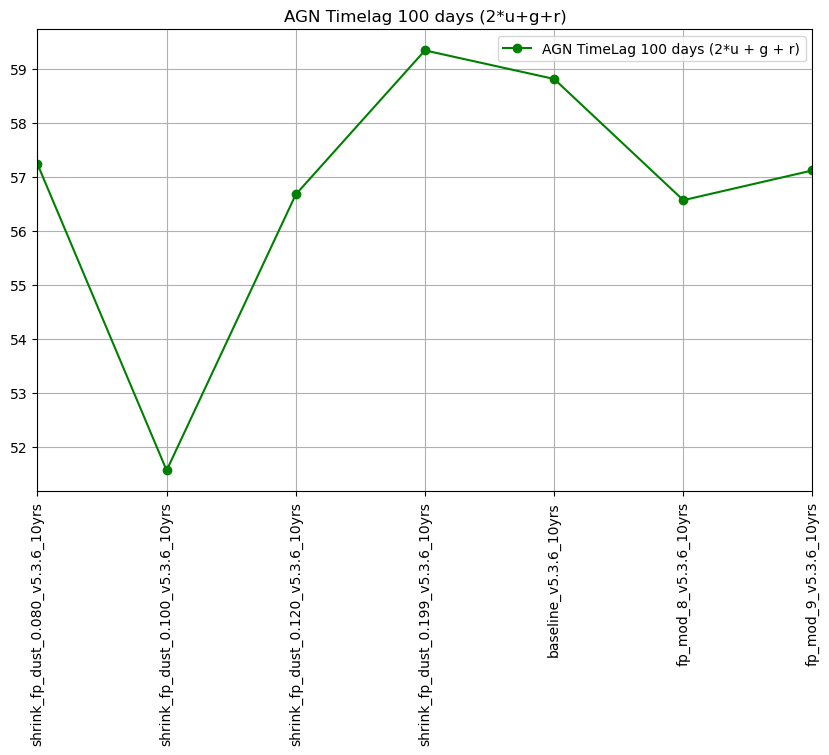

In [84]:
msub  = metrics.loc['AGN timelag']
msub = msub.query('metric.str.contains("100")')
u = msub.iloc[0:1]
g = msub.iloc[1:2]
r = msub.iloc[2:3]
agn_sf = pd.DataFrame(summaries.loc[runs, u['metric']].values * 2 
                      + summaries.loc[runs, g['metric']].values * 1 
                      + summaries.loc[runs, r['metric']].values * 1,
                      columns=['AGN TimeLag 100 days (2*u + g + r)'], index=runs)

fig, ax = maf.plot_run_metric(agn_sf, shade_fraction=None, linestyles='-',
                            vertical_quantity='value', horizontal_quantity='run')
ylim = ax.set_ylim()
_ = plt.title("AGN Timelag 100 days (2*u+g+r)")

### Galaxies
<a id="Galaxies"></a>
Metrics evaluating the total number of galaxies expected in the survey.

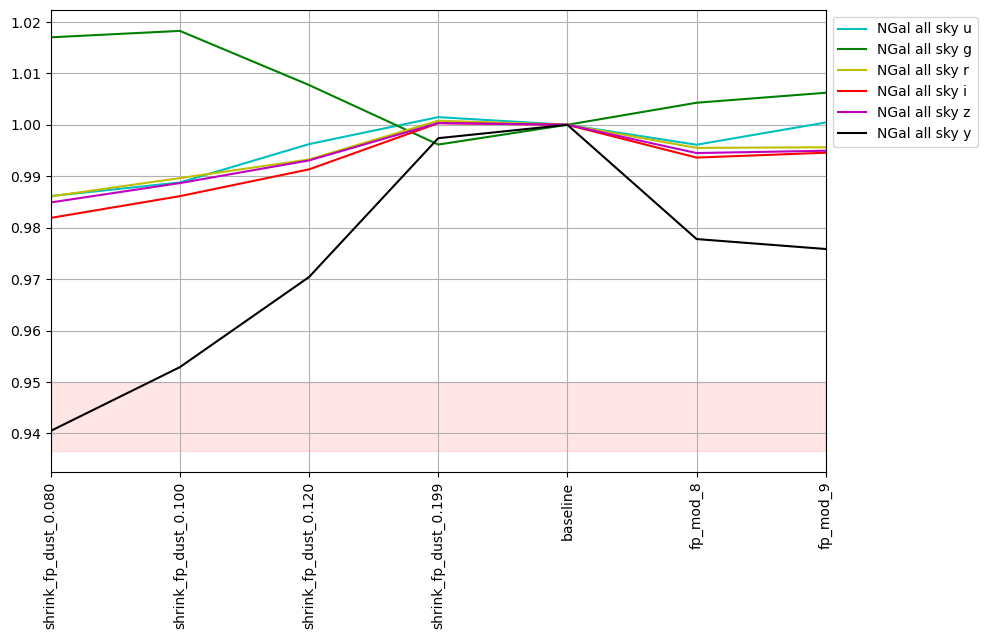

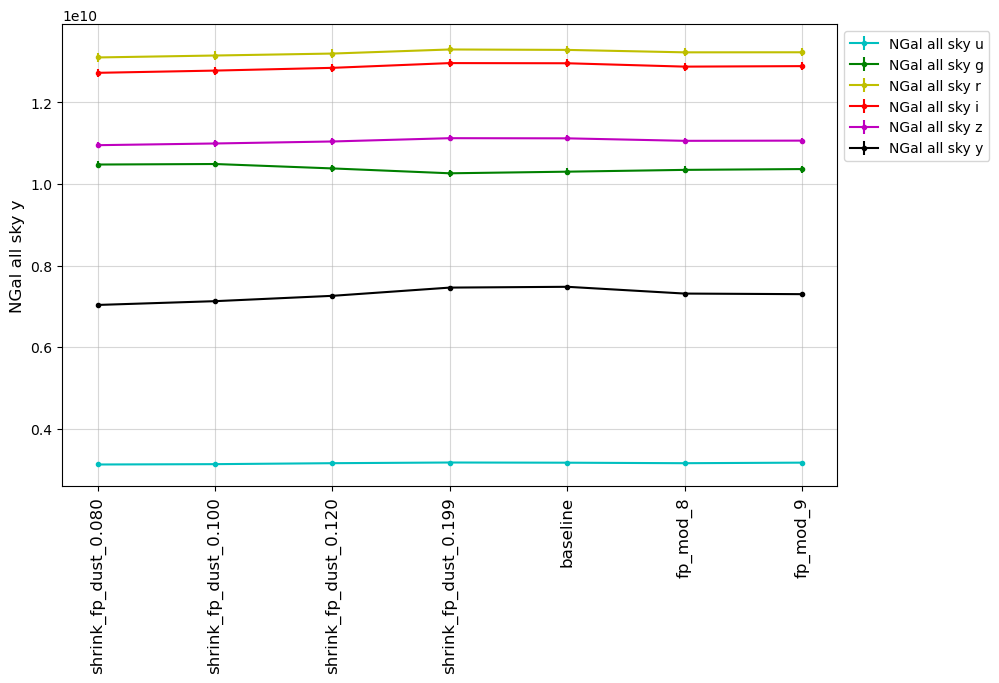

In [85]:
msub = metrics.loc['galaxies']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub, sep_plots=False)

### Strong Lensing
<a id="StrongLensing"></a>
Metrics contributed by the Strong Lensing Science Collaboration. 

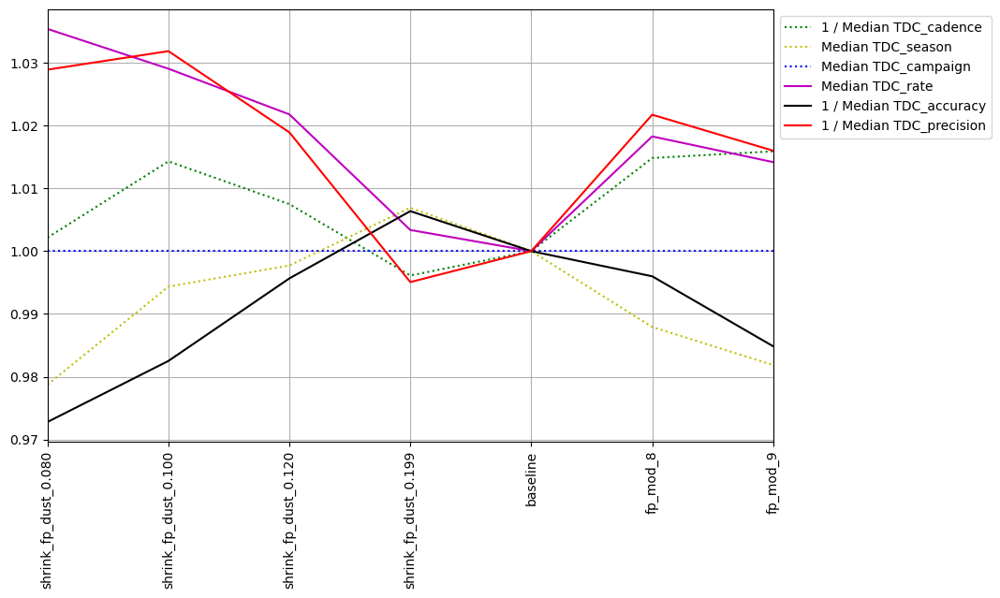

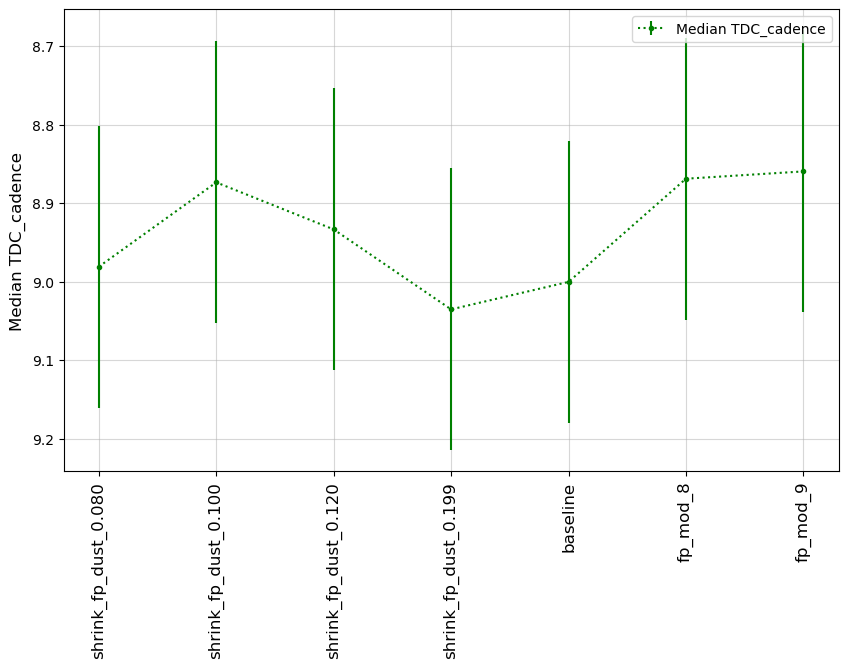

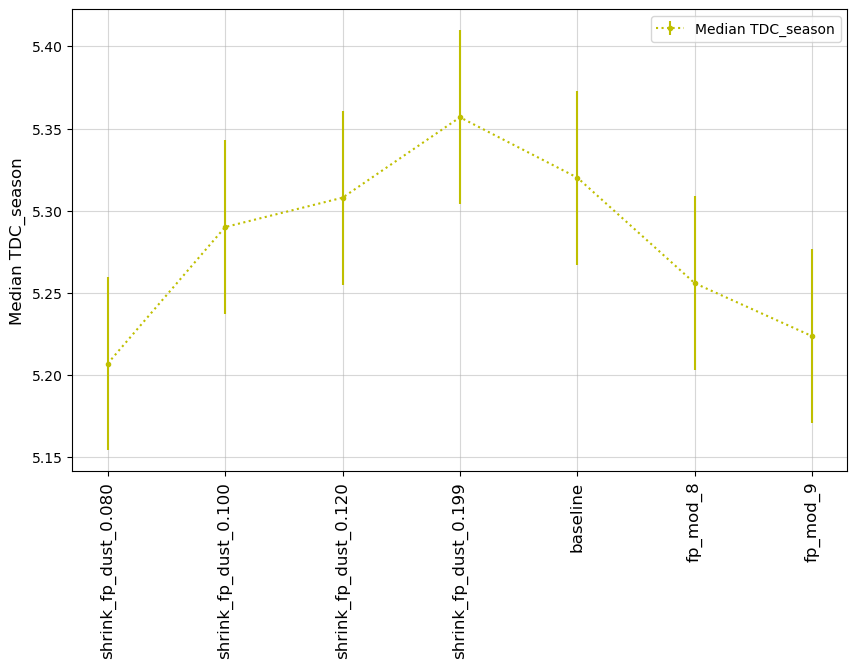

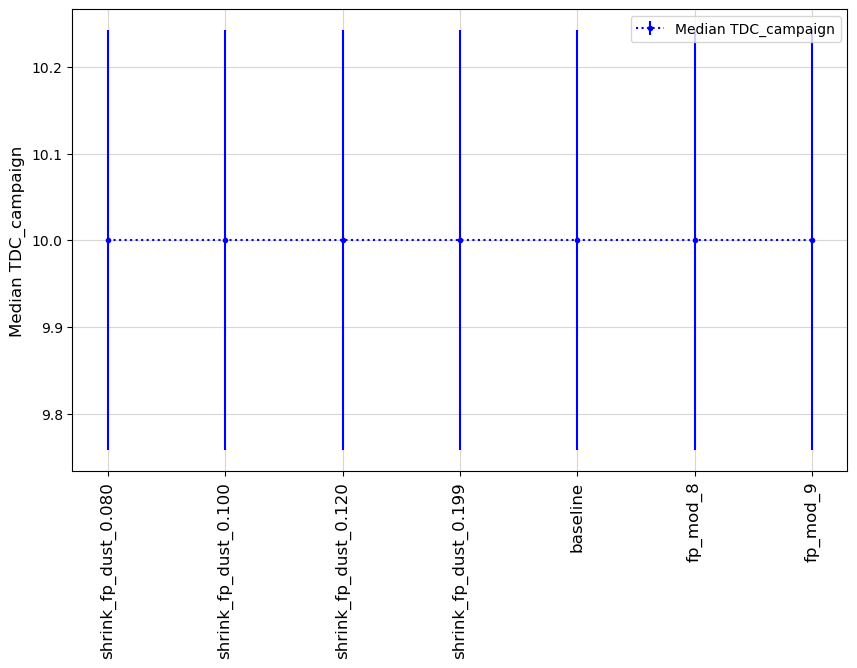

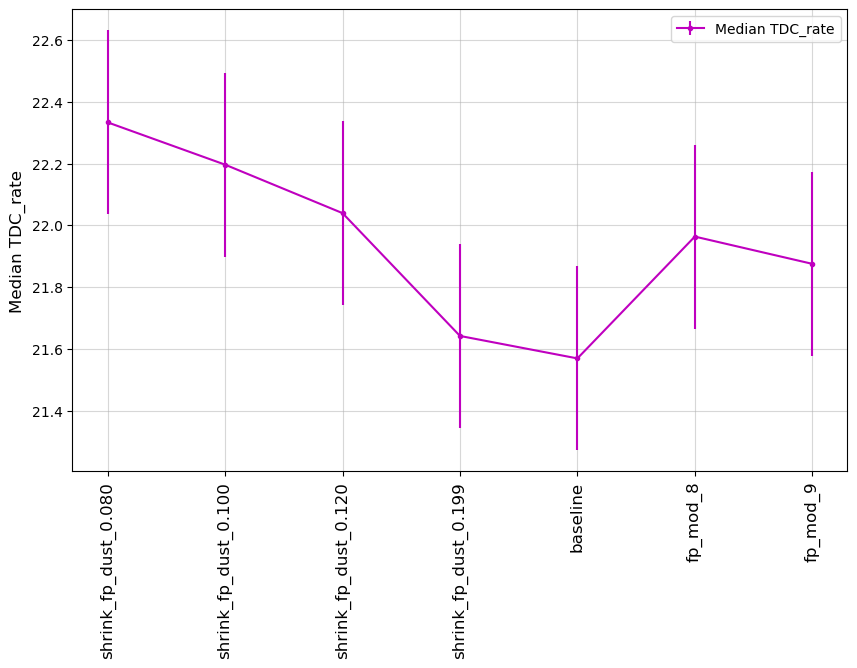

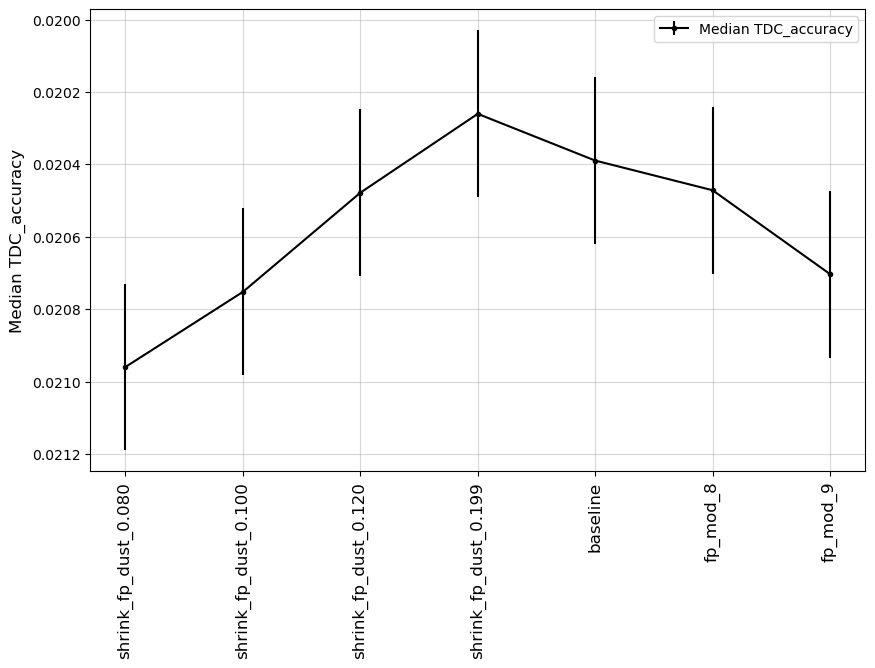

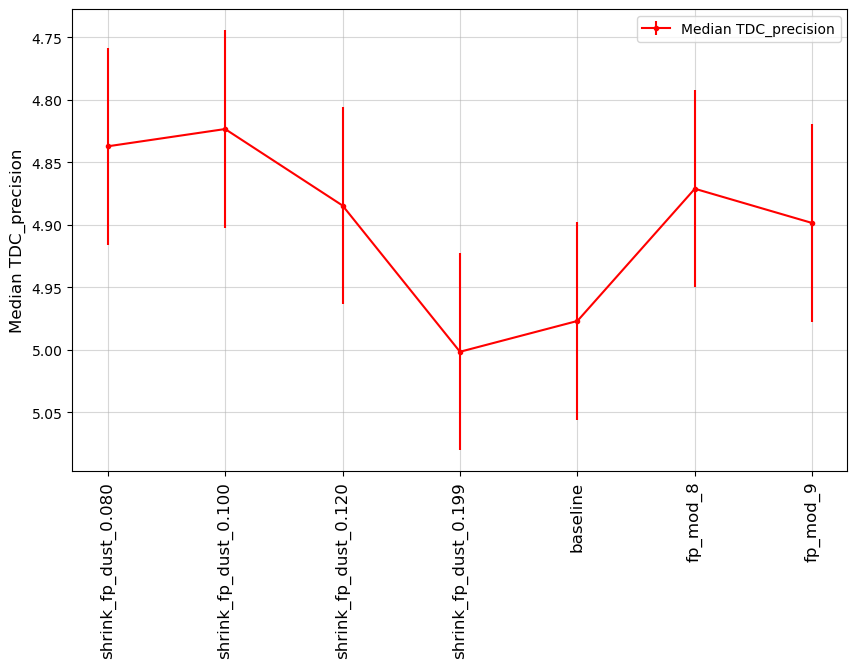

In [86]:
msub = metrics.loc['SL TDC']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub, sep_plots=True)

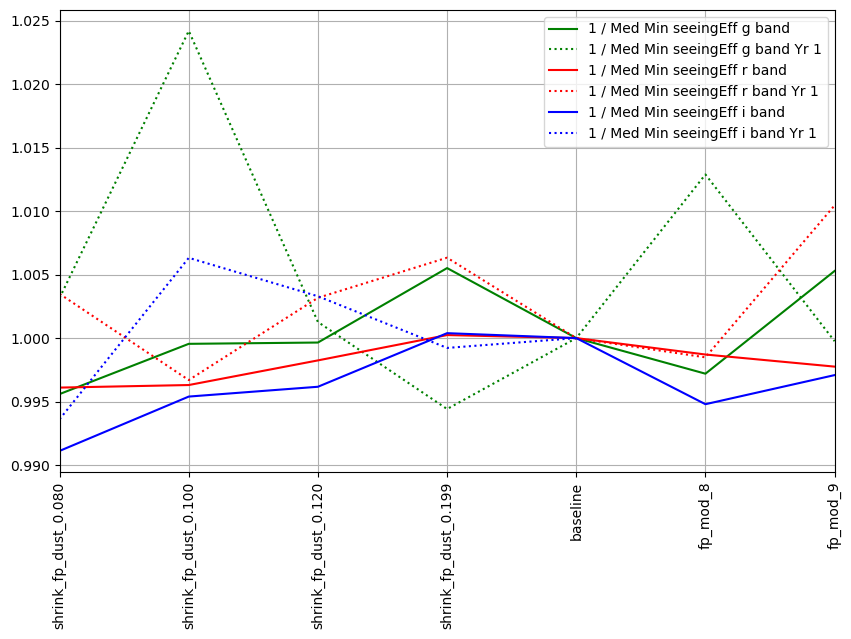

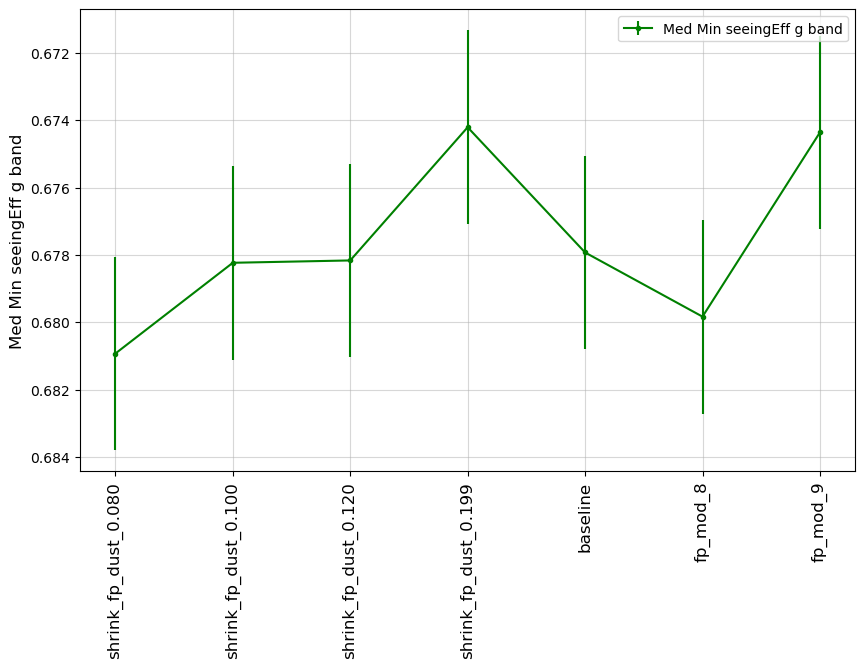

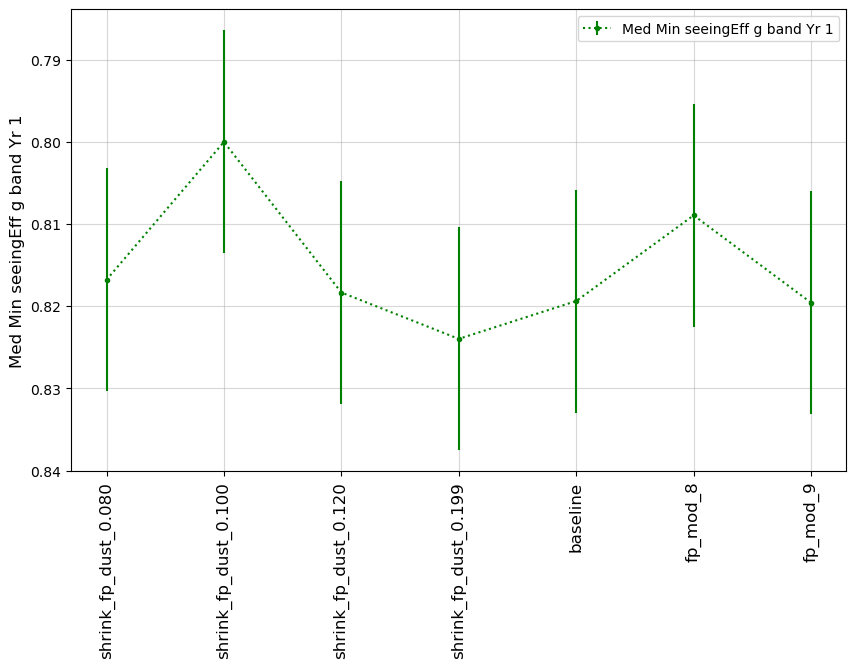

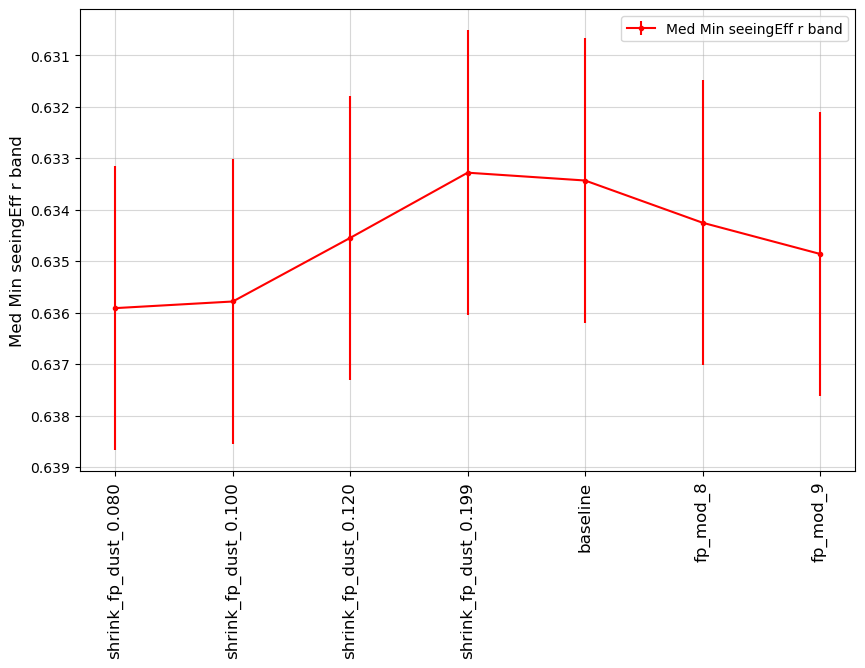

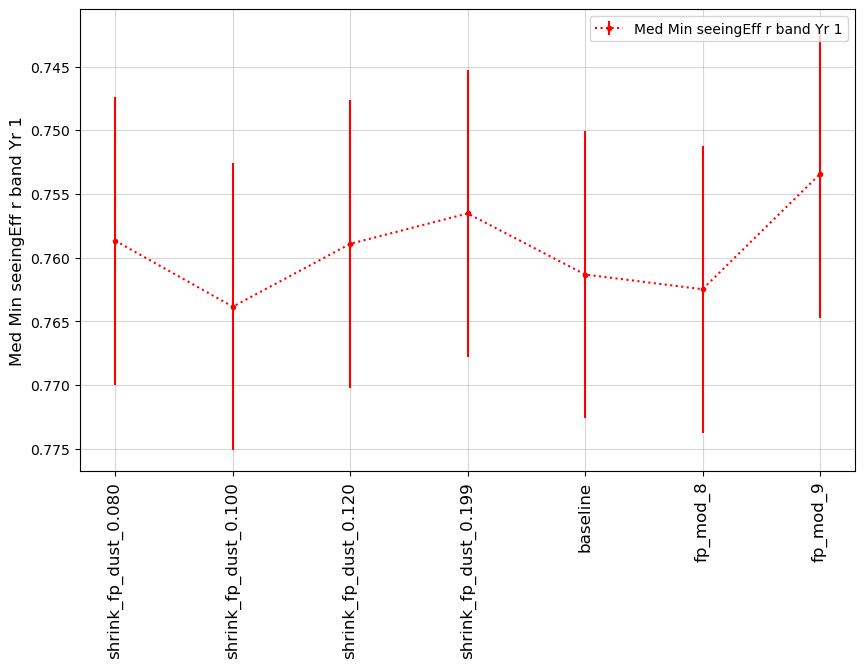

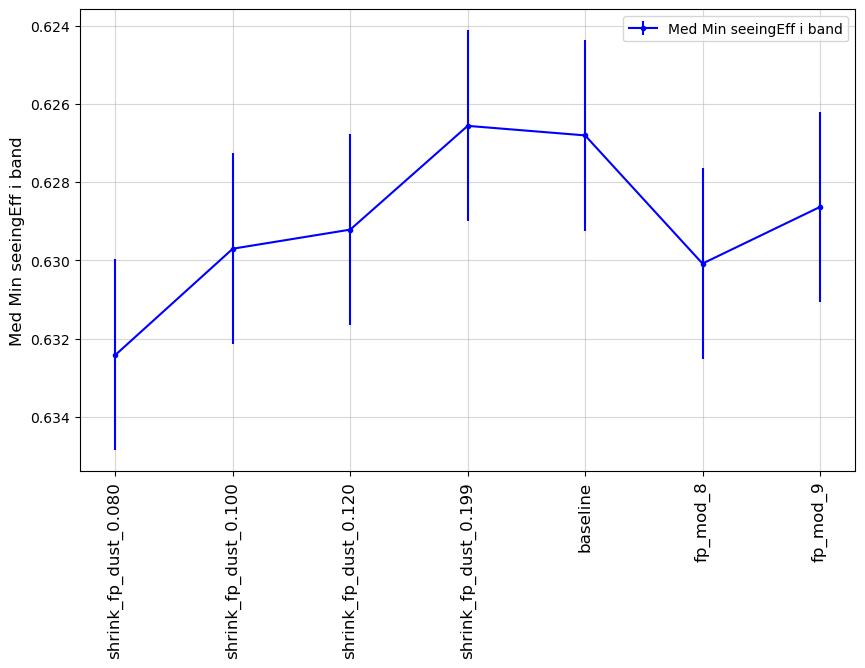

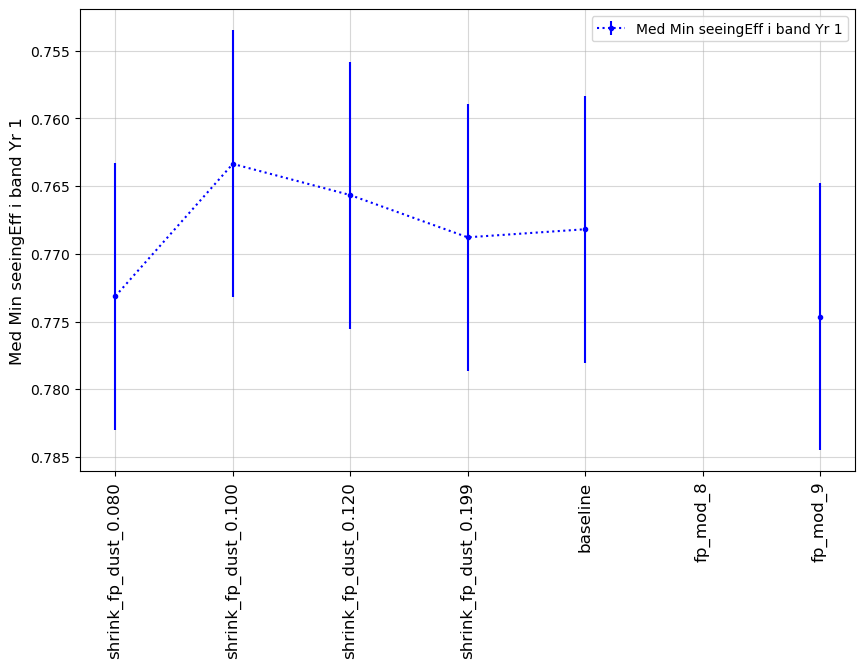

In [87]:
msub = metrics.loc['SL IQ']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline,
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub, sep_plots=True)

### Stars
<a id="Stars"></a>
Metrics considering total number of stars available in the survey. 

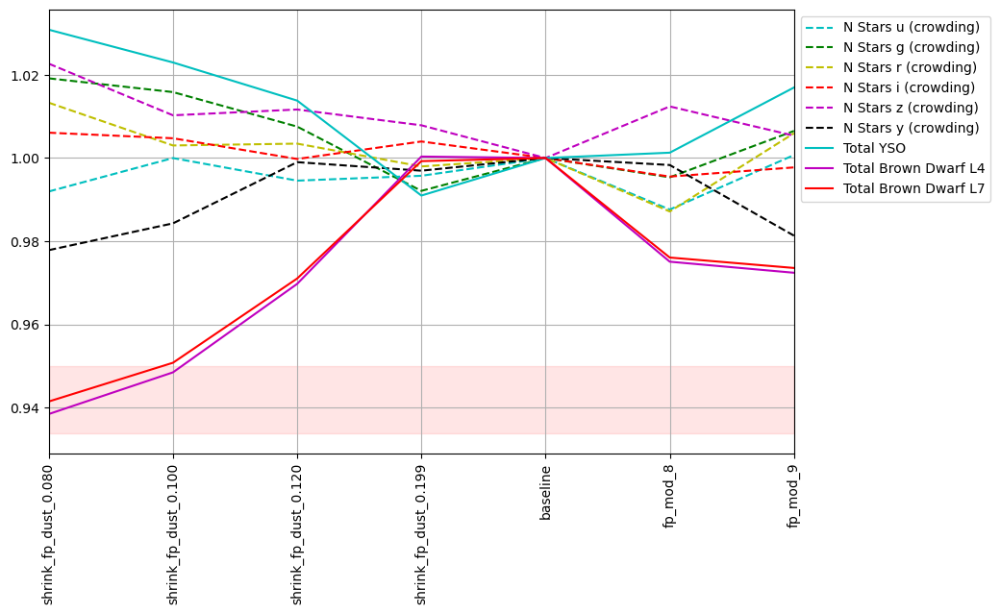

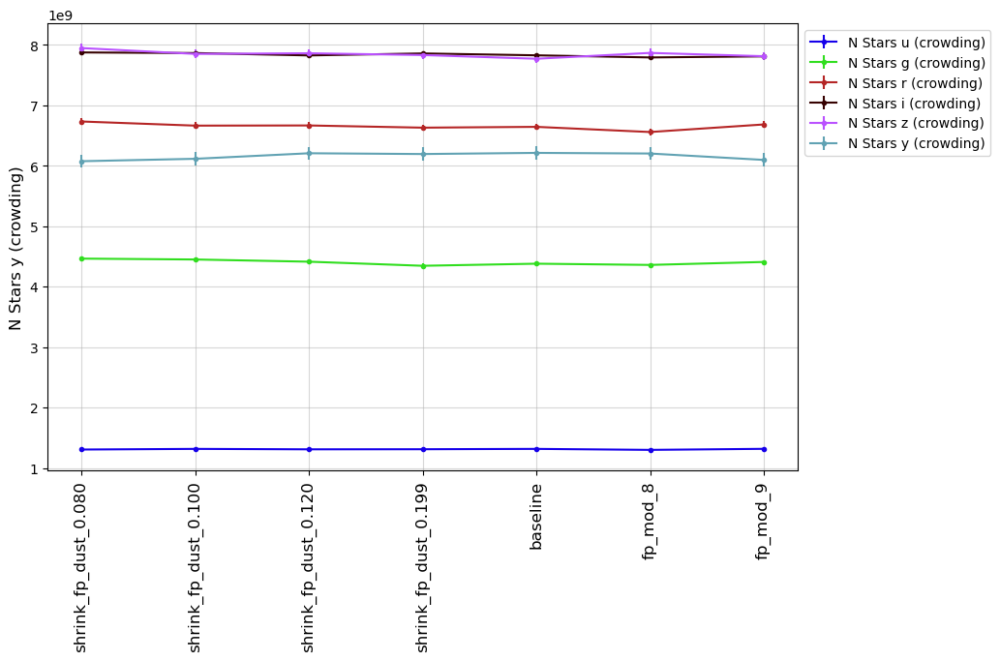

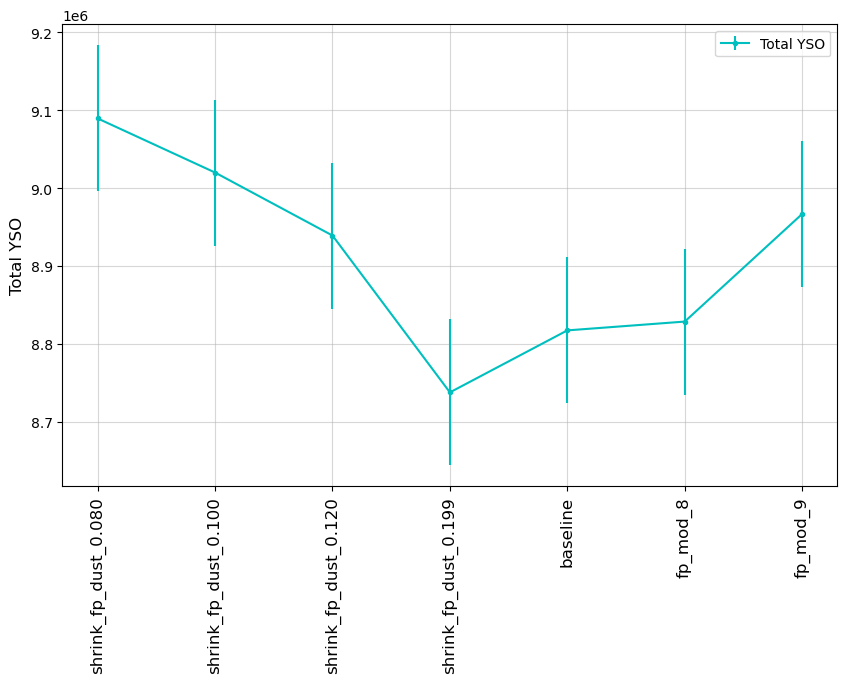

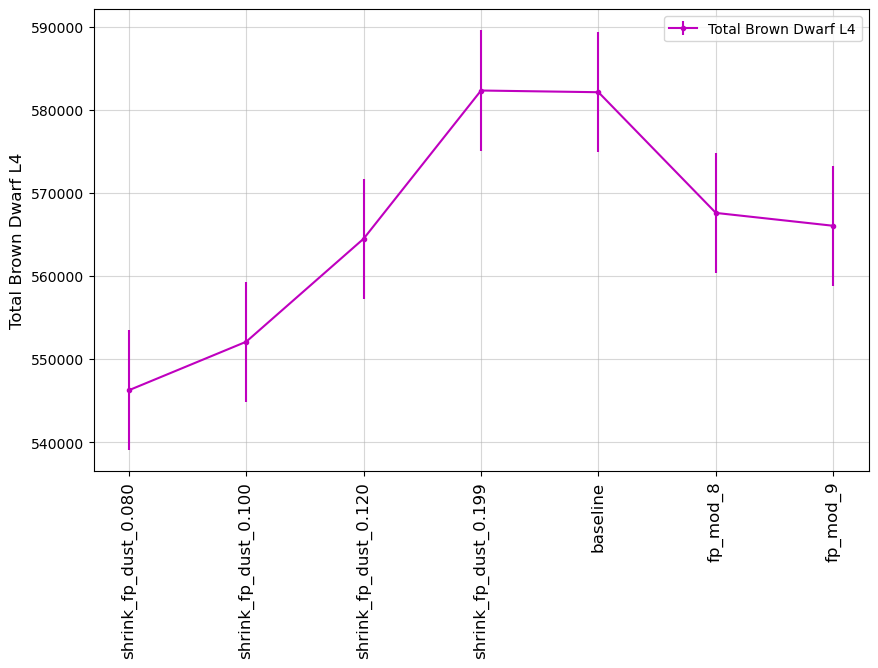

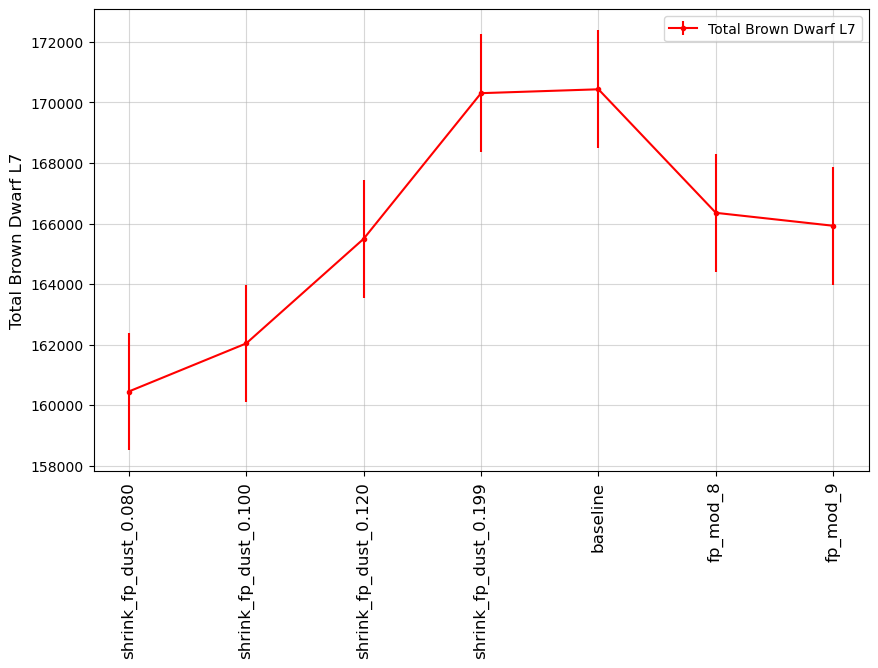

In [88]:
msub = metrics.loc['Stars']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

msub = metrics.loc['Stars'][0:6]
fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 cmap=filter_color_map,
                                 metric_subset=msub, sep_plots=False)

msub = metrics.loc['Stars'][6:]
fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub, sep_plots=True)

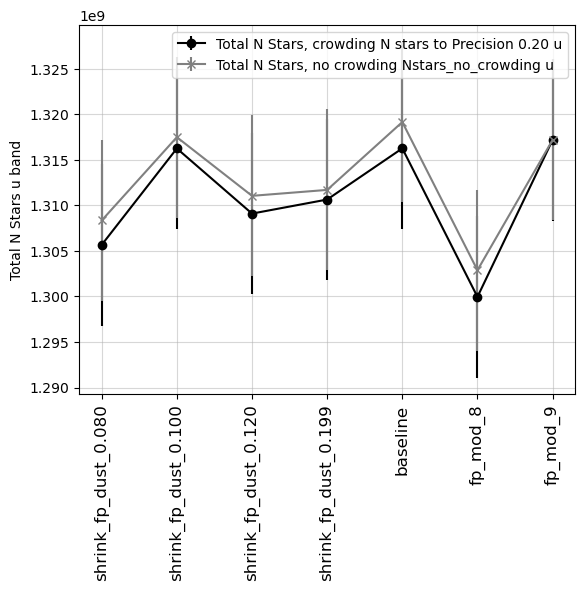

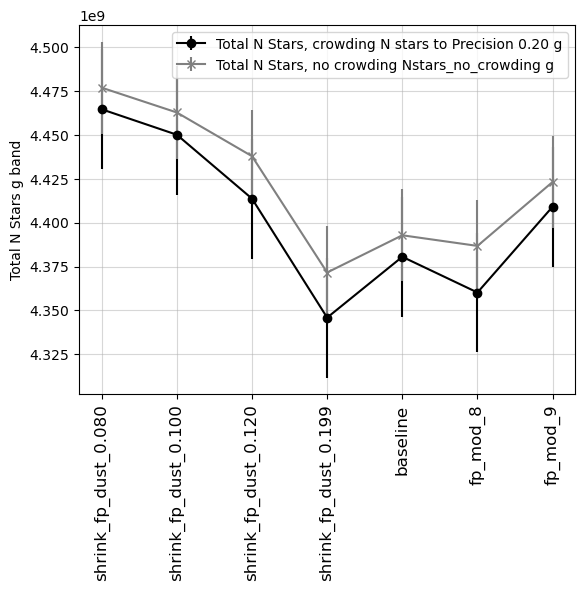

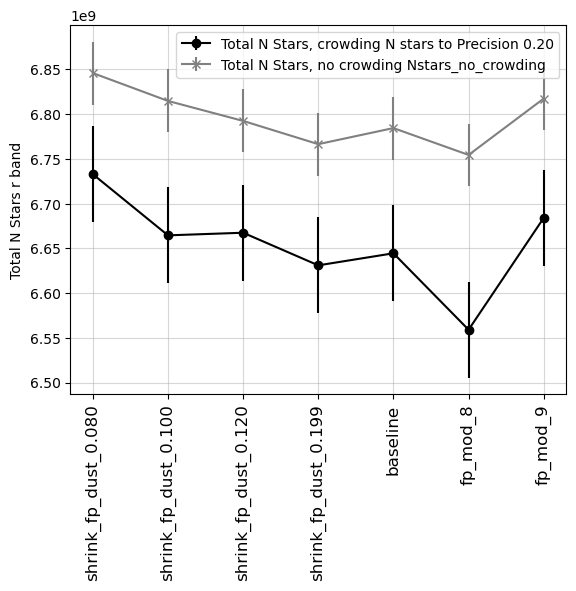

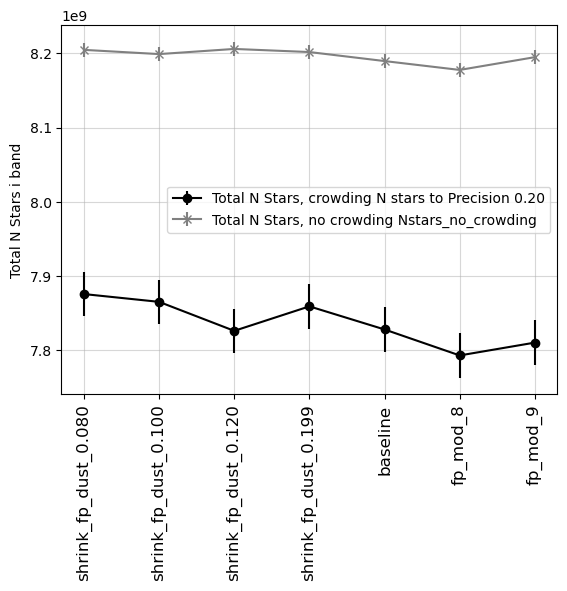

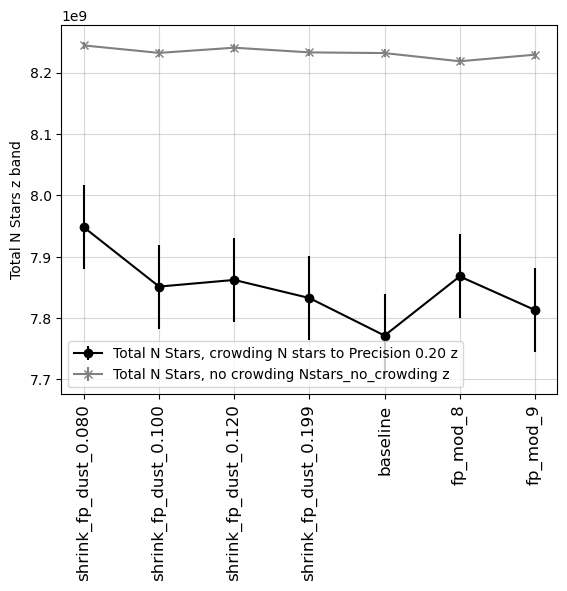

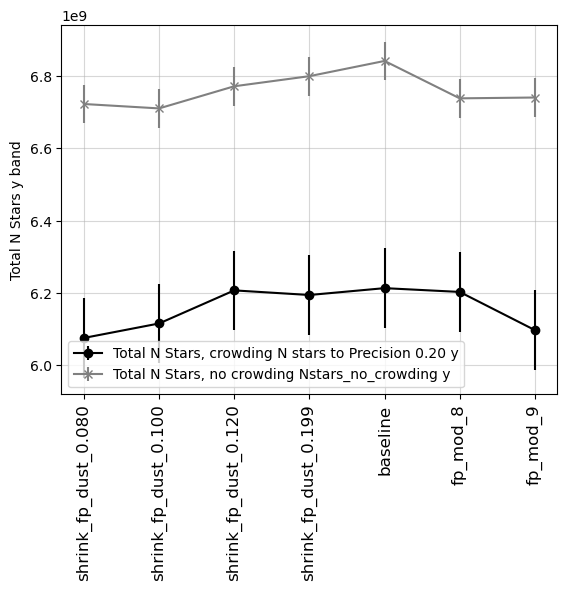

In [91]:
for f in 'ugrizy':
    mm = [m for m in summaries if "Total N Stars" in m and f" {f} " in m]
    fig, ax = plt.subplots()
    for m, marker, color in zip(mm, ['o', 'x'], ['black', 'gray']):
        ax.errorbar(list(rdict.values()), summaries.loc[runs, m], yerr=dev[m], 
                    color=color, marker=marker, linestyle='-', label=m.rstrip(' HealpixSlicer'))
    ax.legend()
    ax.set_ylabel(f"Total N Stars {f} band")
    ax.tick_params(axis='x', labelrotation = 90, labelsize='large')
    ax.grid(True, alpha=0.5)

### Milky Way & Local Volume 
<a id="MWLV"></a>
Metrics for the local volume and milky way. These metrics tend to have a focus on galactic plane coverage, south celestial pole or SMC & LMC coverage. 


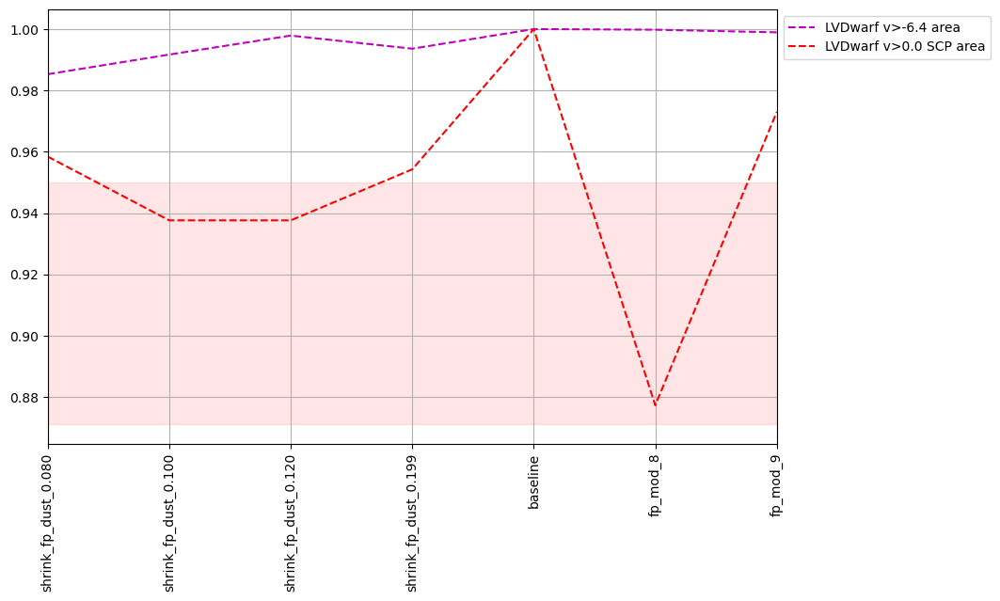

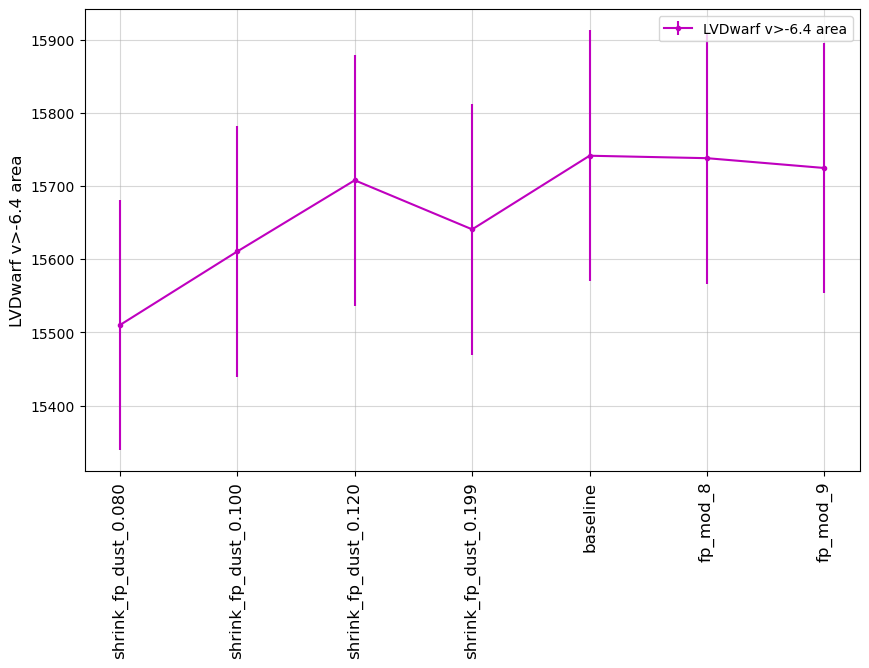

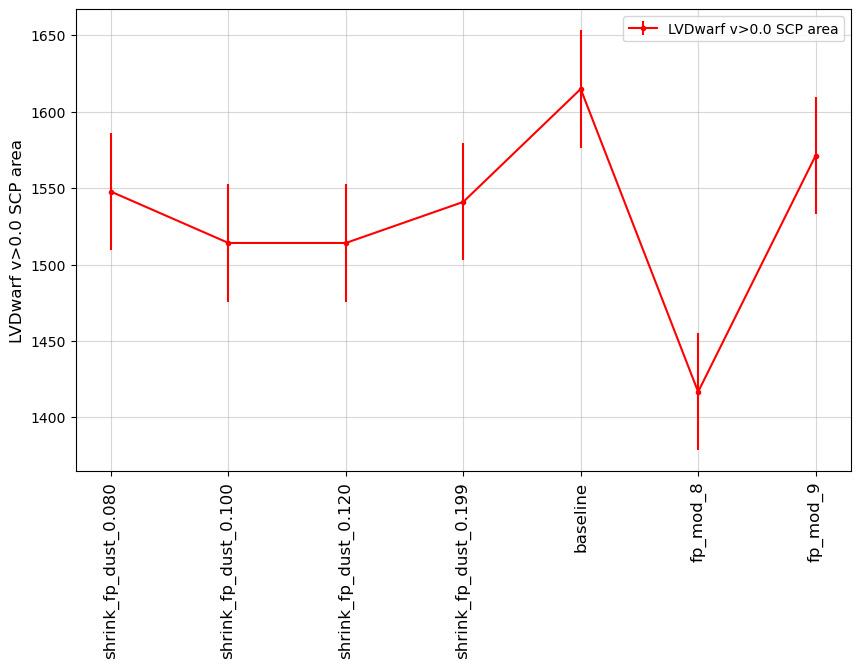

In [92]:
msub = metrics.loc['Local Volume']

fig, ax = maf.plot_run_metric(summaries.loc[runs, msub['metric']], 
                              baseline_run=baseline, 
                              metric_subset=msub,
                              metric_label_map=msub['short_name'],
                              run_label_map=rdict,
                              horizontal_quantity='run',
                              vertical_quantity='value')

fig, ax = maf.plot_run_metric_uncert(summaries.loc[runs, msub['metric']], 
                                 dev[msub['metric']], 
                                 metric_label_map=msub['short_name'], 
                                 run_label_map=rdict,
                                 metric_subset=msub, sep_plots=True)

metric,Identity Number of Exposures UniSlicer,Identity Counts_DD:COSMOS UniSlicer,Identity Counts_DD:ECDFS UniSlicer,Identity Counts_DD:EDFS_a UniSlicer,Identity Counts_DD:EDFS_b UniSlicer,Identity Counts_DD:ELAISS1 UniSlicer,Identity Counts_DD:XMM_LSS UniSlicer
run,,,,,,,
shrink_fp_dust_0.080_v5.3.6_10yrs,1820414.0,45014.0,23207.0,14515.0,14156.0,17805.0,18688.0
shrink_fp_dust_0.100_v5.3.6_10yrs,1818612.0,45058.0,23164.0,14494.0,14144.0,17843.0,18730.0
shrink_fp_dust_0.120_v5.3.6_10yrs,1816783.0,45035.0,23181.0,14517.0,14152.0,17826.0,18686.0
shrink_fp_dust_0.199_v5.3.6_10yrs,1817343.0,45098.0,23178.0,14531.0,14212.0,17853.0,18741.0
baseline_v5.3.6_10yrs,1817070.0,45044.0,23187.0,14516.0,14187.0,17836.0,18730.0
fp_mod_8_v5.3.6_10yrs,1816840.0,45151.0,23207.0,14511.0,14132.0,17859.0,18694.0
fp_mod_9_v5.3.6_10yrs,1817179.0,45036.0,23189.0,14511.0,14175.0,17833.0,18721.0


Percent of visits in DDF


run
shrink_fp_dust_0.080_v5.3.6_10yrs    7.33
shrink_fp_dust_0.100_v5.3.6_10yrs    7.34
shrink_fp_dust_0.120_v5.3.6_10yrs    7.34
shrink_fp_dust_0.199_v5.3.6_10yrs    7.35
baseline_v5.3.6_10yrs                7.35
fp_mod_8_v5.3.6_10yrs                7.35
fp_mod_9_v5.3.6_10yrs                7.34
dtype: float64

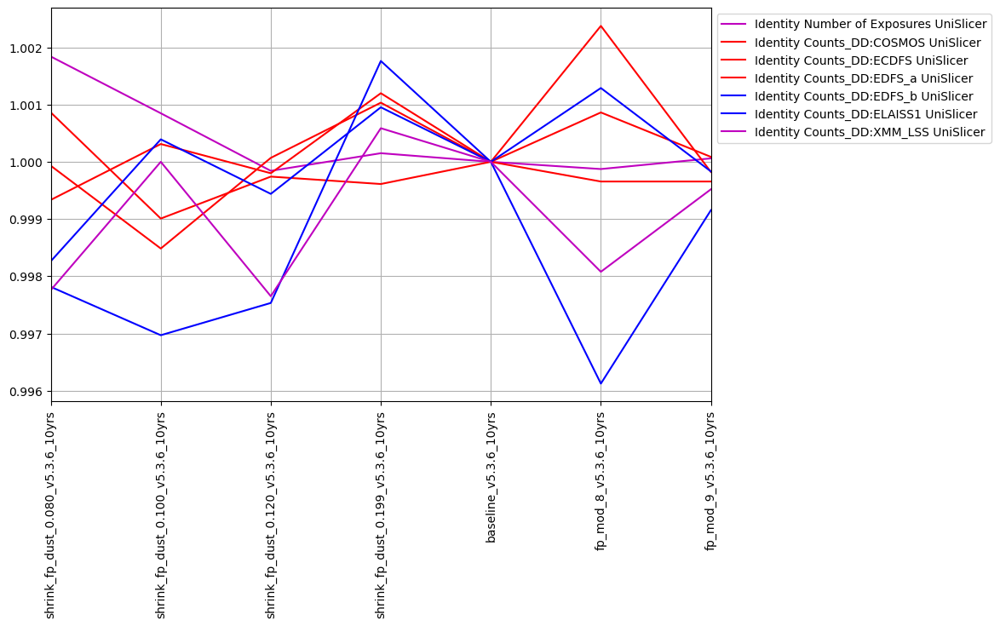

In [93]:
# First let's check the total number of visits in the DDFS, 
# as this has a significant impact on the depths and everything else. 
count_metrics = ['Identity Number of Exposures UniSlicer', 'Identity Counts_DD:COSMOS UniSlicer',
 'Identity Counts_DD:ECDFS UniSlicer',
 #'Identity Counts_DD:EDFS, a UniSlicer',
 #'Identity Counts_DD:EDFS, b UniSlicer',
 'Identity Counts_DD:EDFS_a UniSlicer',
 'Identity Counts_DD:EDFS_b UniSlicer',
 'Identity Counts_DD:ELAISS1 UniSlicer',
 #'Identity Counts_DD:XMM-LSS UniSlicer',
 'Identity Counts_DD:XMM_LSS UniSlicer']

fig, ax = maf.plot_run_metric(summaries.loc[runs, count_metrics],
                             baseline_run=baseline,
                              linestyles='-',
                              markers=[''],
                             horizontal_quantity='run',
                             vertical_quantity='value',
                             shade_fraction=.05)
#ax.set_ylim(0.3, 1.8)

display(summaries.loc[runs, count_metrics])

print("Percent of visits in DDF")
display((100*summaries.loc[runs, count_metrics[1:]].sum(axis=1)/summaries.loc[runs, count_metrics[0]]).round(2))